# DSAA2011 Course Project (Task A) — *"From Weather Snapshots to Seasonal Climate Signatures"*
## Recovering Australia's climate zones from weather observations alone

**Question.** How much of an externally assigned climate zone can be recovered from weather when a single day is
treated as a baseline and four seasonal windows are combined into an annual weather-pattern proxy?

| Step | Question it answers |
|---|---|
| Parts 1–5 Mandatory tasks | Preprocess, visualise, cluster and predict with the required daily-weather baseline. |
| Part 6 History sensitivity | How does the answer change with trailing history, feature engineering and model flexibility? |
| Part 7 Main exploration | Do four seasonal weather windows recover climate-zone information more faithfully? |

**Target (`Zone`, 5 classes)** is derived from the Köppen-Geiger classification of each station
(groups A and B kept whole, group C split into Cfa / Cs / Cfb). See Section 0.2.

## 0. Setup

In [1]:
import hashlib
import io
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42                      # one seed for every split / sample / model in the notebook
DATA_DIR = Path("data")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RAW_CSV = DATA_DIR / "raw" / "weatherAUS.csv"   # Kaggle: jsphyg/weather-dataset-rattle-package, version 2
RAW_SHA256 = "573fd715cd69fcacc4df32024d823b450ae3edaae7e8ff2eeb623adbed424014"

ZONE_ORDER = ["Tropical", "Arid", "Subtropical", "Mediterranean", "Oceanic"]
ZONE_COLORS = {"Tropical": "#d62728", "Arid": "#e6a01e", "Subtropical": "#2ca02c",
               "Mediterranean": "#9467bd", "Oceanic": "#1f77b4"}
sns.set_theme(style="whitegrid", context="notebook")

def savefig(name):
    # every figure is also written to figures/ so the report and slides use the same image
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

# Cache identity includes executable notebook code, data/annotation and environment.
import pickle, json, os, platform, importlib.metadata, time
from threadpoolctl import threadpool_limits
_thread_limit = threadpool_limits(limits=2)
nb_file = Path("project_7_TaskA.ipynb")
nb_source = json.loads(nb_file.read_text(encoding="utf-8"))
code_digest = hashlib.sha256("\n".join("".join(c["source"]) for c in nb_source["cells"] if c["cell_type"] == "code").encode()).hexdigest()
file_digests = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in [RAW_CSV, DATA_DIR / "processed/location_zone.csv", DATA_DIR / "external/location_station.csv"]}
environment = {d.metadata["Name"]: d.version for d in importlib.metadata.distributions()}
identity = {"schema": "review-v2", "code_sha256": code_digest, "files": file_digests, "environment": environment, "python": platform.python_version()}
RUN_ID = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:16]
CACHE_DIR = DATA_DIR / "processed/audit_cache" / RUN_ID
CACHE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR = Path("results"); RESULT_DIR.mkdir(exist_ok=True)
RECOMPUTE = os.environ.get("ML_RECOMPUTE", "0") == "1"
CACHE_EVENTS = []
def cached(name, compute, **params):
    key = hashlib.sha256(repr(sorted(params.items())).encode()).hexdigest()[:12]
    path = CACHE_DIR / f"{name}_{key}.pkl"
    hit = path.exists() and not RECOMPUTE
    t0 = time.time()
    if hit:
        with path.open("rb") as stream: result = pickle.load(stream)
    else:
        result = compute()
        temp = path.with_suffix(".tmp")
        with temp.open("wb") as stream: pickle.dump(result, stream)
        temp.replace(path)
    CACHE_EVENTS.append({"name": name, "hit": hit, "seconds": time.time()-t0})
    print(f"cache {'hit' if hit else 'computed'}: {name} ({time.time()-t0:.1f}s)", flush=True)
    return result
def export_table(name, table):
    table.to_csv(RESULT_DIR / f"{name}.csv", index=True)
    return table
(RESULT_DIR / "environment.json").write_text(json.dumps(identity, indent=2, sort_keys=True), encoding="utf-8")
print("Experiment fingerprint:", RUN_ID)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Experiment fingerprint: f67d019ce7acf9e9
numpy 2.2.6 | pandas 2.3.3 | scikit-learn 1.7.2


### 0.2 Building the target: station → Köppen code → `Zone`

The dataset has no climate label, so we construct one from two documented sources:

1. **Station coordinates** — Bureau of Meteorology station list (product IDCJMC0014, downloaded 2026-11-09,
   stored in `data/external/`). Each `Location` was matched by hand to a BoM site number
   (`data/external/location_station.csv`).
2. **Köppen-Geiger code** — looked up with `kgcpy` 1.1.8, the Python port of the CRAN package `kgc`
   (Bryant, Wheeler, Rubel & French, 2017). Both packages ship a global 12960 × 6480 raster, i.e. 100 arc-seconds
   (≈ 3 km) per pixel, and cite Rubel et al. (2017, *Meteorol. Z.* 26:115–125, doi:10.1127/metz/2016/0816) as the
   data source. That paper's title refers to the European Alps, but it also describes the downscaling method that
   the authors used for their re-analysed **global** map, which according to the map's website
   (koeppen-geiger.vu-wien.ac.at) represents the period **1986–2010**. The lookup takes the pixel whose centre is
   nearest to the station coordinates.

The five classes are **project-defined groups of Köppen codes** (we call them "zones" for short). Groups A and B
are kept whole; group C is split by Köppen's own second letter (f = no dry season, s = dry summer) and third letter
(a = hot summer, b = warm summer). Only Am, Aw, BWh, BSh, BSk, Cfa, Csa, Csb and Cfb occur at our stations; there
are no D (snow) or E (polar) climates in the data. The code below defines the complete mapping, including additional codes not observed at these sites.

| Zone | Köppen | Meaning |
|---|---|---|
| Tropical | A (Am, Aw) | hot all year, summer wet season |
| Arid | B (BWh, BSh, BSk) | desert / steppe |
| Subtropical | Cfa | hot summer, rain all year |
| Mediterranean | Csa, Csb | dry summer, wet winter |
| Oceanic | Cfb | mild summer, rain all year |

The table is cached in `data/processed/location_zone.csv`; set `REBUILD_LABELS = True` to regenerate it.

In [2]:
KOPPEN_TO_ZONE = {
    "Af": "Tropical", "Am": "Tropical", "Aw": "Tropical", "As": "Tropical",
    "BWh": "Arid", "BWk": "Arid", "BSh": "Arid", "BSk": "Arid",
    "Cfa": "Subtropical", "Cwa": "Subtropical",
    "Csa": "Mediterranean", "Csb": "Mediterranean",
    "Cfb": "Oceanic", "Cfc": "Oceanic",
}
ZONE_CSV = DATA_DIR / "processed" / "location_zone.csv"
REBUILD_LABELS = False  # annotation is fixed; sensitivity is reported separately

def read_bom_stations(zip_path):
    # BoM station list is a fixed-width text file; the first 4 lines are a header
    text = zipfile.ZipFile(zip_path).read("stations.txt").decode("latin-1")
    rows = []
    for line in text.splitlines()[4:]:
        if len(line) >= 90 and line[:7].strip().isdigit():
            rows.append({"bom_site": line[0:7].strip(), "bom_name_list": line[14:55].strip(),
                         "lat": float(line[71:80]), "lon": float(line[80:90])})
    return pd.DataFrame(rows)

def build_location_zone():
    from kgcpy import lookupCZ, nearbyCZ          # only needed when rebuilding
    loc = pd.read_csv(DATA_DIR / "external" / "location_station.csv", dtype=str)
    st = read_bom_stations(DATA_DIR / "external" / "bom_stations_IDCJMC0014_2026-11-09.zip")
    z = loc.merge(st, on="bom_site", how="left", validate="one_to_one")
    assert z["lat"].notna().all() and (z["bom_name"] == z["bom_name_list"]).all()
    z["koppen"] = [lookupCZ(a, b) for a, b in zip(z["lat"], z["lon"])]
    near = [nearbyCZ(a, b, 1) for a, b in zip(z["lat"], z["lon"])]     # 3x3 pixel window
    z["neighbour_match"] = [round(n[1], 2) for n in near]
    z["neighbour_codes"] = [";".join(sorted(set(n[2]))) for n in near]
    z["Zone"] = z["koppen"].map(KOPPEN_TO_ZONE)                          # "Ocean" -> NaN (no label)
    # boundary station = a neighbouring LAND pixel belongs to a different zone
    z["zone_boundary"] = [any(KOPPEN_TO_ZONE.get(c, c) != zz for c in codes.split(";") if c and c != "Ocean")
                          if isinstance(zz, str) else True
                          for codes, zz in zip(z["neighbour_codes"], z["Zone"])]
    z = z[["Location", "bom_site", "bom_name", "lat", "lon", "koppen",
           "neighbour_match", "neighbour_codes", "zone_boundary", "Zone"]]
    ZONE_CSV.parent.mkdir(parents=True, exist_ok=True)
    z.to_csv(ZONE_CSV, index=False)
    return z

zones = build_location_zone() if (REBUILD_LABELS or not ZONE_CSV.exists()) else pd.read_csv(ZONE_CSV, dtype={"bom_site": str})
for zone, s in zones.groupby(zones["Zone"].fillna("(no label)"))["Location"]:
    print(f"{zone:14s} {len(s):2d}: " + ", ".join(s))
print("\nboundary / unlabeled stations:")
zones[zones["zone_boundary"] | zones["Zone"].isna()][["Location", "koppen", "neighbour_codes", "Zone"]]

(no label)      1: NorfolkIsland
Arid            7: AliceSprings, Cobar, Mildura, Nhil, SalmonGums, Uluru, Woomera
Mediterranean  11: Adelaide, Albany, Dartmoor, MountGambier, Nuriootpa, PearceRAAF, Perth, PerthAirport, Portland, Walpole, Witchcliffe
Oceanic        11: Ballarat, Bendigo, Canberra, Hobart, Launceston, Melbourne, MelbourneAirport, MountGinini, Sale, Tuggeranong, Watsonia
Subtropical    15: Albury, BadgerysCreek, Brisbane, CoffsHarbour, GoldCoast, Moree, Newcastle, NorahHead, Penrith, Richmond, Sydney, SydneyAirport, WaggaWagga, Williamtown, Wollongong
Tropical        4: Cairns, Darwin, Katherine, Townsville

boundary / unlabeled stations:


,Location,koppen,neighbour_codes,Zone
27,NorfolkIsland,Ocean,NaN,NaN
47,Wollongong,Cfa,Cfb,Subtropical


**Full audit table** (all 49 stations): dataset `Location` → BoM site number and name → coordinates → Köppen code
at that pixel → codes found in the surrounding 3 × 3 pixels → project group. Anyone can check a row by looking up
the site number in the BoM list and the coordinates on the Köppen map.

In [3]:
with pd.option_context("display.max_rows", 60, "display.width", 200):
    display(zones[["Location", "bom_site", "bom_name", "lat", "lon", "koppen", "neighbour_codes", "zone_boundary", "Zone"]]
            .sort_values(["Zone", "Location"], na_position="last").reset_index(drop=True))

,Location,bom_site,bom_name,lat,lon,koppen,neighbour_codes,zone_boundary,Zone
0,AliceSprings,015590,ALICE SPRINGS AIRPORT,-23.7951,133.8890,BWh,NaN,False,Arid
1,Cobar,048027,COBAR MO,-31.4840,145.8294,BSh,NaN,False,Arid
2,Mildura,076031,MILDURA AIRPORT,-34.2358,142.0867,BSk,NaN,False,Arid
3,Nhil,078015,NHILL AERODROME,-36.3093,141.6486,BSk,NaN,False,Arid
4,SalmonGums,012071,SALMON GUMS RES.STN.,-32.9869,121.6239,BSk,NaN,False,Arid
5,Uluru,015635,YULARA AIRPORT,-25.1896,130.9737,BWh,NaN,False,Arid
6,Woomera,016001,WOOMERA AERODROME,-31.1558,136.8054,BWh,NaN,False,Arid
7,Adelaide,023090,ADELAIDE (KENT TOWN),-34.9211,138.6216,Csb,Csa,False,Mediterranean
8,Albany,009741,ALBANY AIRPORT COMPARISON,-34.9414,117.8022,Csb,NaN,False,Mediterranean
9,Dartmoor,090194,DARTMOOR,-37.9222,141.2614,Csb,NaN,False,Mediterranean


**Norfolk Island.** Its station (BoM 200288, Norfolk Island Aero) gets the code "Ocean". To rule out a coordinate or
rounding error we search outward from its pixel for the a nearby *land* pixel on the first occupied square ring of the raster. This needs `kgcpy`; the
result is cached so the notebook runs without it.

In [4]:
def norfolk_check():
    import kgcpy
    img, codes = kgcpy.img, kgcpy.kg_zoneNum_df
    ocean = set(codes.loc[codes["kg_zone"] == "Ocean", "zoneNum"])
    lat, lon = zones.set_index("Location").loc["NorfolkIsland", ["lat", "lon"]]
    x0 = round((lon + 180) * img.size[0] / 360 - 0.5); y0 = round(-(lat - 90) * img.size[1] / 180 - 0.5)
    best = None
    for r in range(1, 400):                      # square rings of growing radius (in pixels)
        ring = [(dx, dy) for dx in range(-r, r + 1) for dy in (-r, r)] + [(dx, dy) for dx in (-r, r) for dy in range(-r + 1, r)]
        land = [(np.hypot(dx, dy), dx, dy) for dx, dy in ring if img.getpixel((x0 + dx, y0 + dy)) not in ocean]
        if land:
            d, dx, dy = min(land)
            v = img.getpixel((x0 + dx, y0 + dy))
            lat2 = 90 - (y0 + dy + 0.5) * 180 / img.size[1]; lon2 = (x0 + dx + 0.5) * 360 / img.size[0] - 180
            p1, p2, dl = np.deg2rad(lat), np.deg2rad(lat2), np.deg2rad(lon2 - lon)      # haversine distance
            km = 2 * 6371 * np.arcsin(np.sqrt(np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2))
            best = {"pixel size (arcsec)": 360 * 3600 / img.size[0], "code at station pixel": "Ocean",
                    "first ring with land (pixels)": r, "nearest land pixel lat": round(lat2, 2),
                    "nearest land pixel lon": round(lon2, 2),
                    "code there": codes.loc[codes["zoneNum"] == v, "kg_zone"].item(), "distance (km)": round(km)}
            break
    return best

pd.Series(cached("p0_norfolk_check", norfolk_check, version=1))

cache hit: p0_norfolk_check (0.0s)


pixel size (arcsec)               100.0
code at station pixel             Ocean
first ring with land (pixels)       185
nearest land pixel lat           -34.18
nearest land pixel lon           172.85
code there                          Cfb
distance (km)                       736
dtype: object

The island is simply not on the raster (it is about 8 km across and the map's land mask omits it): the first land
pixel appears 185 pixels away, at the northern tip of New Zealand, 736 km from the station. The "Ocean" code is
therefore not a coordinate or rounding error. Rather than assign a label by hand, we drop the station (3,009 rows, 2.1% of the
data). Because it had no label, dropping it does not change the class proportions of the remaining data.

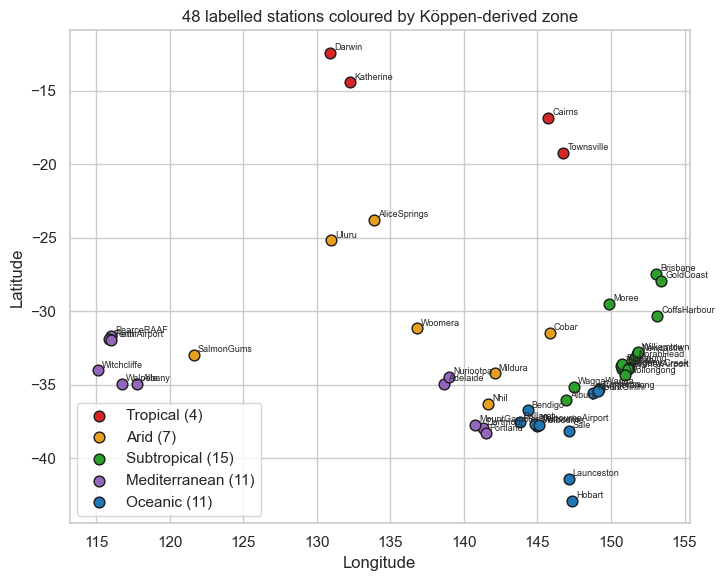

In [5]:
# Where are the stations? (plain lon/lat scatter, no basemap needed)
z = zones.dropna(subset=["Zone"])
fig, ax = plt.subplots(figsize=(8, 6.5))
for zone in ZONE_ORDER:
    s = z[z["Zone"] == zone]
    ax.scatter(s["lon"], s["lat"], s=60, color=ZONE_COLORS[zone], edgecolor="k", label=f"{zone} ({len(s)})")
for r in z.itertuples():
    ax.annotate(r.Location, (r.lon, r.lat), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
ax.set(xlabel="Longitude", ylabel="Latitude", title="48 labelled stations coloured by Köppen-derived zone")
ax.set_aspect("equal"); ax.legend(loc="lower left")
savefig("p1_station_map"); plt.show()

## 1. Data Preprocessing

### 1.1 Loading and leakage audit

For this target, three columns must never be features:

* `Location` — the zone is a deterministic function of the station (this would be the answer itself);
* `RainTomorrow` — information from the next day;
* `RISK_MM` — next-day rainfall in older versions of the dataset (we check rather than assume it is absent).

`Location` is kept **outside** the feature table as `groups`; it is used for splits, within-station trailing windows and error analysis, never as a predictor.
`Date` is only used to derive the day of year; the year itself is not used.

In [6]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

assert sha256(RAW_CSV) == RAW_SHA256, "data file differs from the documented Kaggle v2 file"
raw = pd.read_csv(RAW_CSV, parse_dates=["Date"])
print("raw shape:", raw.shape, "| dates:", raw["Date"].min().date(), "->", raw["Date"].max().date(),
      "| stations:", raw["Location"].nunique())

LEAKAGE_DROP = ["Location", "RainTomorrow", "RISK_MM"]
print("leakage columns present:", [c for c in LEAKAGE_DROP if c in raw.columns],
      "| absent:", [c for c in LEAKAGE_DROP if c not in raw.columns])

df = raw.merge(zones[["Location", "Zone"]], on="Location", how="left", validate="many_to_one")
print("rows without a zone label (dropped):", df["Zone"].isna().sum(), sorted(df.loc[df["Zone"].isna(), "Location"].unique()))
df = df[df["Zone"].notna()].reset_index(drop=True)

groups = df["Location"].copy()                     # station id, NEVER a model input
df = df.drop(columns=[c for c in LEAKAGE_DROP if c in df.columns])
y = df["Zone"].values
print("final shape:", df.shape, "| duplicated (Date, station):", pd.DataFrame({"d": df["Date"], "g": groups}).duplicated().sum())

raw shape: (145460, 23) | dates: 2007-11-01 -> 2017-06-25 | stations: 49
leakage columns present: ['Location', 'RainTomorrow'] | absent: ['RISK_MM']
rows without a zone label (dropped): 3009 ['NorfolkIsland']
final shape: (142451, 22) | duplicated (Date, station): 0


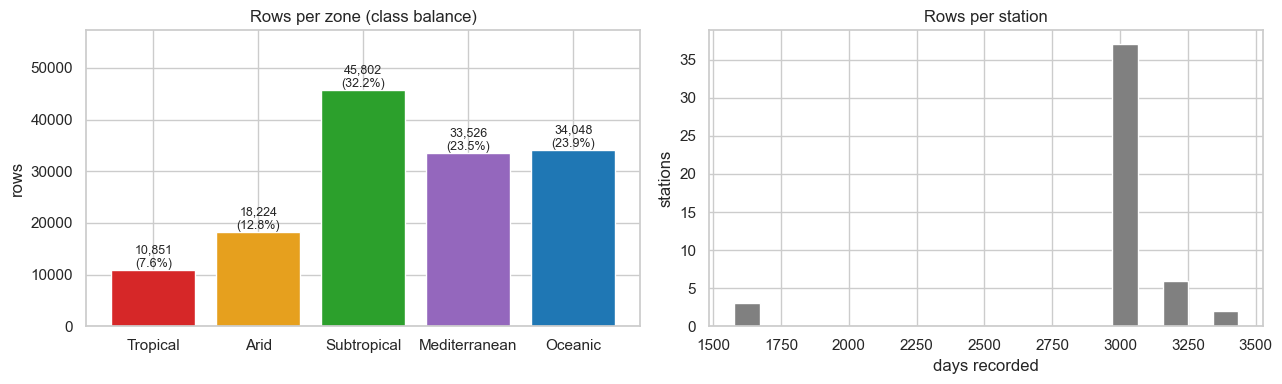

majority-class baseline accuracy: 0.322


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cnt = df["Zone"].value_counts().reindex(ZONE_ORDER)
axes[0].bar(cnt.index, cnt.values, color=[ZONE_COLORS[z] for z in cnt.index])
for i, v in enumerate(cnt.values):
    axes[0].text(i, v, f"{v:,}\n({v / cnt.sum():.1%})", ha="center", va="bottom", fontsize=9)
axes[0].set(title="Rows per zone (class balance)", ylabel="rows"); axes[0].set_ylim(0, cnt.max() * 1.25)

per_station = groups.value_counts()
axes[1].hist(per_station.values, bins=20, color="grey")
axes[1].set(title="Rows per station", xlabel="days recorded", ylabel="stations")
plt.tight_layout(); savefig("p1_class_balance"); plt.show()
print("majority-class baseline accuracy:", round(cnt.max() / cnt.sum(), 3))

### 1.2 Missing values: the structure matters more than the rate

We first look at *where* values are missing, not just how many.

In [8]:
RAW_FEATURES = ["MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine", "WindGustDir", "WindGustSpeed",
                "WindDir9am", "WindDir3pm", "WindSpeed9am", "WindSpeed3pm", "Humidity9am", "Humidity3pm",
                "Pressure9am", "Pressure3pm", "Cloud9am", "Cloud3pm", "Temp9am", "Temp3pm", "RainToday"]
miss_station = df[RAW_FEATURES].isna().groupby(groups).mean()          # station x column missing rate
summary = pd.DataFrame({
    "missing_%": (df[RAW_FEATURES].isna().mean() * 100).round(1),
    "stations_fully_missing(>95%)": (miss_station > 0.95).sum(),
}).sort_values("missing_%", ascending=False)
summary

,missing_%,stations_fully_missing(>95%)
Sunshine,48.7,19
Evaporation,43.9,17
Cloud3pm,41.6,12
Cloud9am,39.2,12
Pressure9am,10.6,4
Pressure3pm,10.5,4
WindDir9am,7.4,0
WindGustDir,7.2,2
WindGustSpeed,7.2,2
Humidity3pm,3.2,0


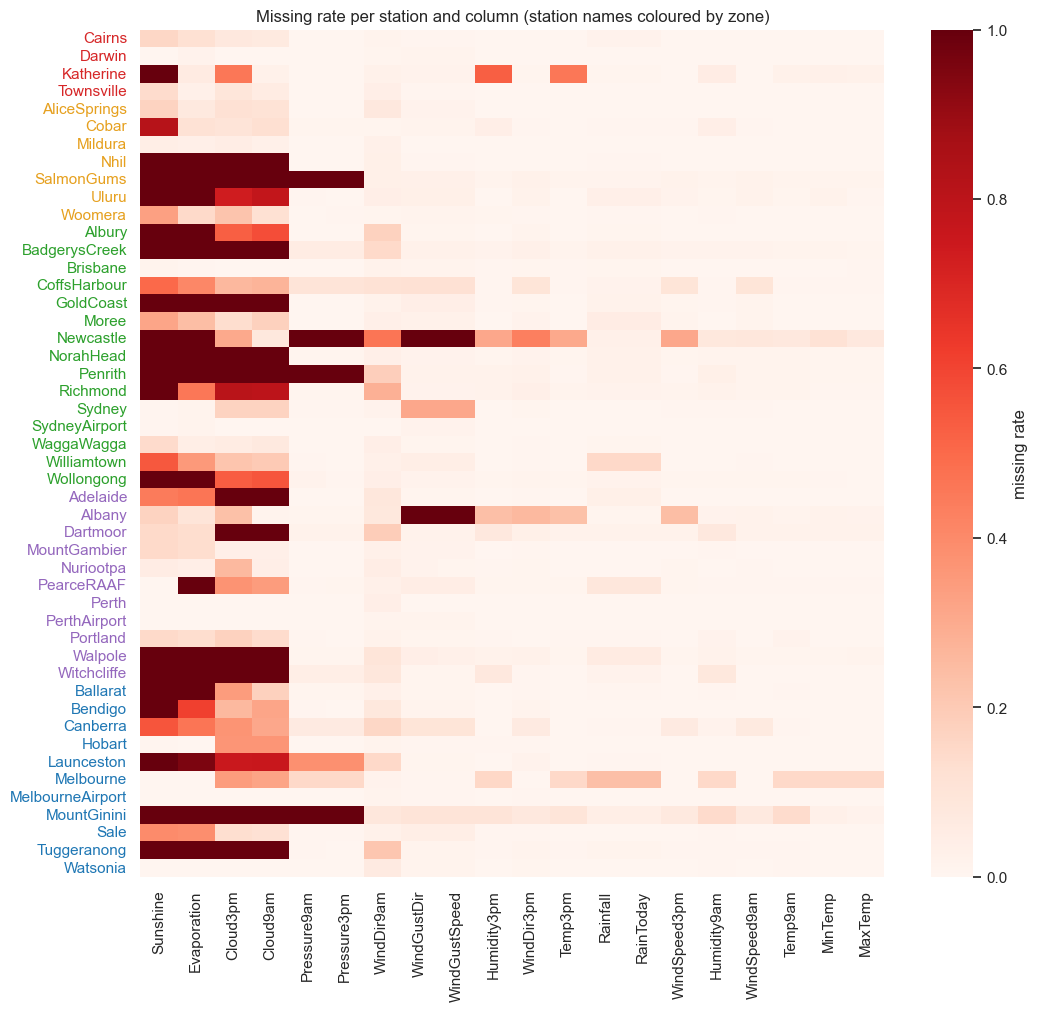

In [9]:
# station x column heatmap, stations sorted by zone; tick labels coloured by zone
station_zone = zones.set_index("Location")["Zone"]
order = sorted(miss_station.index, key=lambda s: (ZONE_ORDER.index(station_zone[s]), s))
cols = summary.index.tolist()
fig, ax = plt.subplots(figsize=(12, 11))
sns.heatmap(miss_station.loc[order, cols], cmap="Reds", vmin=0, vmax=1, cbar_kws={"label": "missing rate"}, ax=ax)
for t in ax.get_yticklabels():
    t.set_color(ZONE_COLORS[station_zone[t.get_text()]])
ax.set(title="Missing rate per station and column (station names coloured by zone)", xlabel="", ylabel="")
savefig("p1_missing_heatmap"); plt.show()

**Observation.** Missingness is a *station property*: Sunshine, Evaporation and Cloud are absent for entire stations
(12–19 of 48) possibly reflecting instrument availability or reporting practices. This creates a hidden risk for our target:
the *pattern* of missing values may identify the station, and the station determines the zone.
We test this directly: train a decision tree on **only the 20 is-missing flags** (no weather values at all).

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
X_missing = df[RAW_FEATURES].isna().astype(int)
def fingerprint_test():
    out = {}
    for name, target in [("Zone", df["Zone"]), ("Location", groups)]:
        tree = cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE), X_missing, target, cv=cv).mean()
        dummy = cross_val_score(DummyClassifier(strategy="most_frequent"), X_missing, target, cv=cv).mean()
        out[name] = {"tree on missing flags": round(tree, 3), "majority baseline": round(dummy, 3)}
    year_acc = cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE),
                               df[["Date"]].apply(lambda d: d.dt.year), df["Zone"], cv=cv).mean()
    out["Zone (from year only)"] = {"tree on missing flags": round(year_acc, 3),
                                    "majority baseline": out["Zone"]["majority baseline"]}
    return out

fingerprint = cached("p1_fingerprint", fingerprint_test, seed=RANDOM_STATE, cols=tuple(RAW_FEATURES))
pd.DataFrame(fingerprint).T

cache hit: p1_fingerprint (0.0s)


,tree on missing flags,majority baseline
Zone,0.439,0.322
Location,0.240,0.024
Zone (from year only),0.323,0.322


Missingness-only prediction is an exploratory diagnostic of station-specific information. It does not establish that all such information is non-climatic or harmful under every deployment target. The core feature policy is retained from the earlier exploratory work; its sensitivity is re-evaluated inside the outer-fold analysis.

In [11]:
for d, s in [("WindDir9am", "WindSpeed9am"), ("WindDir3pm", "WindSpeed3pm")]:
    calm = df[s] == 0
    print(f"{d}: {df[d].isna().sum():6d} missing | rows with {s}==0: {calm.sum():5d}, "
          f"of which direction missing: {df.loc[calm, d].isna().mean():.0%}")
r = df.dropna(subset=["Rainfall", "RainToday"])
print("RainToday == (Rainfall > 1 mm) for", f"{((r['Rainfall'] > 1) == (r['RainToday'] == 'Yes')).mean():.1%}", "of rows")

WindDir9am:  10535 missing | rows with WindSpeed9am==0:  8722, of which direction missing: 100%
WindDir3pm:   4223 missing | rows with WindSpeed3pm==0:  1109, of which direction missing: 100%
RainToday == (Rainfall > 1 mm) for 100.0% of rows


* **Calm wind.** Every row with wind speed 0 has no direction: the direction is *undefined*, not unknown.
  Encoding wind as a vector `(u, v)` handles this exactly — calm is `(0, 0)`.
* **RainToday** is a deterministic function of `Rainfall` (threshold 1 mm). After encoding it as 0/1 it adds no
  information, so we drop it and keep `Rainfall`.

### 1.4 Handling non-numeric values and further processing

| Raw column(s) | Treatment | Reason |
|---|---|---|
| `WindGustDir`, `WindDir9am`, `WindDir3pm` + speeds | 16-point compass → angle θ → vector `u = −s·sinθ`, `v = −s·cosθ` | keeps the circular order (N is next to NNW), merges direction and strength, calm = (0,0); 6 numbers instead of 48 one-hot columns |
| `Date` | day of year → `sin`, `cos` | 31 Dec and 1 Jan are neighbours; year not used |
| `RainToday` | Yes/No → 1/0, then dropped | identical to `Rainfall > 1` |
| `Rainfall`, `Evaporation` | `log1p` | strongly right-skewed, 63% zeros |
| all numeric | median imputation → `StandardScaler` | fitted **inside the pipeline on training data only** |
| Sunshine, Evaporation, Cloud9am/3pm | excluded from the default (`core`) feature set | missing for whole stations → station fingerprint; kept in a `full` set for a sensitivity check |

All transformations in `make_features` are row-wise (no statistics are learned), so applying them before the split is safe.

In [12]:
COMPASS = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
DIR_TO_DEG = {d: i * 22.5 for i, d in enumerate(COMPASS)}
WIND_PAIRS = {"Gust": ("WindGustDir", "WindGustSpeed"),
              "Wind9am": ("WindDir9am", "WindSpeed9am"),
              "Wind3pm": ("WindDir3pm", "WindSpeed3pm")}

def wind_vector(direction, speed):
    theta = np.deg2rad(direction.map(DIR_TO_DEG))
    u, v = -speed * np.sin(theta), -speed * np.cos(theta)
    calm = speed.eq(0)                       # calm: direction undefined, vector is exactly zero
    u[calm], v[calm] = 0.0, 0.0
    return u, v

def make_features(data):
    out = pd.DataFrame(index=data.index)
    for c in ["MinTemp", "MaxTemp", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm", "Humidity9am", "Humidity3pm",
              "Pressure9am", "Pressure3pm", "Temp9am", "Temp3pm", "Sunshine", "Cloud9am", "Cloud3pm"]:
        out[c] = data[c]
    out["Rainfall_log1p"] = np.log1p(data["Rainfall"])
    out["Evaporation_log1p"] = np.log1p(data["Evaporation"])
    for prefix, (dcol, scol) in WIND_PAIRS.items():
        out[f"{prefix}_u"], out[f"{prefix}_v"] = wind_vector(data[dcol], data[scol])
    doy = data["Date"].dt.dayofyear
    out["doy_sin"], out["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    return out

CORE_NUMERIC = ["MinTemp", "MaxTemp", "Rainfall_log1p", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm",
                "Humidity9am", "Humidity3pm", "Pressure9am", "Pressure3pm", "Temp9am", "Temp3pm"]
WIND_VECTOR = [f"{p}_{c}" for p in WIND_PAIRS for c in ("u", "v")]
SEASON = ["doy_sin", "doy_cos"]
STATION_SENSOR = ["Sunshine", "Evaporation_log1p", "Cloud9am", "Cloud3pm"]
FEATURE_SETS = {"core": CORE_NUMERIC + WIND_VECTOR + SEASON,
                "full": CORE_NUMERIC + WIND_VECTOR + SEASON + STATION_SENSOR}

def build_preprocessor(add_indicator=False):
    # learned statistics (medians, means, stds) -> always inside a Pipeline, fitted on training data only
    return Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=add_indicator)),
                     ("scale", StandardScaler())])

F = make_features(df)
X_core = F[FEATURE_SETS["core"]]
print("features:", F.shape[1], "| core set:", X_core.shape[1], "columns")
print("remaining missing rate in core set (top 5):")
print((X_core.isna().mean() * 100).round(1).sort_values(ascending=False).head(5).to_string())

features: 24 | core set: 20 columns
remaining missing rate in core set (top 5):
Pressure9am      10.6
Pressure3pm      10.5
WindGustSpeed     7.2
Gust_v            7.2
Gust_u            7.2


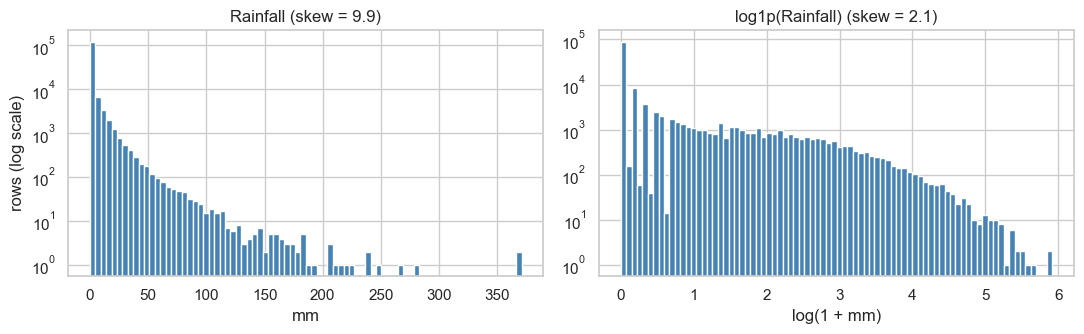

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(df["Rainfall"].dropna(), bins=80, color="steelblue"); axes[0].set_yscale("log")
axes[0].set(title=f"Rainfall (skew = {df['Rainfall'].skew():.1f})", xlabel="mm", ylabel="rows (log scale)")
axes[1].hist(F["Rainfall_log1p"].dropna(), bins=80, color="steelblue"); axes[1].set_yscale("log")
axes[1].set(title=f"log1p(Rainfall) (skew = {F['Rainfall_log1p'].skew():.1f})", xlabel="log(1 + mm)")
plt.tight_layout(); savefig("p1_rainfall_log"); plt.show()

### 1.5 Patterns in the data: what distinguishes the zones?

The **seasonal cycle** is the textbook definition of the Köppen classes, so we expect it to be visible in the data.

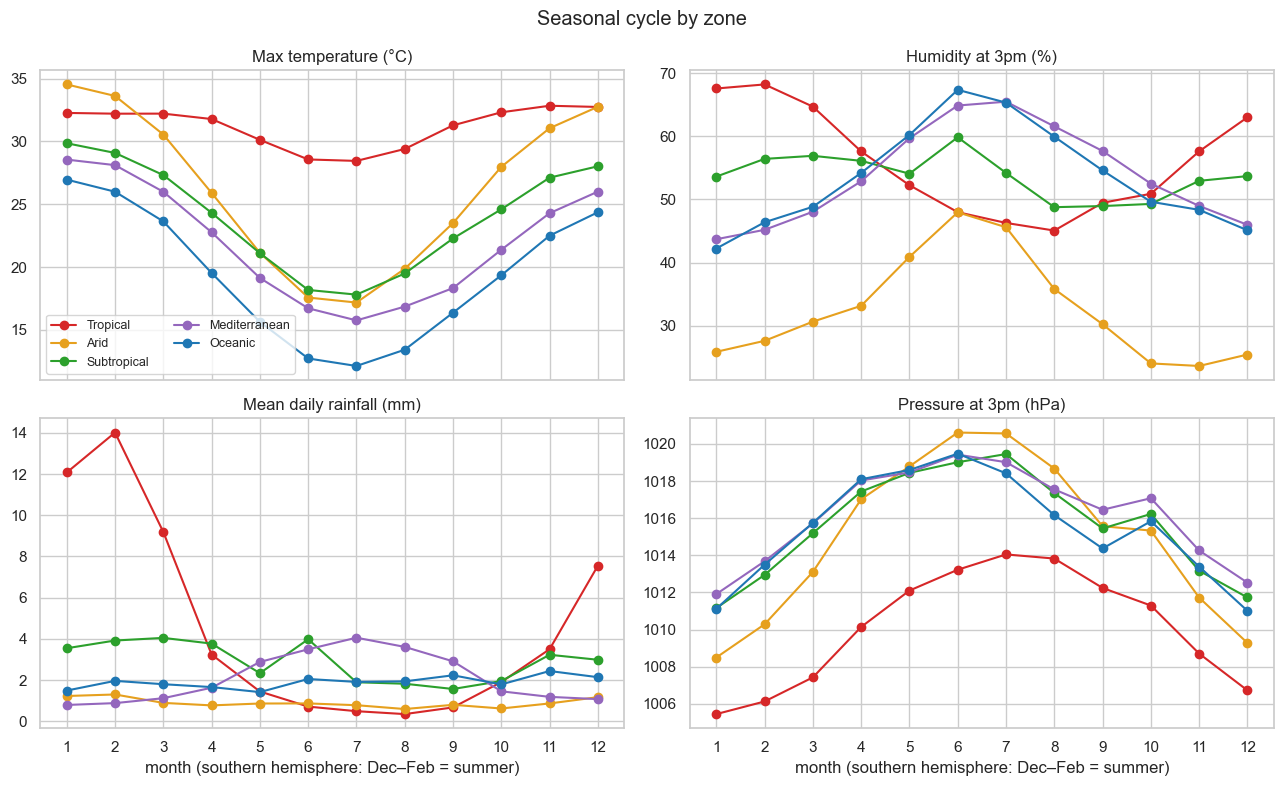

In [14]:
monthly = df.assign(month=df["Date"].dt.month).groupby(["Zone", "month"])[
    ["MaxTemp", "Humidity3pm", "Rainfall", "Pressure3pm"]].mean()
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
titles = {"MaxTemp": "Max temperature (°C)", "Humidity3pm": "Humidity at 3pm (%)",
          "Rainfall": "Mean daily rainfall (mm)", "Pressure3pm": "Pressure at 3pm (hPa)"}
for ax, col in zip(axes.ravel(), titles):
    for zone in ZONE_ORDER:
        ax.plot(range(1, 13), monthly.loc[zone, col], marker="o", color=ZONE_COLORS[zone], label=zone)
    ax.set(title=titles[col]); ax.set_xticks(range(1, 13))
for ax in axes[1]:
    ax.set_xlabel("month (southern hemisphere: Dec–Feb = summer)")
axes[0, 0].legend(ncol=2, fontsize=9)
plt.suptitle("Seasonal cycle by zone"); plt.tight_layout(); savefig("p1_seasonal_cycle"); plt.show()

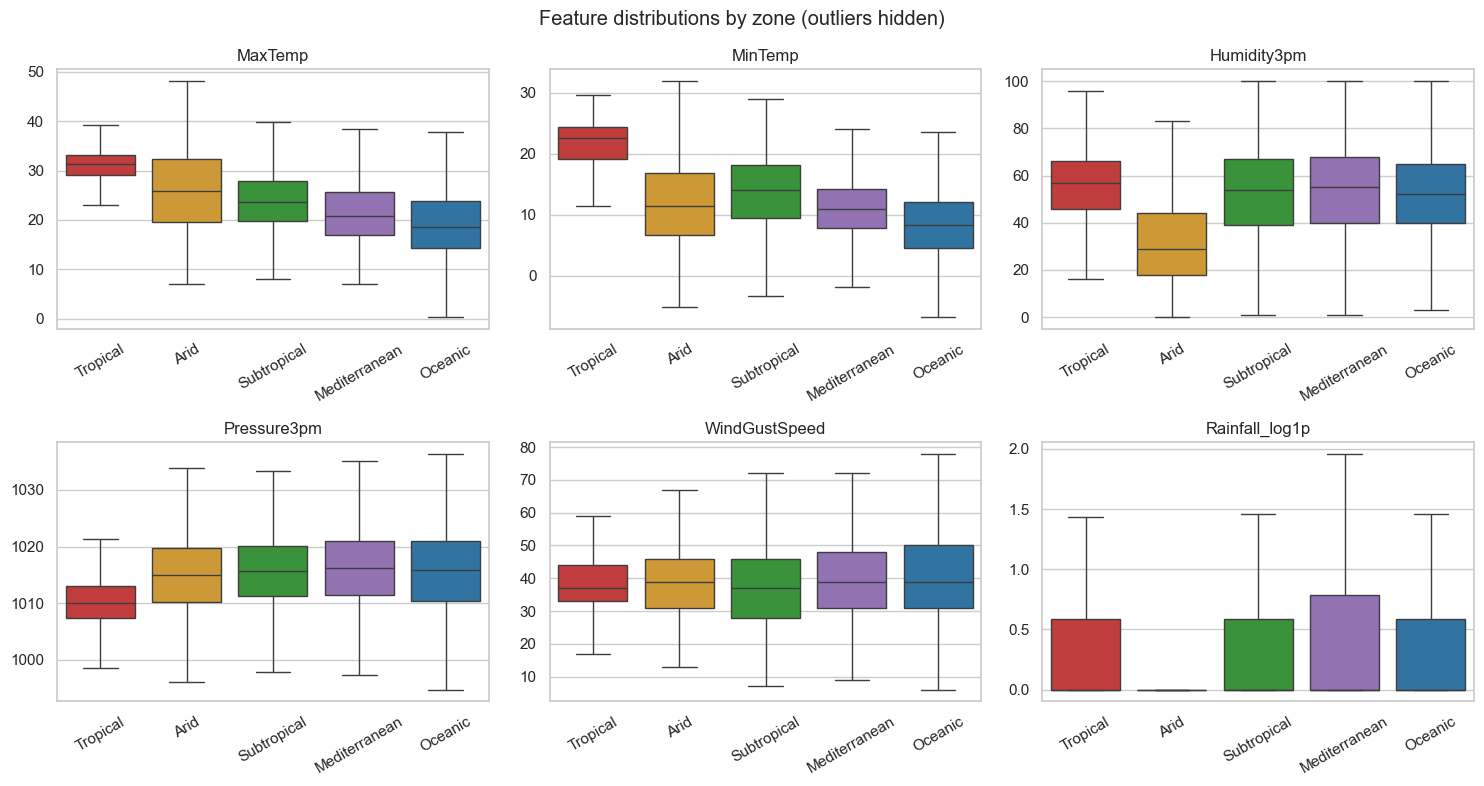

In [15]:
show = ["MaxTemp", "MinTemp", "Humidity3pm", "Pressure3pm", "WindGustSpeed", "Rainfall_log1p"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), show):
    sns.boxplot(x=df["Zone"], y=F[col], order=ZONE_ORDER, hue=df["Zone"], hue_order=ZONE_ORDER,
                palette=ZONE_COLORS, showfliers=False, legend=False, ax=ax)
    ax.set(title=col, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Feature distributions by zone (outliers hidden)")
plt.tight_layout(); savefig("p1_boxplots"); plt.show()

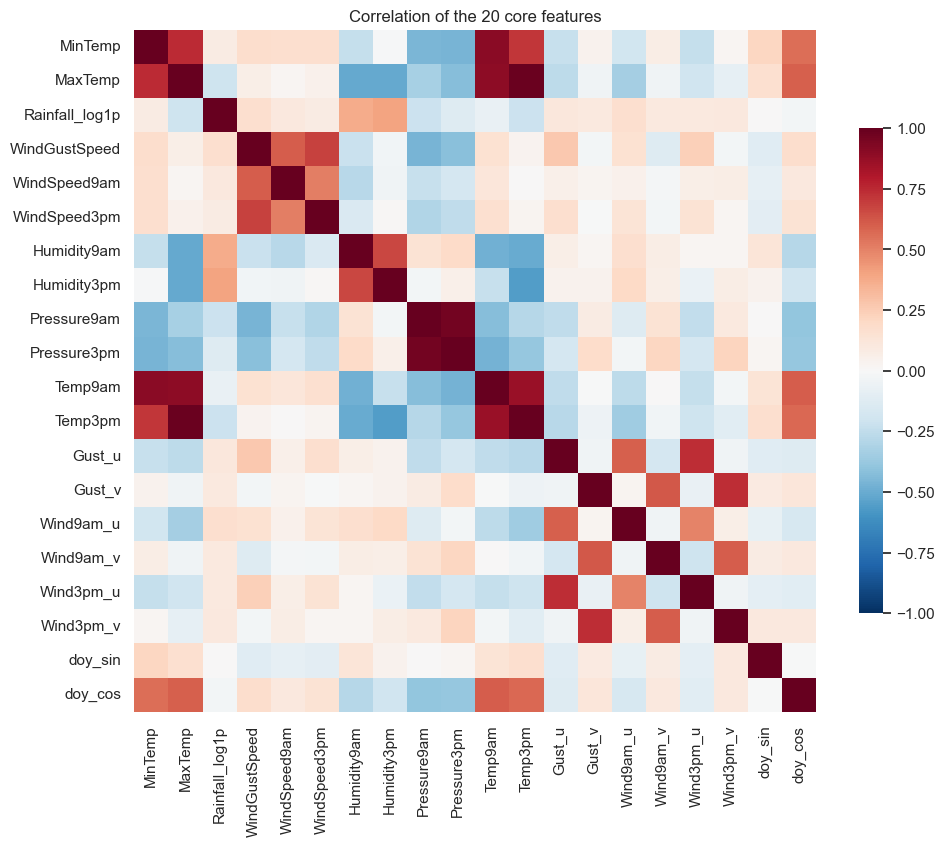

most correlated pairs:
 MaxTemp      Temp3pm        0.985
Pressure9am  Pressure3pm    0.961
MinTemp      Temp9am        0.902
MaxTemp      Temp9am        0.891
Temp9am      Temp3pm        0.864
MinTemp      MaxTemp        0.744


In [16]:
corr = X_core.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlation of the 20 core features"); savefig("p1_correlation"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
print("most correlated pairs:\n", pairs.head(6).round(3).to_string())

### 1.6 Sensitivity check: does the feature-set / indicator choice create a station shortcut?

A quick logistic-regression probe (full evaluation follows in Parts 4–5). Two splits answer two different questions:

* **random stratified 70/30** — can the model recognise a *new day* of stations it has seen?
* **station-grouped 70/30** — can it recognise the zone of *stations it has never seen*?

A protocol-dependent gain is consistent with station-specific information, but is not by itself proof of its cause.

In [17]:
idx = np.arange(len(df))
rand_tr, rand_te = train_test_split(idx, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
grp_tr, grp_te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=RANDOM_STATE).split(idx, y, groups))
print("grouped split: test stations =", groups.iloc[grp_te].nunique(), "| overlap with train stations =",
      len(set(groups.iloc[grp_te]) & set(groups.iloc[grp_tr])))

def sensitivity_probe():
    rows = []
    for fs, ind in [("core", False), ("full", False), ("full", True)]:
        X = F[FEATURE_SETS[fs]]
        for split, (a, b) in {"random": (rand_tr, rand_te), "grouped": (grp_tr, grp_te)}.items():
            model = make_pipeline(build_preprocessor(add_indicator=ind), LogisticRegression(max_iter=3000))
            model.fit(X.iloc[a], y[a]); pred = model.predict(X.iloc[b])
            rows.append({"features": fs, "missing indicator": ind, "split": split,
                         "accuracy": accuracy_score(y[b], pred), "macro-F1": f1_score(y[b], pred, average="macro")})
    return rows

rows = cached("p1_sensitivity", sensitivity_probe, seed=RANDOM_STATE, sets=repr(FEATURE_SETS))
sens = pd.DataFrame(rows).pivot_table(index=["features", "missing indicator"], columns="split",
                                      values=["accuracy", "macro-F1"]).round(3)
sens

grouped split: test stations = 15 | overlap with train stations = 0
cache hit: p1_sensitivity (0.0s)


accuracy        macro-F1       
split                       grouped random  grouped random
features missing indicator                                
core     False                0.563  0.599    0.561  0.615
full     False                0.569  0.606    0.567  0.622
         True                 0.572  0.671    0.558  0.688

This is an exploratory preprocessing comparison, not an independent assessment of a selected policy. A difference between protocols suggests sensitivity to station composition; it does not causally separate instrumentation from climate. Part 6 repeats the comparison with fixed policies and outer station folds. The core policy is not reselected from test scores.

## 2. Data Visualization with t-SNE

**Question.** Do days from different climate zones separate naturally in the 20-dimensional feature space?

### 2.1 Sample and caching

t-SNE costs roughly O(n log n) per iteration with a large constant, so we embed a **balanced sample of 1,200 days per zone
(6,000 days)**. Balancing keeps the small Tropical class (7.6% of rows) from being drowned by Subtropical (32%) in the
picture. The same sample is reused for clustering in Part 3.

The preprocessor (median imputation + standardisation, no missing indicators) is fitted on this sample. Zone labels determine the balanced sampling; the t-SNE optimisation itself receives no labels. The picture describes this deliberately reweighted sample, not the natural data frequency.

Each embedding takes 20–30 s. Embeddings are cached under `data/processed/tsne_audit/<run_id>/`; the file name contains a hash of
the input matrix and the parameters, and the full experiment fingerprint, so code/data/environment changes invalidate results. Set `RECOMPUTE_TSNE = True`
to ignore the cache.

In [18]:
N_PER_ZONE = 1200
sample_idx = df.groupby("Zone", group_keys=False).sample(n=N_PER_ZONE, random_state=RANDOM_STATE).index
X_vis = build_preprocessor().fit_transform(F.loc[sample_idx, FEATURE_SETS["core"]])
y_vis = df.loc[sample_idx, "Zone"].values
g_vis = groups.loc[sample_idx].values
month_vis = df.loc[sample_idx, "Date"].dt.month.values
SEASON_OF_MONTH = {12: "Summer", 1: "Summer", 2: "Summer", 3: "Autumn", 4: "Autumn", 5: "Autumn",
                   6: "Winter", 7: "Winter", 8: "Winter", 9: "Spring", 10: "Spring", 11: "Spring"}
season_vis = np.array([SEASON_OF_MONTH[m] for m in month_vis])
print("sample:", X_vis.shape, "| stations in sample:", len(set(g_vis)))

TSNE_DIR = DATA_DIR / "processed" / "tsne_audit" / RUN_ID; TSNE_DIR.mkdir(parents=True, exist_ok=True)
RECOMPUTE_TSNE = RECOMPUTE

def tsne_cached(X, n_components=2, perplexity=30, seed=RANDOM_STATE):
    key = hashlib.sha256(np.ascontiguousarray(X).tobytes()).hexdigest()[:12]
    path = TSNE_DIR / f"tsne_{key}_d{n_components}_p{perplexity}_s{seed}.npy"
    if path.exists() and not RECOMPUTE_TSNE:
        return np.load(path)
    E = TSNE(n_components=n_components, perplexity=perplexity, init="pca", learning_rate="auto",
             max_iter=1000, random_state=seed).fit_transform(X)
    np.save(path, E)
    return E

def knn_purity(E, labels, k=10):
    # 5-fold accuracy of a k-NN classifier on the embedding = how often a point's neighbours share its label
    return cross_val_score(KNeighborsClassifier(n_neighbors=k), E, labels, cv=5).mean()

def knn_kappa(E, labels, k=10):
    # the same k-NN predictions, scored with Cohen's kappa = (accuracy - chance agreement) / (1 - chance agreement),
    # so that label sets with different numbers of classes / class shares can be compared
    pred = cross_val_predict(KNeighborsClassifier(n_neighbors=k), E, labels, cv=5)
    return cohen_kappa_score(labels, pred)

sample: (6000, 20) | stations in sample: 48


### 2.2 Main embedding (perplexity 30)

We colour the same embedding three ways: by zone (our target), by month, and by maximum temperature.

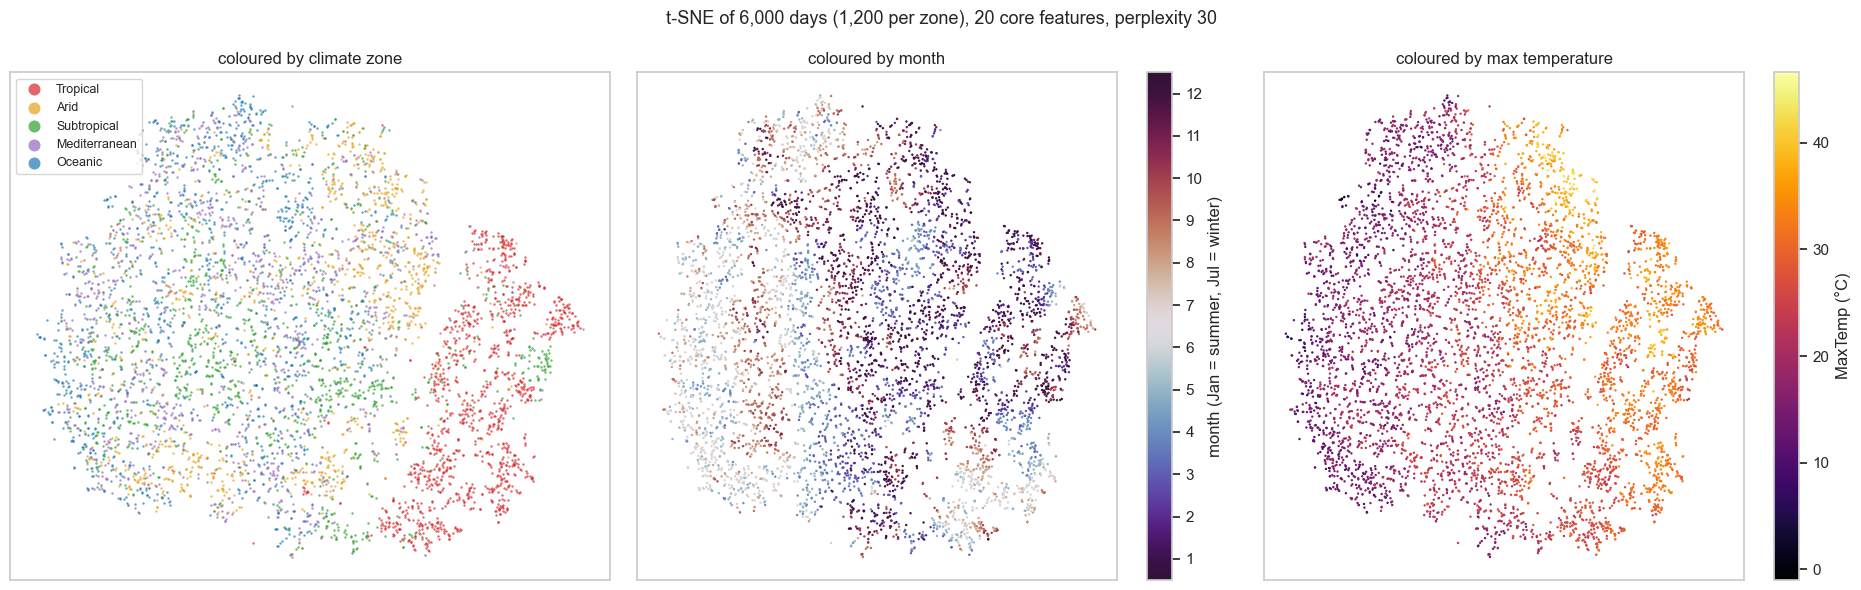

In [19]:
E2 = tsne_cached(X_vis, perplexity=30)

def scatter_by_zone(ax, E, labels=y_vis, s=3):
    for zone in ZONE_ORDER:
        m = labels == zone
        ax.scatter(E[m, 0], E[m, 1], s=s, color=ZONE_COLORS[zone], label=zone, alpha=0.7, linewidths=0)
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
scatter_by_zone(axes[0], E2)
axes[0].legend(markerscale=5, loc="upper left", fontsize=9); axes[0].set_title("coloured by climate zone")
sc = axes[1].scatter(E2[:, 0], E2[:, 1], s=3, c=month_vis, cmap="twilight_shifted", vmin=0.5, vmax=12.5, linewidths=0)
cb = plt.colorbar(sc, ax=axes[1], ticks=range(1, 13)); cb.set_label("month (Jan = summer, Jul = winter)")
axes[1].set_title("coloured by month"); axes[1].set_xticks([]); axes[1].set_yticks([])
sc = axes[2].scatter(E2[:, 0], E2[:, 1], s=3, c=F.loc[sample_idx, "MaxTemp"], cmap="inferno", linewidths=0)
plt.colorbar(sc, ax=axes[2]).set_label("MaxTemp (°C)")
axes[2].set_title("coloured by max temperature"); axes[2].set_xticks([]); axes[2].set_yticks([])
fig.suptitle("t-SNE of 6,000 days (1,200 per zone), 20 core features, perplexity 30", fontsize=13)
plt.tight_layout(); savefig("p2_tsne_main"); plt.show()

### 2.3 Quantifying what the picture shows

A t-SNE plot is easy to over-read, so we add three descriptive numbers:

* **k-NN purity** — 5-fold accuracy of a 10-nearest-neighbour classifier on the coordinates. It answers
  "how often do a point's neighbours have the same label?" With 5 balanced classes, chance is 0.20.
* **Cohen's κ** of the same predictions. Zone (5 balanced classes), season (4 classes) and station (48 classes)
  have different chance levels, so raw purities cannot be compared across label sets; κ subtracts chance agreement.
* **Trustworthiness** (`sklearn.manifold.trustworthiness`, k = 10) — how well the 2-D neighbourhoods reflect
  the true 20-D neighbourhoods (1 = perfect).

PCA to 2-D is the linear baseline. **These are diagnostics of the picture, not estimates of classification
performance**: t-SNE reshapes neighbourhoods, it used all 6,000 points at once (no train/test separation), and days
of the same station appear on both sides of every k-NN fold. Generalisation is measured in Parts 4–6.

In [20]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_vis)
P2 = pca2.transform(X_vis)
spaces = {"original 20-D": X_vis, "PCA 2-D": P2, "t-SNE 2-D": E2}
quant = pd.DataFrame({
    "purity: zone": {k: knn_purity(v, y_vis) for k, v in spaces.items()},
    "κ: zone": {k: knn_kappa(v, y_vis) for k, v in spaces.items()},
    "purity: season": {k: knn_purity(v, season_vis) for k, v in spaces.items()},
    "κ: season": {k: knn_kappa(v, season_vis) for k, v in spaces.items()},
    "purity: station (48)": {k: knn_purity(v, g_vis) for k, v in spaces.items()},
    "κ: station": {k: knn_kappa(v, g_vis) for k, v in spaces.items()},
    "trustworthiness": {"original 20-D": 1.0, "PCA 2-D": trustworthiness(X_vis, P2, n_neighbors=10),
                        "t-SNE 2-D": trustworthiness(X_vis, E2, n_neighbors=10)},
}).round(3)
print(f"chance level: zone 0.20, season ~0.25, station ~{1 / 48:.3f}; "
      f"PCA explains {pca2.explained_variance_ratio_.sum():.1%} of the variance in 2-D")
quant

chance level: zone 0.20, season ~0.25, station ~0.021; PCA explains 42.2% of the variance in 2-D


,purity: zone,κ: zone,purity: season,κ: season,purity: station (48),κ: station,trustworthiness
original 20-D,0.683,0.604,0.794,0.724,0.354,0.334,1.000
PCA 2-D,0.378,0.223,0.409,0.210,0.113,0.083,0.809
t-SNE 2-D,0.631,0.539,0.663,0.550,0.310,0.290,0.985


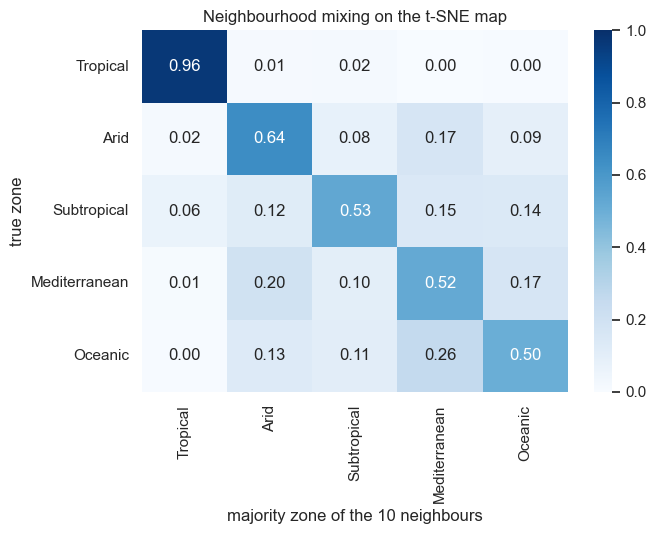

In [21]:
# Which zones are mixed with which? k-NN predictions on the t-SNE map, row-normalised
pred = cross_val_predict(KNeighborsClassifier(n_neighbors=10), E2, y_vis, cv=5)
mix = pd.crosstab(pd.Series(y_vis, name="true zone"), pd.Series(pred, name="majority zone of the 10 neighbours"),
                  normalize="index").loc[ZONE_ORDER, ZONE_ORDER]
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(mix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Neighbourhood mixing on the t-SNE map")
plt.tight_layout(); savefig("p2_tsne_neighbour_mixing"); plt.show()

### 2.4 Is the structure just the season?

The month colouring shows a strong summer–winter gradient. If season alone drove the layout, zones would
separate much better once the season is held fixed. We check this by (a) embedding summer days and winter days
separately, and (b) removing the two day-of-year features.

In [22]:
feat = FEATURE_SETS["core"]
no_season_cols = [i for i, f in enumerate(feat) if not f.startswith("doy")]
variants = {
    "all days, all 20 features": (X_vis, y_vis),
    "summer days only (Dec–Feb)": (X_vis[season_vis == "Summer"], y_vis[season_vis == "Summer"]),
    "winter days only (Jun–Aug)": (X_vis[season_vis == "Winter"], y_vis[season_vis == "Winter"]),
    "all days, without doy_sin/doy_cos": (X_vis[:, no_season_cols], y_vis),
}
rows, embs = [], {}
for name, (Xv, yv) in variants.items():
    Ev = E2 if name.startswith("all days, all") else tsne_cached(Xv, perplexity=30)
    embs[name] = (Ev, yv)
    sv = season_vis if name.startswith("all days") else None            # season is constant in the 1-season variants
    rows.append({"variant": name, "n": len(yv), "zone purity (20-D)": knn_purity(Xv, yv),
                 "zone purity (t-SNE)": knn_purity(Ev, yv), "zone κ (t-SNE)": knn_kappa(Ev, yv),
                 "season κ (t-SNE)": knn_kappa(Ev, sv) if sv is not None else np.nan})
pd.DataFrame(rows).set_index("variant").round(3)

,n,zone purity (20-D),zone purity (t-SNE),zone κ (t-SNE),season κ (t-SNE)
variant,,,,,
"all days, all 20 features",6000,0.683,0.631,0.539,0.550
summer days only (Dec–Feb),1514,0.688,0.653,0.567,NaN
winter days only (Jun–Aug),1529,0.672,0.642,0.552,NaN
"all days, without doy_sin/doy_cos",6000,0.641,0.591,0.489,0.173


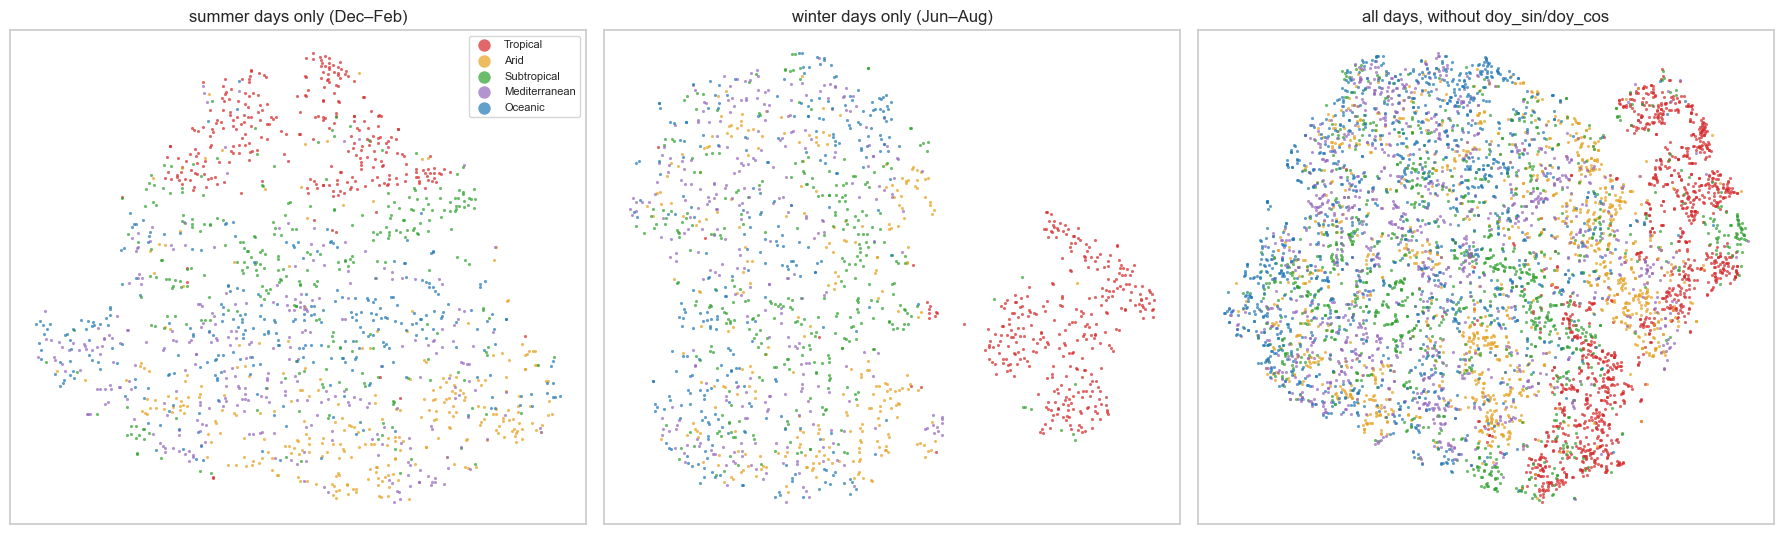

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, name in zip(axes, list(embs)[1:]):
    Ev, yv = embs[name]
    scatter_by_zone(ax, Ev, yv, s=5); ax.set_title(name)
axes[0].legend(markerscale=4, fontsize=8)
plt.tight_layout(); savefig("p2_tsne_season_control"); plt.show()

### 2.5 Sensitivity: perplexity and random seed

Perplexity is roughly the number of effective neighbours each point considers: small values emphasise local
detail, large values preserve more global structure. t-SNE is also non-convex, so different seeds give different
layouts; conclusions should hold for all of them.

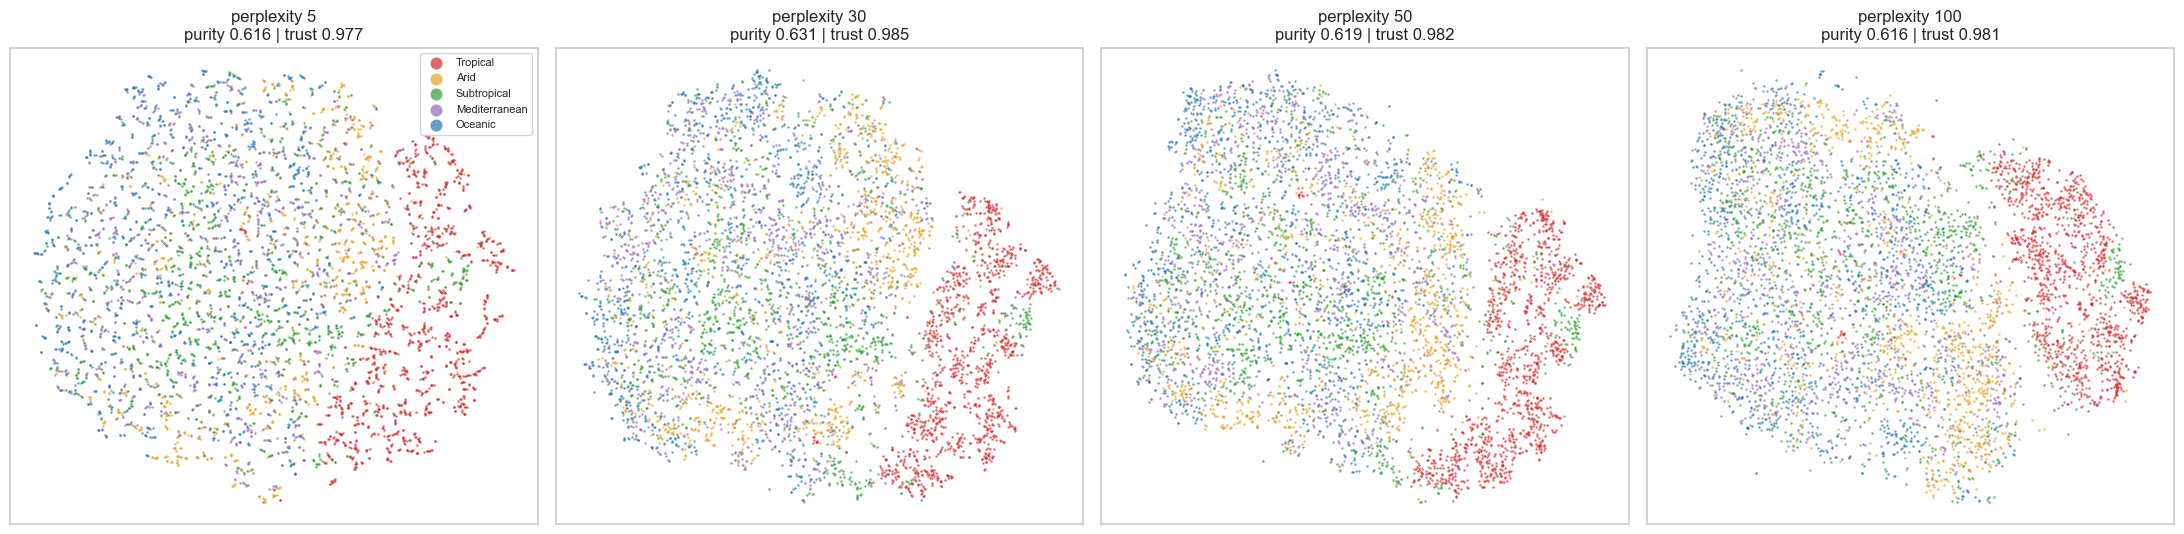

perplexity,5,30,50,100
zone purity,0.616,0.631,0.619,0.616
trustworthiness,0.977,0.985,0.982,0.981


In [24]:
perplexities = [5, 30, 50, 100]
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
perp_rows = []
for ax, p in zip(axes, perplexities):
    Ep = tsne_cached(X_vis, perplexity=p)
    pur, tru = knn_purity(Ep, y_vis), trustworthiness(X_vis, Ep, n_neighbors=10)
    perp_rows.append({"perplexity": p, "zone purity": pur, "trustworthiness": tru})
    scatter_by_zone(ax, Ep); ax.set_title(f"perplexity {p}\npurity {pur:.3f} | trust {tru:.3f}")
axes[0].legend(markerscale=5, fontsize=8)
plt.tight_layout(); savefig("p2_tsne_perplexity"); plt.show()
pd.DataFrame(perp_rows).set_index("perplexity").round(3).T

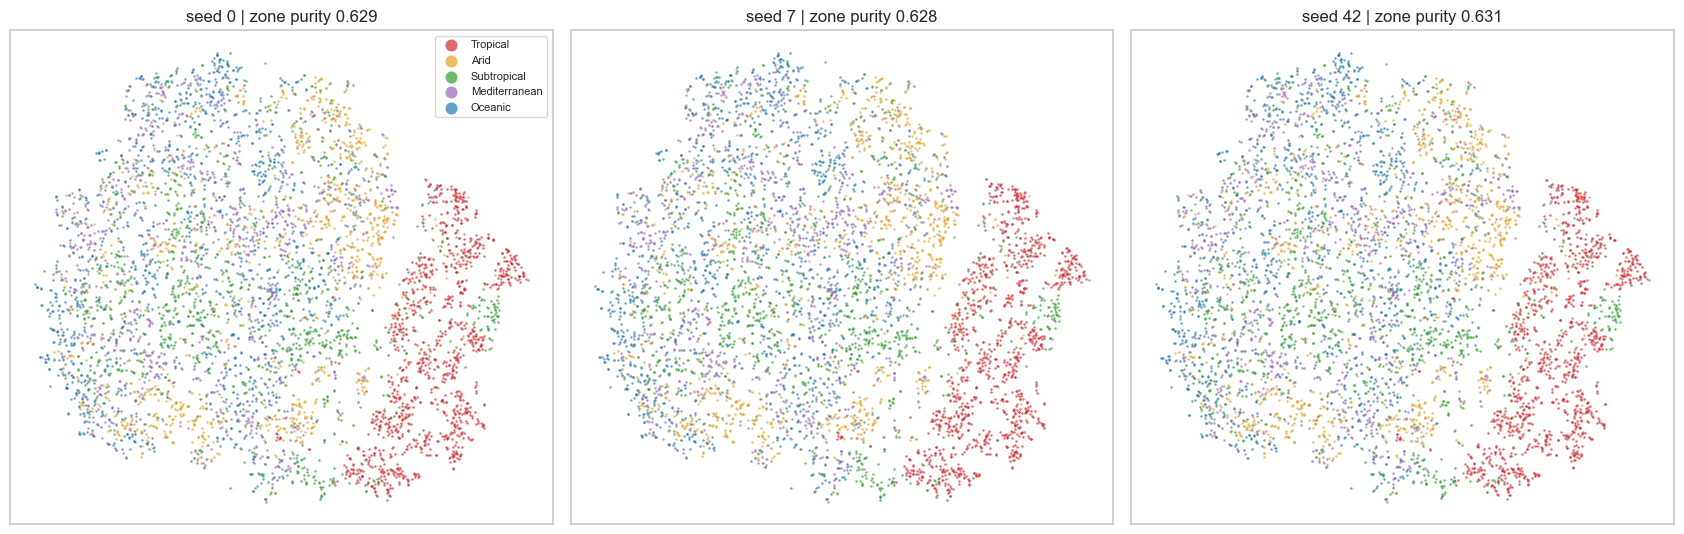

In [25]:
seeds = [0, 7, RANDOM_STATE]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, s in zip(axes, seeds):
    Es = tsne_cached(X_vis, perplexity=30, seed=s)
    scatter_by_zone(ax, Es); ax.set_title(f"seed {s} | zone purity {knn_purity(Es, y_vis):.3f}")
axes[0].legend(markerscale=5, fontsize=8)
plt.tight_layout(); savefig("p2_tsne_seeds"); plt.show()

### 2.6 PCA (linear) vs t-SNE, and a 3-D t-SNE view

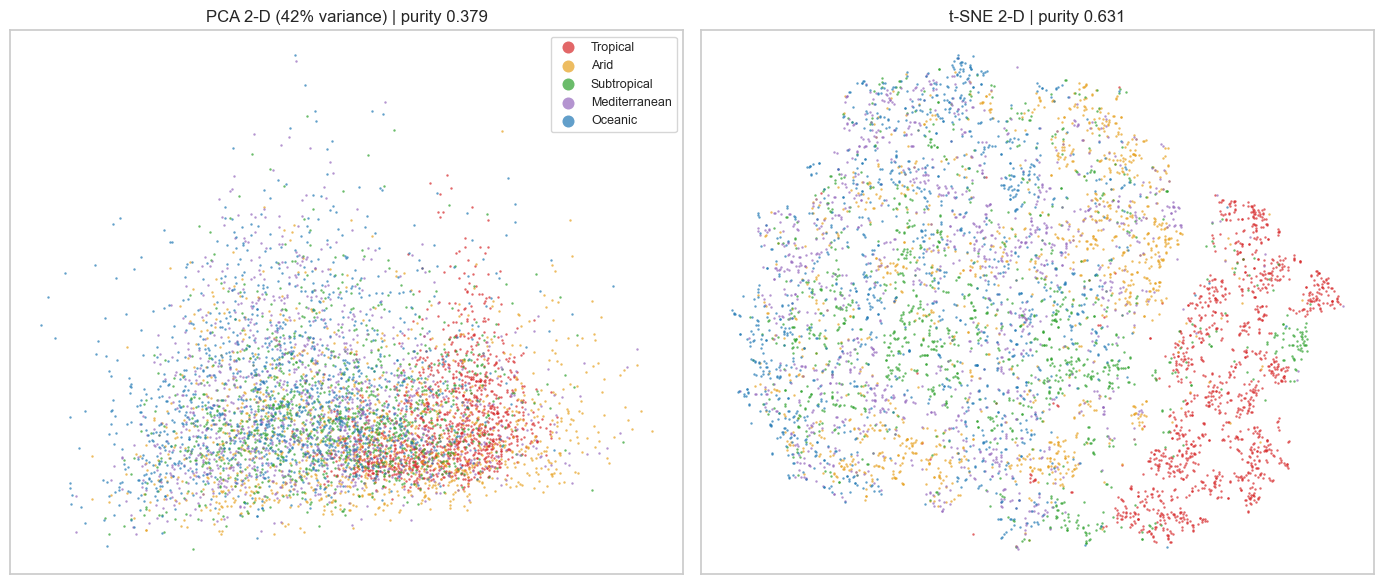

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
scatter_by_zone(axes[0], P2)
axes[0].set_title(f"PCA 2-D ({pca2.explained_variance_ratio_.sum():.0%} variance) | purity {knn_purity(P2, y_vis):.3f}")
scatter_by_zone(axes[1], E2); axes[1].set_title(f"t-SNE 2-D | purity {knn_purity(E2, y_vis):.3f}")
axes[0].legend(markerscale=5, fontsize=9)
plt.tight_layout(); savefig("p2_pca_vs_tsne"); plt.show()

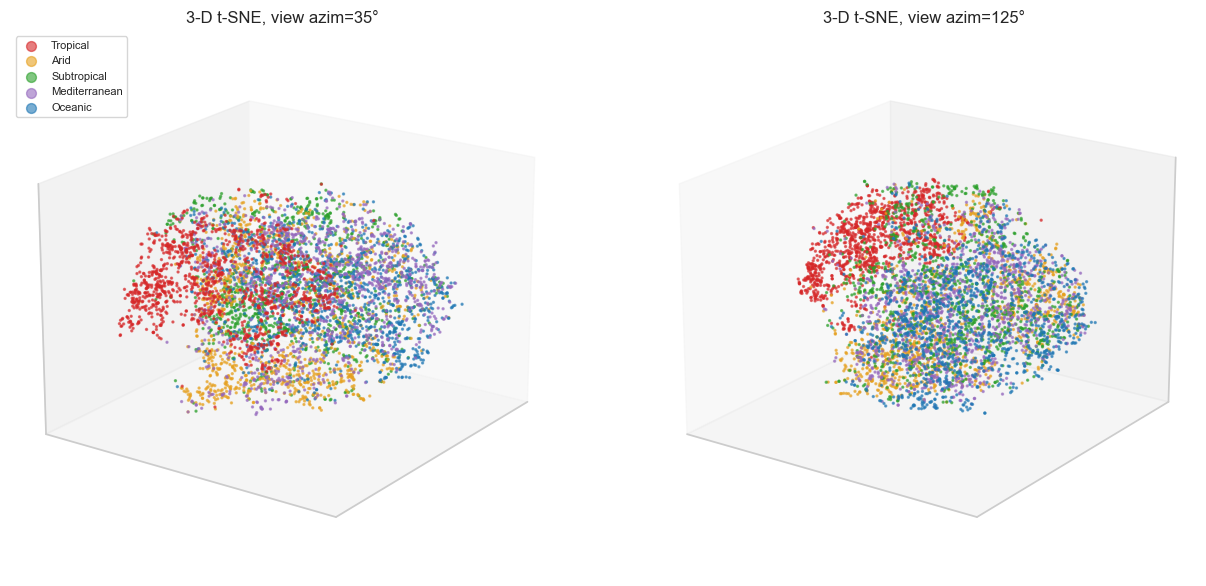

zone purity in 3-D t-SNE: 0.635


In [27]:
E3 = tsne_cached(X_vis, n_components=3, perplexity=30)
fig = plt.figure(figsize=(13, 6))
for i, (elev, azim) in enumerate([(20, 35), (20, 125)]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    for zone in ZONE_ORDER:
        m = y_vis == zone
        ax.scatter(E3[m, 0], E3[m, 1], E3[m, 2], s=2, color=ZONE_COLORS[zone], label=zone, alpha=0.6)
    ax.view_init(elev=elev, azim=azim); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax.set_title(f"3-D t-SNE, view azim={azim}°")
fig.axes[0].legend(markerscale=5, fontsize=8, loc="upper left")
plt.tight_layout(); savefig("p2_tsne_3d"); plt.show()
print("zone purity in 3-D t-SNE:", round(knn_purity(E3, y_vis), 3))

### 2.7 Interpretation and limits

Read the new tables and plots above. Compare zone mixing, season controls, seed/perplexity sensitivity and neighbourhood preservation. High local label agreement is descriptive: labels influenced sampling and station days occur on both sides of the diagnostic kNN folds. Kappa adjusts chance agreement but is not an information-theoretic comparison between different prediction targets. t-SNE distances between islands and apparent island sizes should not be interpreted physically; classifiers below use the original features, not t-SNE coordinates.

## 3. Clustering Analysis

**Question.** Without labels, can clustering rediscover the climate zones?

We cluster the same balanced sample of 6,000 days as in Part 2 (preprocessed 20-D `core` features). Zone labels determine balanced sampling, but are not supplied to the clustering algorithms. They are external references for interpretation; this is not a wholly label-free sampling pipeline.

### 3.1 Algorithms and why we chose them

| Algorithm | Model of a cluster | Why it is useful here |
|---|---|---|
| **K-means** | a centroid; points go to the nearest one (spherical, similar-size clusters) | the standard baseline; fast enough for repeated runs (stability test) |
| **Agglomerative, Ward linkage** | merges the pair of clusters that increases within-cluster variance least | deterministic (no random initialisation); gives a hierarchy and a dendrogram; Ward optimises the same criterion as K-means, so differences come from greedy merging vs iterative refinement |
| **Gaussian Mixture (full covariance)** | each cluster is a Gaussian with its own covariance; soft assignments | allows elliptical, differently-shaped clusters; has a likelihood, so BIC can choose the number of components |

### 3.2 Choosing the number of clusters

For k = 2 … 10 we record internal metrics (no labels needed) and external metrics (agreement with zone / season):

* **Silhouette** (−1 … 1, higher is better): how much closer a point is to its own cluster than to the next one.
* **Davies–Bouldin** (≥ 0, lower is better): average ratio of within-cluster spread to between-cluster distance.
* **Calinski–Harabasz** (higher is better): between-cluster variance / within-cluster variance.
* **Inertia** (K-means, elbow) and **BIC** (GMM, lower is better).
* **ARI** and **NMI** with `Zone` and season. ARI is chance-adjusted; NMI is not. Both equal 1 for identical partitions.

In [28]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.mixture import GaussianMixture

def fit_cluster(alg, k, X, seed=RANDOM_STATE):
    # returns (labels, fitted model)
    if alg == "K-means":
        m = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X); return m.labels_, m
    if alg == "Ward":
        m = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X); return m.labels_, m
    if alg == "GMM":
        m = GaussianMixture(n_components=k, covariance_type="full", n_init=2, random_state=seed).fit(X)
        return m.predict(X), m
    raise ValueError(alg)

ALGS = ["K-means", "Ward", "GMM"]
def cluster_sweep():
    rows, labels = [], {}
    for k in range(2, 11):
        for alg in ALGS:
            lab, m = fit_cluster(alg, k, X_vis)
            labels[(alg, k)] = lab
            rows.append({"algorithm": alg, "k": k,
                         "silhouette": silhouette_score(X_vis, lab),
                         "Davies-Bouldin": davies_bouldin_score(X_vis, lab),
                         "Calinski-Harabasz": calinski_harabasz_score(X_vis, lab),
                         "ARI zone": adjusted_rand_score(y_vis, lab), "NMI zone": normalized_mutual_info_score(y_vis, lab),
                         "ARI season": adjusted_rand_score(season_vis, lab),
                         "inertia": m.inertia_ if alg == "K-means" else np.nan,
                         "BIC": m.bic(X_vis) if alg == "GMM" else np.nan})
    return pd.DataFrame(rows), labels

sweep, labels_k = cached("p3_sweep", cluster_sweep, n_per_zone=N_PER_ZONE, seed=RANDOM_STATE, ks=(2, 10), algs=tuple(ALGS))
sweep.pivot(index="k", columns="algorithm", values=["silhouette", "Davies-Bouldin", "ARI zone"]).round(3)

cache hit: p3_sweep (0.0s)

silhouette                Davies-Bouldin                ARI zone  \
algorithm        GMM K-means   Ward            GMM K-means   Ward      GMM   
k                                                                            
2              0.085   0.171  0.124          2.940   2.031  2.501    0.106   
3              0.032   0.164  0.117          2.958   1.880  2.150    0.034   
4              0.023   0.137  0.107          2.663   2.042  2.316    0.030   
5              0.005   0.131  0.097          2.775   2.080  2.233    0.020   
6              0.008   0.129  0.064          2.974   2.008  2.321    0.037   
7             -0.016   0.106  0.059          3.182   1.985  2.177    0.045   
8             -0.010   0.108  0.061          3.138   2.000  2.298    0.048   
9             -0.016   0.108  0.058          3.417   2.019  2.544    0.042   
10            -0.036   0.101  0.041          3.322   2.051  2.555    0.049   

                          
algorithm K-means   Ward  
k                         
2           0.106  0.121  
3           0.098  0.114  
4           0.075  0.104  
5           0.096  0.126  
6           0.108  0.120  
7           0.109  0.103  
8           0.099  0.121  
9           0.101  0.117  
10          0.098  0.116

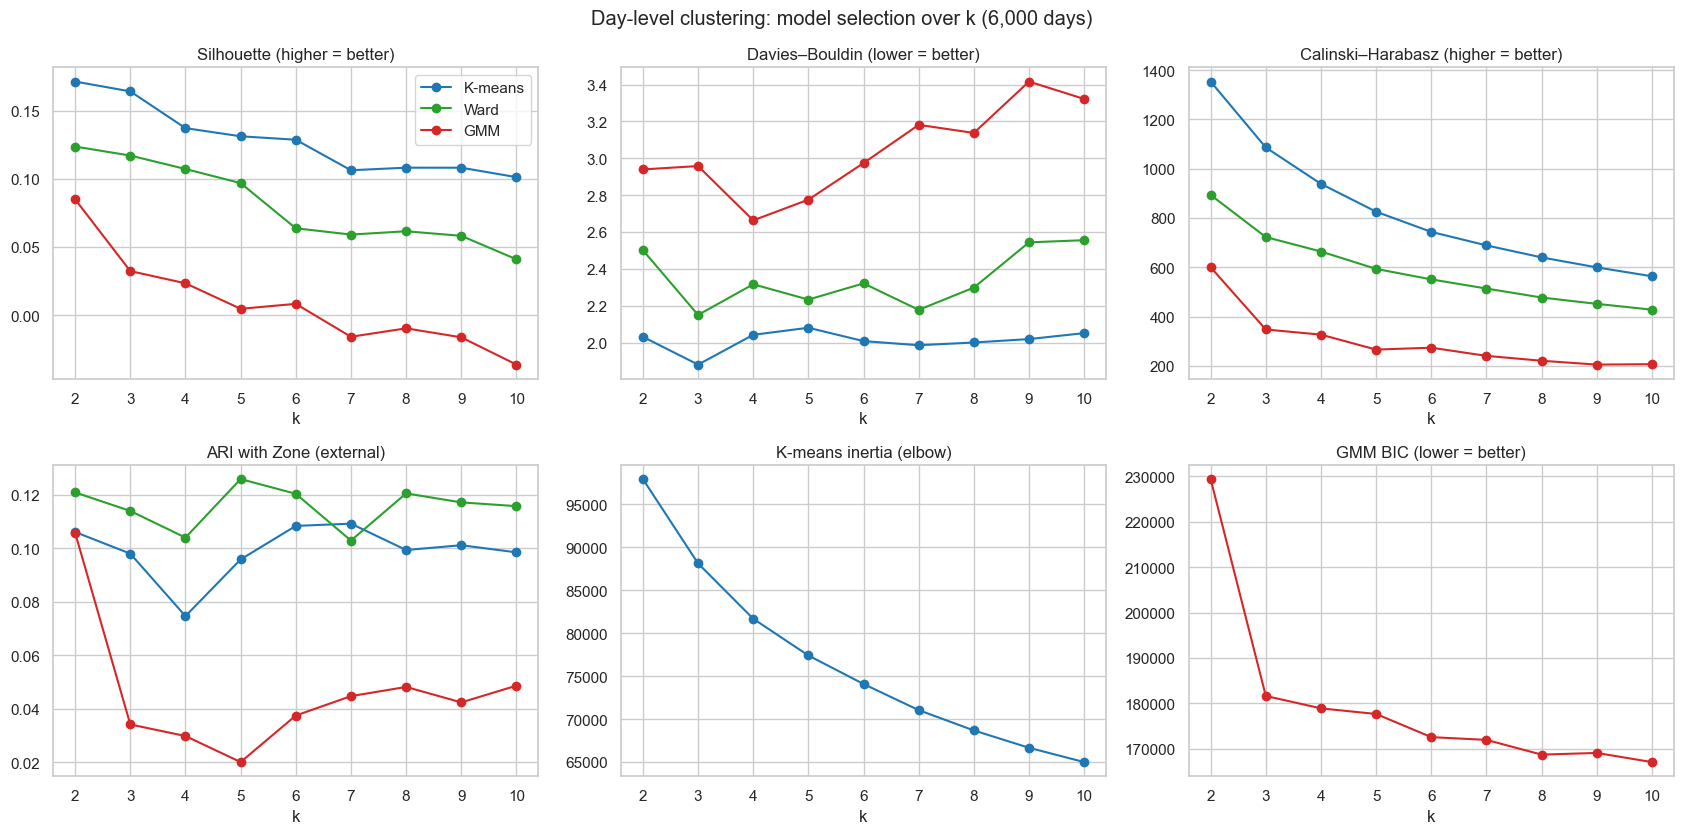

In [29]:
ALG_COLORS = {"K-means": "#1f77b4", "Ward": "#2ca02c", "GMM": "#d62728"}
panels = [("silhouette", "Silhouette (higher = better)"), ("Davies-Bouldin", "Davies–Bouldin (lower = better)"),
          ("Calinski-Harabasz", "Calinski–Harabasz (higher = better)"), ("ARI zone", "ARI with Zone (external)"),
          ("inertia", "K-means inertia (elbow)"), ("BIC", "GMM BIC (lower = better)")]
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for ax, (col, title) in zip(axes.ravel(), panels):
    for alg in ALGS:
        s = sweep[sweep["algorithm"] == alg]
        if s[col].notna().any():
            ax.plot(s["k"], s[col], marker="o", color=ALG_COLORS[alg], label=alg)
    ax.set(title=title, xlabel="k"); ax.set_xticks(range(2, 11))
axes[0, 0].legend()
plt.suptitle("Day-level clustering: model selection over k (6,000 days)"); plt.tight_layout()
savefig("p3_k_selection"); plt.show()

**Stability (all three algorithms).** A good clustering should not change much when the data change slightly.
For every algorithm and every k we refit on 10 random subsamples containing 80% of the 6,000 days (drawn without
replacement) and compare the subsample's partition with the reference partition **on the same days** (ARI;
1 = identical). This needs no rule for assigning left-out points, so it treats K-means, Ward (which has no
`predict`) and GMM identically. Each (algorithm, k) result is cached separately.

cache hit: p3_stab_ward (0.0s)


cache hit: p3_stab_K-means_2 (0.0s)


cache hit: p3_stab_K-means_3 (0.0s)


cache hit: p3_stab_K-means_4 (0.0s)


cache hit: p3_stab_K-means_5 (0.0s)


cache hit: p3_stab_K-means_6 (0.0s)


... (9 outputs left out)

cache hit: p3_stab_GMM_7 (0.0s)


cache hit: p3_stab_GMM_8 (0.0s)


cache hit: p3_stab_GMM_9 (0.0s)


cache hit: p3_stab_GMM_10 (0.0s)


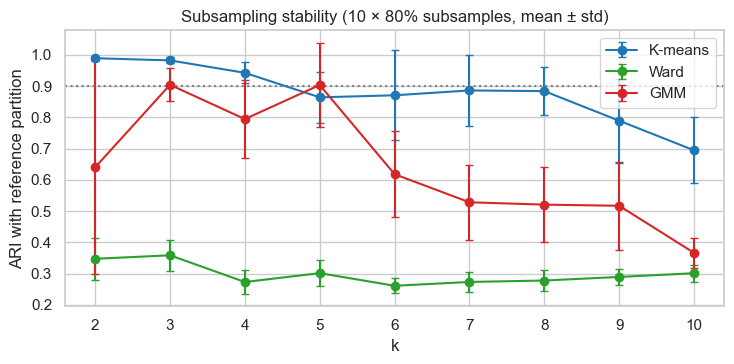

k,2,3,4,5,6,7,8,9,10
algorithm,,,,,,,,,
GMM,0.640,0.904,0.795,0.904,0.618,0.528,0.521,0.517,0.366
K-means,0.990,0.983,0.943,0.864,0.871,0.886,0.884,0.789,0.695
Ward,0.347,0.358,0.273,0.301,0.261,0.273,0.278,0.289,0.301


In [30]:
from scipy.cluster.hierarchy import fcluster
N_SUB, SUB_FRAC = 10, 0.8
SUB_IDX = [np.random.default_rng(RANDOM_STATE + b).choice(len(X_vis), size=int(SUB_FRAC * len(X_vis)), replace=False)
           for b in range(N_SUB)]

def stability_kmeans_gmm(alg, k):
    ref, scores = labels_k[(alg, k)], []
    for b, idx in enumerate(SUB_IDX):
        lab, _ = fit_cluster(alg, k, X_vis[idx], seed=b)
        scores.append(adjusted_rand_score(ref[idx], lab))
    return scores

def stability_ward():
    # one Ward tree per subsample, cut at every k
    out = {k: [] for k in range(2, 11)}
    for idx in SUB_IDX:
        Z_sub = linkage(X_vis[idx], method="ward")
        for k in out:
            out[k].append(adjusted_rand_score(labels_k[("Ward", k)][idx], fcluster(Z_sub, t=k, criterion="maxclust")))
    return out

STAB_PARAMS = dict(n_sub=N_SUB, frac=SUB_FRAC, seed=RANDOM_STATE, scheme="subsample")
stab_scores = {("Ward", k): v for k, v in cached("p3_stab_ward", stability_ward, **STAB_PARAMS).items()}
for alg in ["K-means", "GMM"]:
    for k in range(2, 11):
        stab_scores[(alg, k)] = cached(f"p3_stab_{alg}_{k}", lambda a=alg, k=k: stability_kmeans_gmm(a, k), **STAB_PARAMS)
stab = pd.DataFrame([{"algorithm": a, "k": k, "stability": np.mean(v), "stability std": np.std(v)}
                     for (a, k), v in stab_scores.items()])
sweep = sweep.drop(columns=[c for c in ["stability", "stability std"] if c in sweep]).merge(stab, on=["algorithm", "k"])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for alg in ALGS:
    st_ = sweep[sweep["algorithm"] == alg]
    ax.errorbar(st_["k"], st_["stability"], yerr=st_["stability std"], marker="o", capsize=3, color=ALG_COLORS[alg], label=alg)
ax.axhline(0.9, ls=":", color="grey"); ax.set_xticks(range(2, 11))
ax.set(xlabel="k", ylabel="ARI with reference partition", title="Subsampling stability (10 × 80% subsamples, mean ± std)")
ax.legend(); plt.tight_layout(); savefig("p3_stability"); plt.show()
sweep.pivot(index="k", columns="algorithm", values="stability").round(3).T

**Why does GMM score so badly on the internal metrics?** With full covariance it can put a component on any
low-dimensional "spike" in the data. Rainfall is exactly 0 on 63% of days, so a single standardised value is
shared by most of the sample; GMM can give one component (almost) zero variance in that direction and an
arbitrarily high likelihood. We check the variance of `Rainfall_log1p` inside each component:

In [31]:
_, gmm5 = fit_cluster("GMM", 5, X_vis)
ri = FEATURE_SETS["core"].index("Rainfall_log1p")
dry = X_vis[:, ri] == X_vis[:, ri].min()
gmm_lab = gmm5.predict(X_vis)
pd.DataFrame({
    "weight": gmm5.weights_,
    "var(Rainfall_log1p) inside component": gmm5.covariances_[:, ri, ri],
    "share of dry days (Rainfall = 0)": [dry[gmm_lab == c].mean() for c in range(5)],
}).round(4)

,weight,var(Rainfall_log1p) inside component,share of dry days (Rainfall = 0)
0,0.6151,0.0000,1.0000
1,0.1062,0.8763,0.0712
2,0.0983,1.5468,0.2973
3,0.0801,2.0561,0.1860
4,0.1003,1.4991,0.0166


Inspect the table for components concentrated on dry days and near the covariance regularisation floor. Point masses from dry weather and imputation can be poorly described by continuous Gaussians. BIC and compactness metrics answer different questions; neither alone establishes a true weather taxonomy.

In [32]:
def gmm_sensitivity():
    rows = []
    for k in [3, 5]:
        for reg in [1e-6, 1e-3, 1e-2, 1e-1]:
            g = GaussianMixture(n_components=k, covariance_type="full", n_init=2, reg_covar=reg,
                                random_state=RANDOM_STATE).fit(X_vis)
            lab = g.predict(X_vis)
            rows.append({"k": k, "reg_covar": reg, "converged": g.converged_, "EM iterations": g.n_iter_,
                         "largest weight": g.weights_.max(),
                         "min var(Rainfall_log1p)": g.covariances_[:, ri, ri].min(),
                         "silhouette": silhouette_score(X_vis, lab) if len(np.unique(lab)) > 1 else np.nan,
                         "Davies-Bouldin": davies_bouldin_score(X_vis, lab) if len(np.unique(lab)) > 1 else np.nan,
                         "ARI zone": adjusted_rand_score(y_vis, lab), "BIC": g.bic(X_vis)})
    return pd.DataFrame(rows)

gmm_sens = cached("p3_gmm_sensitivity", gmm_sensitivity, n_per_zone=N_PER_ZONE, seed=RANDOM_STATE, version=1)
gmm_sens.round(4)

cache hit: p3_gmm_sensitivity (0.0s)


,k,reg_covar,converged,EM iterations,largest weight,min var(Rainfall_log1p),silhouette,Davies-Bouldin,ARI zone,BIC
0,3,0.000,True,26,0.6313,0.0000,0.0322,2.9579,0.0341,181636.6187
1,3,0.001,True,29,0.5543,0.0010,0.0174,3.1174,0.0563,207159.2151
2,3,0.010,True,28,0.5091,0.0156,0.0431,2.9579,0.1365,216517.0142
3,3,0.100,True,24,0.4099,0.1451,0.0999,2.6995,0.0796,243419.7182
4,5,0.000,True,30,0.6151,0.0000,0.0045,2.7754,0.0201,177673.6266
5,5,0.001,True,40,0.4805,0.0010,0.0275,2.8477,0.0344,200830.6126
6,5,0.010,True,27,0.3722,0.0131,0.0490,2.7112,0.0604,210004.3633
7,5,0.100,True,34,0.3266,0.1286,0.0742,2.3471,0.0777,239361.8706


Use the convergence and covariance table above to distinguish numerical convergence from model suitability. Covariance regularisation prevents an exactly singular fitted Gaussian; very small variance around dry/imputed values can nevertheless dominate likelihood. This sensitivity check does not prove a unique physical cause for all differences between algorithms.

### 3.3 Choosing a descriptive day-level partition

In [33]:
# Selection rule, applied to all 27 (algorithm, k) solutions:
#   1. eligible = subsampling stability >= 0.90 (the partition must be reproducible);
#   2. score    = mean of the ranks on silhouette (high), Davies-Bouldin (low) and Calinski-Harabasz (high);
#   3. choose the eligible solution with the best (lowest) mean rank.
# External metrics (ARI/NMI with zone or season) are NOT used for the choice: they measure agreement with our
# question, not clustering quality, and are reported only for interpretation.
rank = sweep[["algorithm", "k"]].copy()
rank["rank silhouette"] = sweep["silhouette"].rank(ascending=False)
rank["rank DB"] = sweep["Davies-Bouldin"].rank(ascending=True)
rank["rank CH"] = sweep["Calinski-Harabasz"].rank(ascending=False)
rank["mean rank"] = rank[["rank silhouette", "rank DB", "rank CH"]].mean(axis=1)
rank["stability"] = sweep["stability"]
rank["eligible"] = rank["stability"] >= 0.90
rank = rank.sort_values("mean rank")
best_row = rank[rank["eligible"]].iloc[0]
ALG_BEST, K_BEST = best_row["algorithm"], int(best_row["k"])
print(f"selected: {ALG_BEST}, k = {K_BEST}")
display(rank.head(8).round(3))

best = sweep[sweep["k"] == K_BEST].set_index("algorithm")[
    ["silhouette", "Davies-Bouldin", "Calinski-Harabasz", "BIC", "ARI zone", "NMI zone", "ARI season", "stability"]]
print(f"k = {K_BEST}: comparison of the three algorithms")
best.round(3)

selected: K-means, k = 3


,algorithm,k,rank silhouette,rank DB,rank CH,mean rank,stability,eligible
3,K-means,3,2.0,1.0,2.0,1.667,0.983,True
0,K-means,2,1.0,6.0,1.0,2.667,0.990,True
6,K-means,4,3.0,7.0,3.0,4.333,0.943,True
12,K-means,6,5.0,4.0,6.0,5.000,0.871,False
9,K-means,5,4.0,9.0,5.0,6.000,0.864,False
15,K-means,7,11.0,2.0,8.0,7.000,0.886,False
18,K-means,8,8.0,3.0,10.0,7.000,0.884,False
4,Ward,3,7.0,10.0,7.0,8.000,0.358,False


k = 3: comparison of the three algorithms


,silhouette,Davies-Bouldin,Calinski-Harabasz,BIC,ARI zone,NMI zone,ARI season,stability
algorithm,,,,,,,,
K-means,0.164,1.880,1085.792,NaN,0.098,0.122,0.096,0.983
Ward,0.117,2.150,722.379,NaN,0.114,0.150,0.049,0.358
GMM,0.032,2.958,347.402,181636.619,0.034,0.097,0.005,0.904


The stability threshold and rank rule were introduced after the earlier exploratory analysis, not preregistered. They choose a descriptive partition under a specific geometry, not a uniquely true number of weather regimes. Low absolute silhouette remains a limitation even when repeatability is high. Additional rule and sampling sensitivity checks follow below.

### 3.4 Visualising and interpreting the clusters

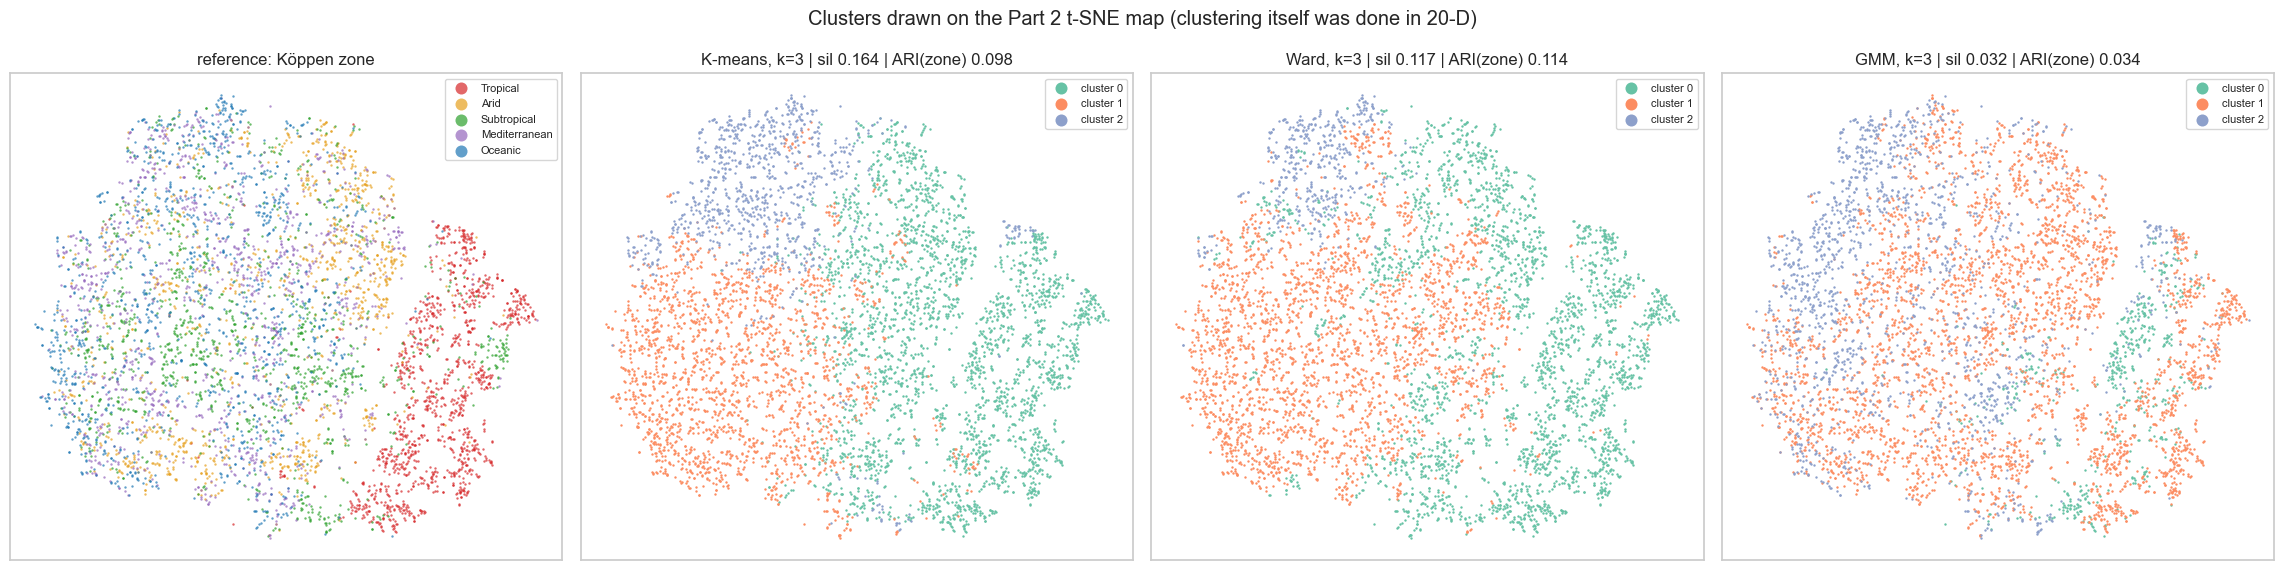

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(23, 5.8))
scatter_by_zone(axes[0], E2); axes[0].set_title("reference: Köppen zone"); axes[0].legend(markerscale=5, fontsize=8)
cl_cmap = plt.get_cmap("Set2")
for ax, alg in zip(axes[1:], ALGS):
    lab = labels_k[(alg, K_BEST)]
    for c in np.unique(lab):
        m = lab == c
        ax.scatter(E2[m, 0], E2[m, 1], s=3, color=cl_cmap(c), label=f"cluster {c}", linewidths=0)
    r = sweep[(sweep["algorithm"] == alg) & (sweep["k"] == K_BEST)].iloc[0]
    ax.set_title(f"{alg}, k={K_BEST} | sil {r['silhouette']:.3f} | ARI(zone) {r['ARI zone']:.3f}")
    ax.set_xticks([]); ax.set_yticks([]); ax.legend(markerscale=5, fontsize=8)
plt.suptitle("Clusters drawn on the Part 2 t-SNE map (clustering itself was done in 20-D)")
plt.tight_layout(); savefig("p3_clusters_on_tsne"); plt.show()

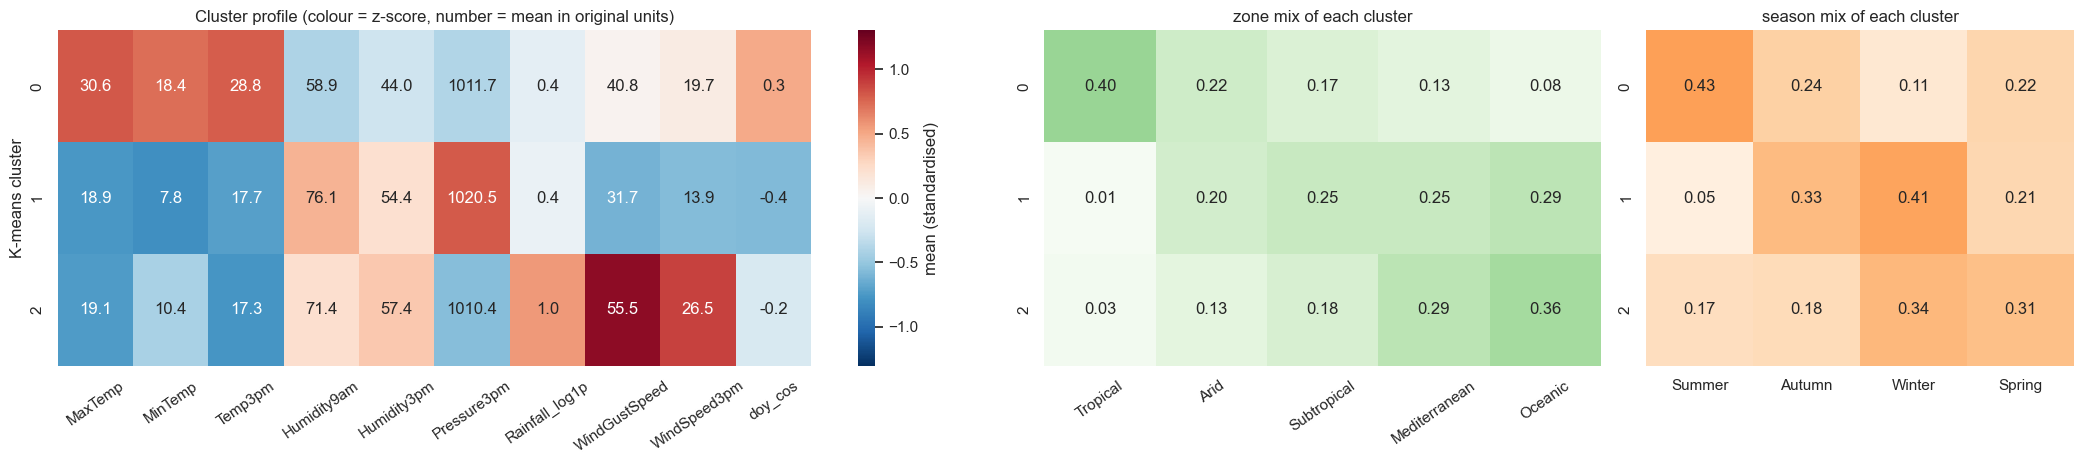

cluster sizes: [2891 2118  991]


In [35]:
km_lab = labels_k[("K-means", K_BEST)]
profile_cols = ["MaxTemp", "MinTemp", "Temp3pm", "Humidity9am", "Humidity3pm", "Pressure3pm",
                "Rainfall_log1p", "WindGustSpeed", "WindSpeed3pm", "doy_cos"]
raw_vis = F.loc[sample_idx]
fig, axes = plt.subplots(1, 3, figsize=(21, 4.8), gridspec_kw={"width_ratios": [2.2, 1.3, 1]})
z_means = pd.DataFrame(X_vis, columns=FEATURE_SETS["core"]).groupby(km_lab)[profile_cols].mean()
annot = raw_vis.groupby(km_lab)[profile_cols].mean().round(1)        # annotate with real units
sns.heatmap(z_means, annot=annot, fmt="", cmap="RdBu_r", center=0, vmin=-1.3, vmax=1.3, ax=axes[0],
            cbar_kws={"label": "mean (standardised)"})
axes[0].set(title="Cluster profile (colour = z-score, number = mean in original units)", ylabel="K-means cluster")
axes[0].tick_params(axis="x", rotation=35)
ct_zone = pd.crosstab(km_lab, y_vis, normalize="index")[ZONE_ORDER]
sns.heatmap(ct_zone, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set(title="zone mix of each cluster", xlabel="", ylabel=""); axes[1].tick_params(axis="x", rotation=35)
ct_season = pd.crosstab(km_lab, season_vis, normalize="index")[["Summer", "Autumn", "Winter", "Spring"]]
sns.heatmap(ct_season, annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1, ax=axes[2], cbar=False)
axes[2].set(title="season mix of each cluster", xlabel="", ylabel="")
plt.tight_layout(); savefig("p3_cluster_profiles"); plt.show()
print("cluster sizes:", np.bincount(km_lab))

The temperature, wind, rain and pressure profiles permit descriptive labels such as warm, cool with weaker winds, and cool with stronger winds and more rain. They do not independently verify synoptic fronts. Low agreement with Zone means these particular representations and clustering methods do not closely reproduce the climate labels; it is not a proof that single days contain no climate information.

### 3.5 Extra: station climate profiles

Aggregate each station to twelve monthly means of four variables. This changes the unit, features, sample size and clustering setup. Differences from day-level ARI therefore cannot be attributed solely to temporal averaging. Coordinates and labels are not clustering inputs; k=5 is an exploratory comparison with the five-label task.

In [36]:
PROFILE_VARS = ["MaxTemp", "MinTemp", "Humidity3pm", "Rainfall"]
station_profile = (df.assign(month=df["Date"].dt.month, Location=groups)
                     .pivot_table(index="Location", columns="month", values=PROFILE_VARS, aggfunc="mean"))
assert station_profile.notna().all().all()
S = StandardScaler().fit_transform(station_profile.values)
station_zone_true = station_zone.loc[station_profile.index].values
print("station profile matrix:", S.shape)

st_rows = []
for k in range(3, 8):
    for alg in ["K-means", "Ward"]:
        lab = (KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(S) if alg == "K-means"
               else AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(S))
        st_rows.append({"algorithm": alg, "k": k, "silhouette": silhouette_score(S, lab),
                        "ARI zone": adjusted_rand_score(station_zone_true, lab),
                        "NMI zone": normalized_mutual_info_score(station_zone_true, lab)})
st_sweep = pd.DataFrame(st_rows)
st_sweep.pivot(index="k", columns="algorithm", values=["silhouette", "ARI zone", "NMI zone"]).round(3)

station profile matrix: (48, 48)


silhouette        ARI zone        NMI zone       
algorithm    K-means   Ward  K-means   Ward  K-means   Ward
k                                                          
3              0.290  0.293    0.351  0.282    0.551  0.442
4              0.317  0.321    0.404  0.331    0.638  0.536
5              0.333  0.319    0.284  0.345    0.541  0.540
6              0.287  0.294    0.370  0.412    0.569  0.603
7              0.301  0.299    0.462  0.420    0.633  0.625

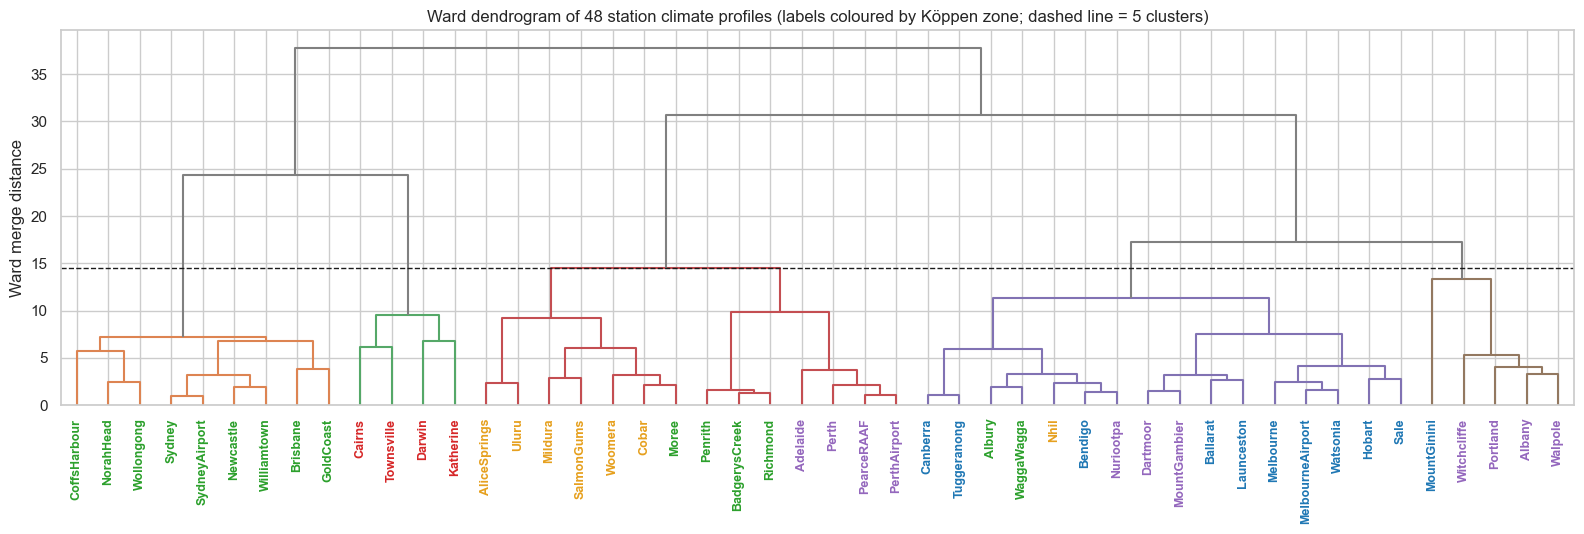

In [37]:
Z = linkage(S, method="ward")
st_lab = AgglomerativeClustering(n_clusters=5, linkage="ward").fit_predict(S)
fig, ax = plt.subplots(figsize=(16, 5.5))
dendrogram(Z, labels=station_profile.index.tolist(), leaf_rotation=90, leaf_font_size=9,
           color_threshold=Z[-5, 2] + 1e-9, above_threshold_color="grey", ax=ax)
for t in ax.get_xticklabels():                         # leaf labels coloured by the Köppen zone
    t.set_color(ZONE_COLORS[station_zone[t.get_text()]]); t.set_fontweight("bold")
ax.axhline(Z[-5, 2] + 1e-9, ls="--", color="k", lw=1)
ax.set(title="Ward dendrogram of 48 station climate profiles (labels coloured by Köppen zone; dashed line = 5 clusters)",
       ylabel="Ward merge distance")
plt.tight_layout(); savefig("p3_station_dendrogram"); plt.show()

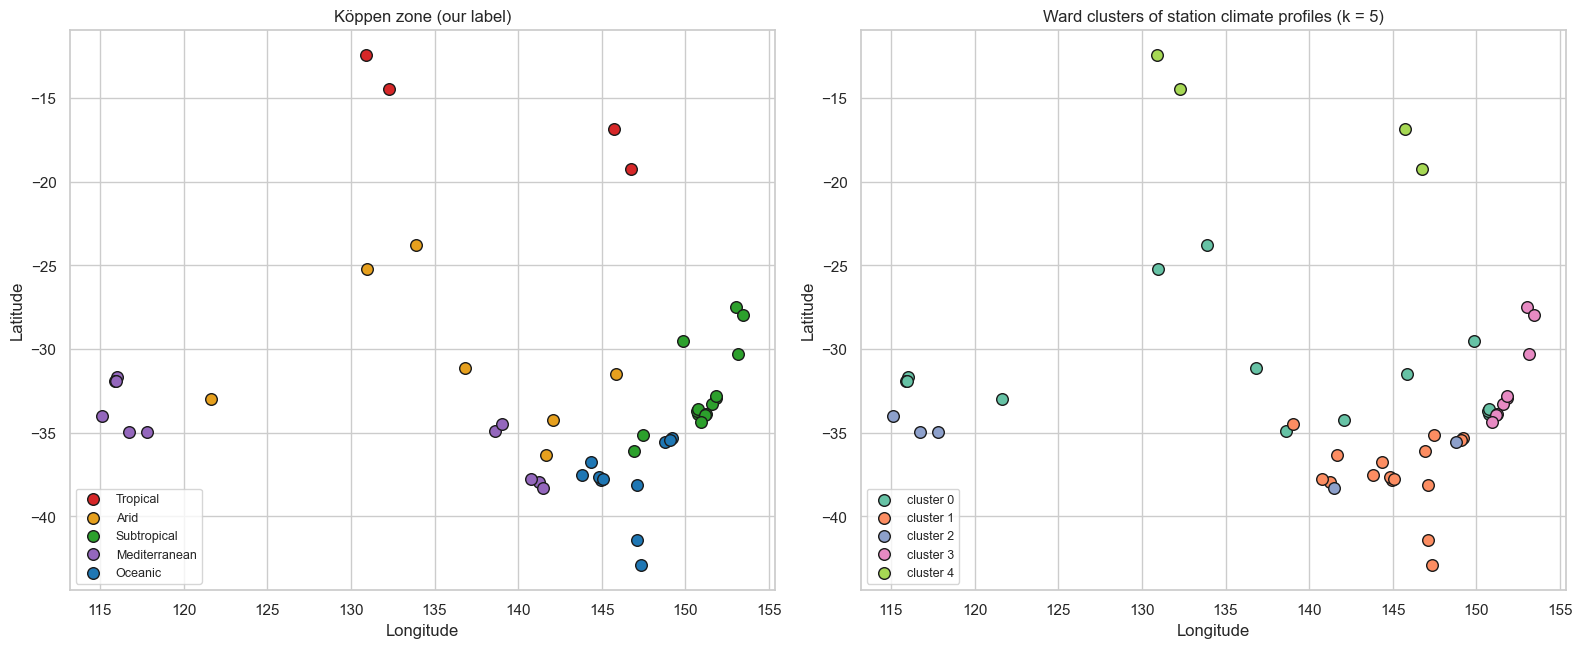

zone     Tropical  Arid  Subtropical  Mediterranean  Oceanic
cluster                                                     
0               0     6            4              4        0
1               0     1            2              3       10
2               0     0            0              4        1
3               0     0            9              0        0
4               4     0            0              0        0
cluster 0: Adelaide, AliceSprings, BadgerysCreek, Cobar, Mildura, Moree, PearceRAAF, Penrith, Perth, PerthAirport, Richmond, SalmonGums, Uluru, Woomera
cluster 1: Albury, Ballarat, Bendigo, Canberra, Dartmoor, Hobart, Launceston, Melbourne, MelbourneAirport, MountGambier, Nhil, Nuriootpa, Sale, Tuggeranong, WaggaWagga, Watsonia
cluster 2: Albany, MountGinini, Portland, Walpole, Witchcliffe
cluster 3: Brisbane, CoffsHarbour, GoldCoast, Newcastle, NorahHead, Sydney, SydneyAirport, Williamtown, Wollongong
cluster 4: Cairns, Darwin, Katherine, Townsville


In [38]:
loc_xy = zones.set_index("Location").loc[station_profile.index, ["lon", "lat"]]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for zone in ZONE_ORDER:
    m = station_zone_true == zone
    axes[0].scatter(loc_xy["lon"][m], loc_xy["lat"][m], s=70, color=ZONE_COLORS[zone], edgecolor="k", label=zone)
axes[0].set_title("Köppen zone (our label)")
for c in range(5):
    m = st_lab == c
    axes[1].scatter(loc_xy["lon"][m], loc_xy["lat"][m], s=70, color=cl_cmap(c), edgecolor="k", label=f"cluster {c}")
axes[1].set_title("Ward clusters of station climate profiles (k = 5)")
for ax in axes:
    ax.set(xlabel="Longitude", ylabel="Latitude"); ax.set_aspect("equal"); ax.legend(loc="lower left", fontsize=9)
plt.tight_layout(); savefig("p3_station_clusters_map"); plt.show()

print(pd.crosstab(pd.Series(st_lab, name="cluster"), pd.Series(station_zone_true, name="zone"))[ZONE_ORDER])
for c in range(5):
    print(f"cluster {c}: " + ", ".join(station_profile.index[st_lab == c]))

In [39]:
compare = pd.DataFrame({
    "unit clustered": ["one day (6,000 days)", "one day (6,000 days)", "station profile (48 stations)"],
    "algorithm": ["K-means k=3 (best by internal metrics)", "Ward k=5 (same k as zones)", "Ward k=5"],
    "ARI with Zone": [sweep.query("algorithm=='K-means' and k==3")["ARI zone"].item(),
                      sweep.query("algorithm=='Ward' and k==5")["ARI zone"].item(),
                      st_sweep.query("algorithm=='Ward' and k==5")["ARI zone"].item()],
    "NMI with Zone": [sweep.query("algorithm=='K-means' and k==3")["NMI zone"].item(),
                      sweep.query("algorithm=='Ward' and k==5")["NMI zone"].item(),
                      st_sweep.query("algorithm=='Ward' and k==5")["NMI zone"].item()],
}).round(3)
compare

,unit clustered,algorithm,ARI with Zone,NMI with Zone
0,"one day (6,000 days)",K-means k=3 (best by internal metrics),0.098,0.122
1,"one day (6,000 days)",Ward k=5 (same k as zones),0.126,0.180
2,station profile (48 stations),Ward k=5,0.345,0.540


### 3.6 Scope of the station-profile comparison

Read cluster membership and the cross-tabulation above. A coastal Subtropical subset is not an entire Köppen class. Coast/inland interpretations are hypotheses based on station names and coordinates, not a tested distance-to-coast mechanism. The dataset has only 48 labelled stations; ARI comparisons across day and station units are descriptive.

### 3.7 Selection-rule and sampling sensitivity
The earlier ranking rule was post-hoc. Vary its stability threshold and remove one compactness criterion at a time. Natural-frequency sampling checks the influence of label-balanced sampling. Perturb entire stations or years rather than scattered days, using the same reference scaling; these diagnostics examine composition sensitivity, not prediction on unobserved stations. Low silhouette is not cured by high stability.

In [40]:
rule_rows=[]
for threshold in [.80,.85,.90,.95]:
    for metrics in [["silhouette","Davies-Bouldin","Calinski-Harabasz"],["silhouette","Davies-Bouldin"],["silhouette","Calinski-Harabasz"],["Davies-Bouldin","Calinski-Harabasz"]]:
        eligible=sweep[sweep.stability>=threshold].copy()
        if len(eligible):
            ranking=sum(sweep[m].rank(ascending=(m=="Davies-Bouldin")) for m in metrics)/len(metrics)
            winner=eligible.loc[ranking.loc[eligible.index].idxmin()]
            rule_rows.append({"threshold":threshold,"metrics":";".join(metrics),"algorithm":winner.algorithm,"k":int(winner.k)})
export_table("clustering_rule_sensitivity",pd.DataFrame(rule_rows))

def cluster_sampling_controls():
    out=[]
    natural=df.sample(n=len(sample_idx),random_state=42).index
    xn=build_preprocessor().fit_transform(F.loc[natural,FEATURE_SETS["core"]])
    for alg in ALGS:
        lab,_=fit_cluster(alg,3,xn)
        out.append({"scheme":"natural-frequency","algorithm":alg,"repeat":0,"n":len(xn),"ARI_reference":np.nan,"ARI_zone":adjusted_rand_score(y[natural],lab),"silhouette":silhouette_score(xn,lab)})
    year=df.loc[sample_idx,"Date"].dt.year.to_numpy()
    for scheme,block in [("station-block",g_vis),("year-block",year)]:
        unique=np.unique(block)
        for rep in range(5):
            kept=np.random.default_rng(100+rep).choice(unique,max(2,int(.8*len(unique))),replace=False)
            idx=np.flatnonzero(np.isin(block,kept))
            for alg in ALGS:
                lab,_=fit_cluster(alg,3,X_vis[idx],seed=42+rep)
                out.append({"scheme":scheme,"algorithm":alg,"repeat":rep,"n":len(idx),"ARI_reference":adjusted_rand_score(labels_k[(alg,3)][idx],lab),"ARI_zone":adjusted_rand_score(y_vis[idx],lab),"silhouette":silhouette_score(X_vis[idx],lab)})
    return pd.DataFrame(out)
cluster_controls=cached("cluster_sampling_controls",cluster_sampling_controls)
export_table("clustering_sampling_controls",cluster_controls)
cluster_controls.groupby(["scheme","algorithm"])[["ARI_reference","ARI_zone","silhouette"]].mean().round(3)

cache hit: cluster_sampling_controls (0.0s)


ARI_reference  ARI_zone  silhouette
scheme            algorithm                                     
natural-frequency GMM                  NaN     0.004       0.046
                  K-means              NaN     0.033       0.158
                  Ward                 NaN     0.049       0.126
station-block     GMM                0.853     0.053       0.035
                  K-means            0.930     0.082       0.163
                  Ward               0.312     0.079       0.121
year-block        GMM                0.881     0.021       0.047
                  K-means            0.976     0.099       0.163
                  Ward               0.337     0.096       0.122

## 4. Prediction: Training and Testing

**Question.** Given the labels, how well can simple models classify the climate zone of a single day?

### 4.1 Target, models and why we chose them

* **Target**: `Zone` (5 classes, Köppen-derived, Section 0.2). Classes are moderately imbalanced
  (Tropical 7.6% … Subtropical 32.2%), so besides accuracy we always report **macro-F1** (every zone counts equally).
* **Features**: the 20 `core` features from Part 1 (no station-specific sensors, no missing indicators).
* **Logistic Regression (multinomial)** — a linear model: one weight vector per zone, softmax over the five scores.
  It is the natural linear baseline, gives class probabilities (used for ROC in Part 5), and its
  coefficients are interpretable. Default regularisation `C = 1`.
* **Decision Tree (CART, Gini)** — a non-linear model made of axis-aligned threshold rules such as
  "MinTemp > 18.5 °C". It can represent interactions that LR cannot (e.g. *hot and dry* vs *hot and humid*), and
  its rules are readable. We first train it with **default settings (no depth limit)** to see what an
  unconstrained model does; Part 5 tunes it.

Both models are sklearn Pipelines `median imputation → standardisation → model`, so the imputation medians and the
scaling statistics are learned from the training set only.

### 4.2 Two 70/30 splits, two questions

| Split | How | Question it answers |
|---|---|---|
| **Random** (required by the task) | stratified by `Zone`, 70% / 30% of the rows | Can the model classify *new days* of stations it has already seen? |
| **Station-grouped** | 70% / 30% of the **stations** (`GroupShuffleSplit`); no station appears on both sides | Can it classify days from *stations it has never seen*? |

Both splits were created in Section 1.6 and are reused here. The grouped test set contains 15 stations from all
5 zones.

In [41]:
X_all = F[FEATURE_SETS["core"]]
ALL = np.arange(len(df))
SPLITS = {"random": (rand_tr, rand_te), "grouped": (grp_tr, grp_te)}
print("grouped test stations:", ", ".join(sorted(groups.iloc[grp_te].unique())))
print(pd.DataFrame({s: pd.Series(y[b]).value_counts() for s, (a, b) in SPLITS.items()}).loc[ZONE_ORDER]
      .rename(columns=lambda c: f"{c} test rows"))

def make_model(name, **params):
    if name == "LR":
        est = LogisticRegression(max_iter=3000, **params)
    elif name == "DT":
        est = DecisionTreeClassifier(random_state=RANDOM_STATE, **params)
    else:
        raise ValueError(name)
    return make_pipeline(build_preprocessor(), est)

grouped test stations: AliceSprings, BadgerysCreek, Bendigo, Cairns, Dartmoor, MelbourneAirport, Newcastle, Nhil, NorahHead, Nuriootpa, Richmond, SydneyAirport, Tuggeranong, Uluru, Watsonia
               random test rows  grouped test rows
Tropical                   3255               3040
Arid                       5467               6196
Subtropical               13741              15070
Mediterranean             10058               6018
Oceanic                   10215              12097


### 4.3 Training

Training is a single `fit` on the training rows. For LR, `lbfgs` minimises the multinomial cross-entropy plus an
L2 penalty `‖w‖² / (2C)`. For the tree, CART greedily chooses at every node the feature and threshold that most
reduce Gini impurity, and continues until no admissible split remains (normally pure leaves). Identical predictor rows with different labels can leave a small training error even without explicit pruning.

In [42]:
import time
models_p4, fit_info = {}, []
for split, (a, b) in SPLITS.items():
    for name in ["LR", "DT"]:
        t0 = time.time()
        m = make_model(name).fit(X_all.iloc[a], y[a])
        info = {"split": split, "model": name, "fit time (s)": round(time.time() - t0, 1)}
        if name == "DT":
            info.update(depth=m[-1].get_depth(), leaves=m[-1].get_n_leaves())
        fit_info.append(info); models_p4[(split, name)] = m
pd.DataFrame(fit_info)

,split,model,fit time (s),depth,leaves
0,random,LR,1.5,NaN,NaN
1,random,DT,1.4,35.0,18947.0
2,grouped,LR,1.3,NaN,NaN
3,grouped,DT,1.3,36.0,17470.0


The unconstrained tree grows to a depth of about 35 with roughly 18,000 leaves for ~100,000 training days, i.e.
on average about 5–6 training days per leaf. This already suggests memorisation.

### 4.4 Evaluation on the training set, test set and entire set

In [43]:
from sklearn.metrics import confusion_matrix

def evaluate(model, idx):
    pred = model.predict(X_all.iloc[idx])
    return {"accuracy": accuracy_score(y[idx], pred),
            "macro-F1": f1_score(y[idx], pred, average="macro"),
            "weighted-F1": f1_score(y[idx], pred, average="weighted")}, pred

eval_rows, preds_p4 = [], {}
for (split, name), m in models_p4.items():
    a, b = SPLITS[split]
    for part, idx in [("train", a), ("test", b), ("entire", ALL)]:
        res, pred = evaluate(m, idx)
        preds_p4[(split, name, part)] = pred
        eval_rows.append({"split": split, "model": name, "set": part, **res})
p4_table = pd.DataFrame(eval_rows)
p4_table.pivot_table(index=["split", "model"], columns="set", values=["accuracy", "macro-F1"]).round(3)[
    [("accuracy", "train"), ("accuracy", "test"), ("accuracy", "entire"),
     ("macro-F1", "train"), ("macro-F1", "test"), ("macro-F1", "entire")]]

accuracy               macro-F1              
set              train   test entire    train   test entire
split   model                                              
grouped DT       1.000  0.533  0.861    1.000  0.536  0.865
        LR       0.609  0.563  0.596    0.625  0.561  0.609
random  DT       1.000  0.652  0.895    1.000  0.669  0.900
        LR       0.604  0.599  0.602    0.620  0.615  0.618

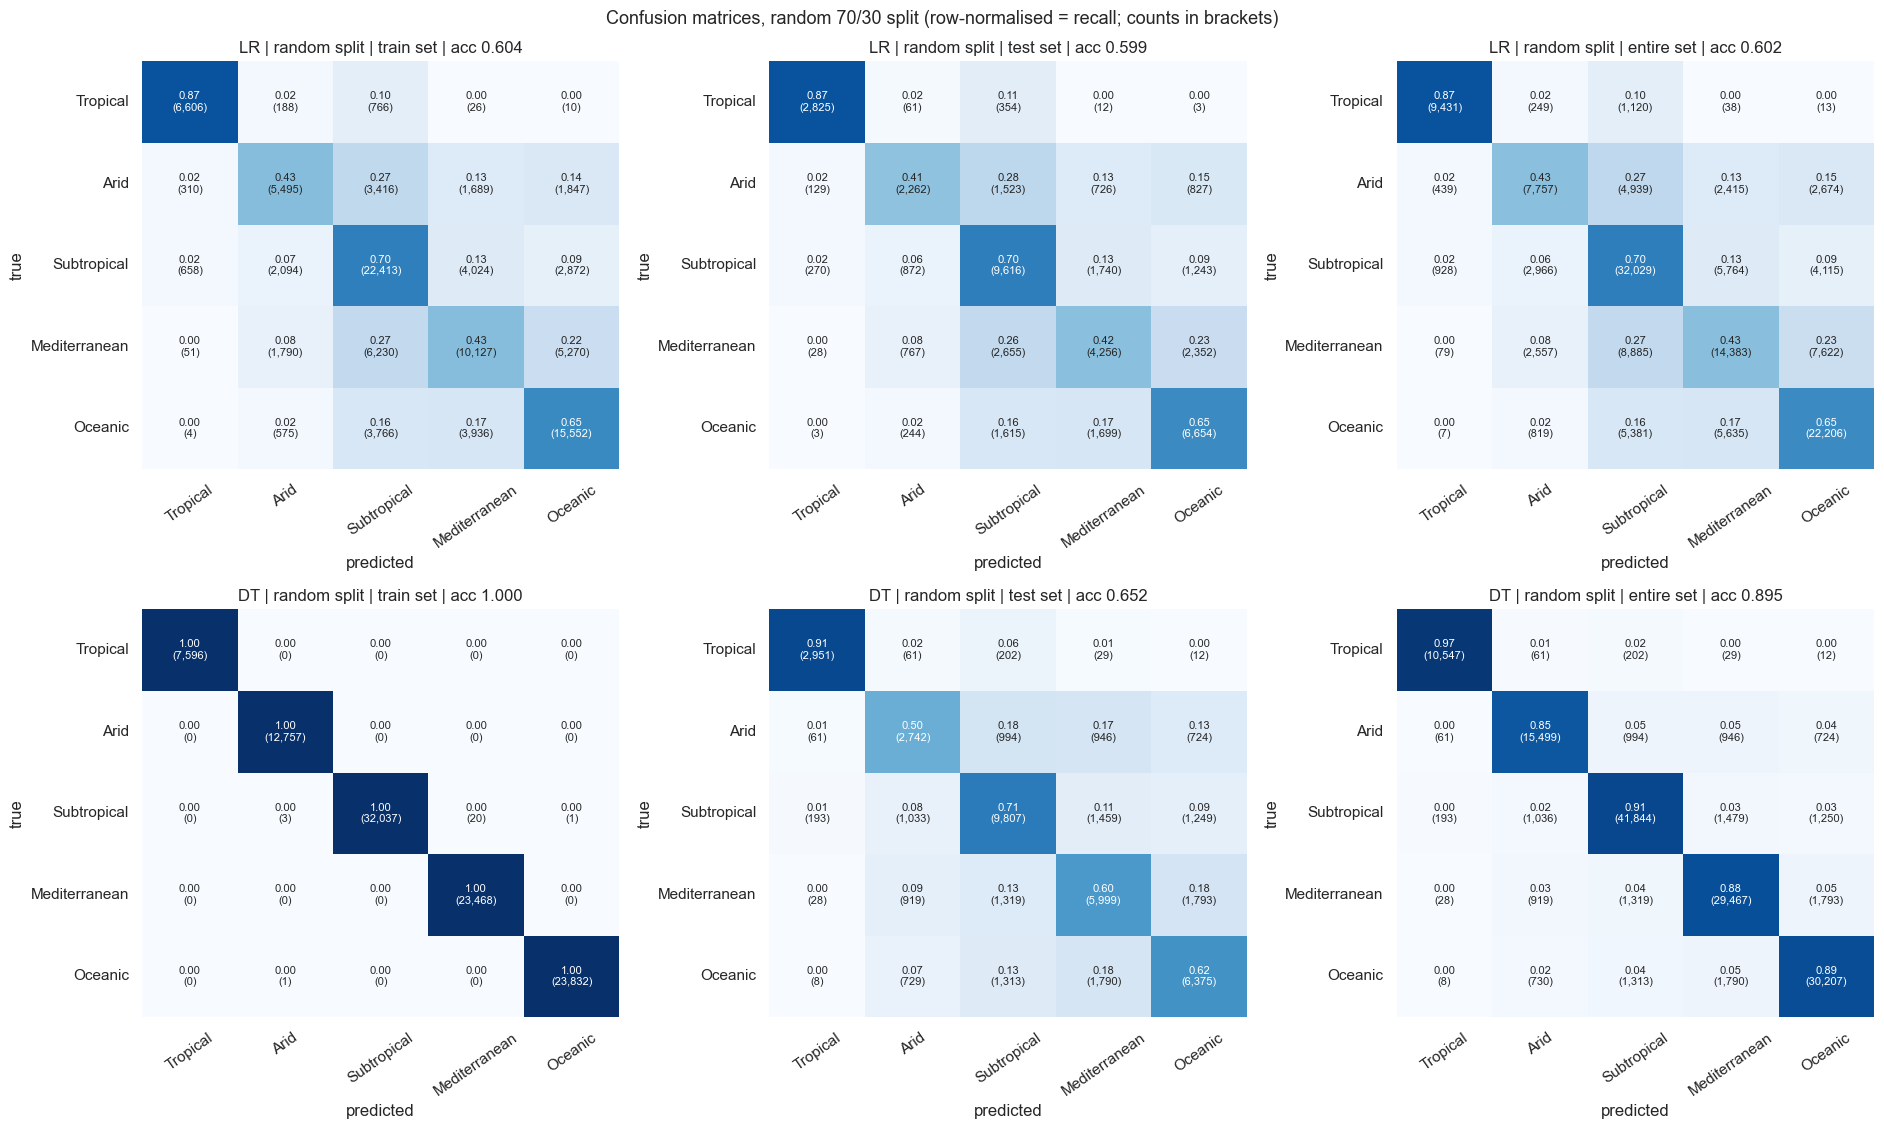

In [44]:
def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=ZONE_ORDER)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{p:.2f}\n({c:,})" for p, c in zip(rp, rc)] for rp, rc in zip(cm_norm, cm)])
    sns.heatmap(cm_norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=ZONE_ORDER, yticklabels=ZONE_ORDER, annot_kws={"fontsize": 8})
    ax.set(title=title, xlabel="predicted", ylabel="true")
    ax.tick_params(axis="x", rotation=35); ax.tick_params(axis="y", rotation=0)
    return cm

fig, axes = plt.subplots(2, 3, figsize=(19, 11.5))
for i, name in enumerate(["LR", "DT"]):
    for j, part in enumerate(["train", "test", "entire"]):
        idx = {"train": rand_tr, "test": rand_te, "entire": ALL}[part]
        acc = accuracy_score(y[idx], preds_p4[("random", name, part)])
        plot_cm(axes[i, j], y[idx], preds_p4[("random", name, part)], f"{name} | random split | {part} set | acc {acc:.3f}")
plt.suptitle("Confusion matrices, random 70/30 split (row-normalised = recall; counts in brackets)", fontsize=13)
plt.tight_layout(); savefig("p4_confusion_random"); plt.show()

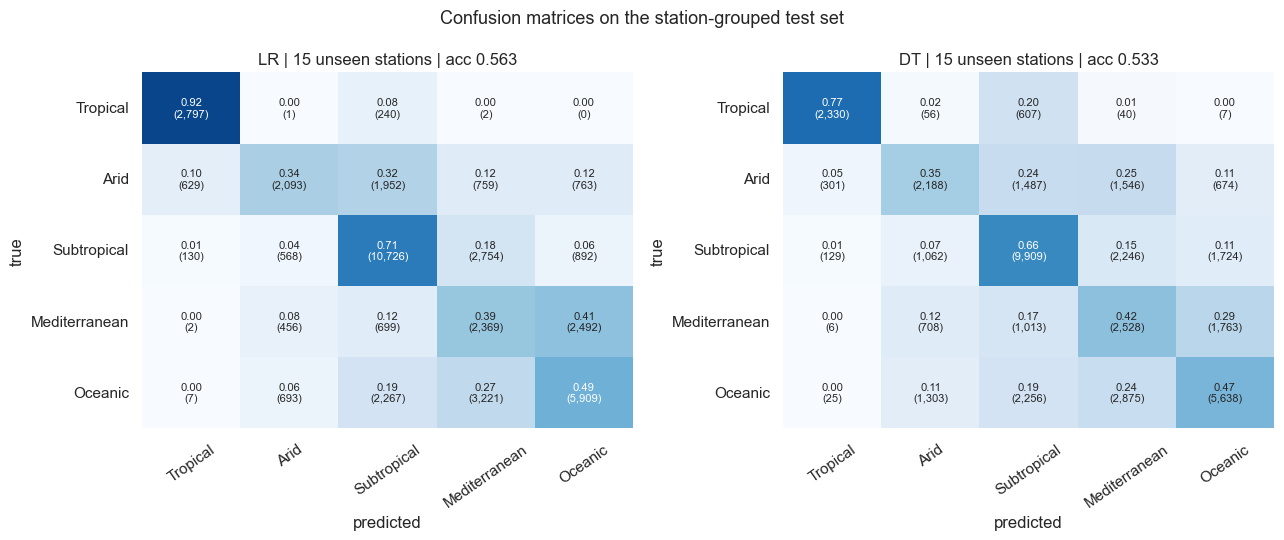

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, name in zip(axes, ["LR", "DT"]):
    acc = accuracy_score(y[grp_te], preds_p4[("grouped", name, "test")])
    plot_cm(ax, y[grp_te], preds_p4[("grouped", name, "test")], f"{name} | 15 unseen stations | acc {acc:.3f}")
plt.suptitle("Confusion matrices on the station-grouped test set", fontsize=13)
plt.tight_layout(); savefig("p4_confusion_grouped"); plt.show()

### 4.5 Illustrative decision boundaries

MinTemp and Humidity3pm were chosen using test comparisons in the earlier exploratory version. The pair is retained only to illustrate model geometry; the displayed two-feature test score is not an independent feature-selection result and does not choose the final model. A depth-6 tree is a fixed visual contrast, not a tuned optimum.

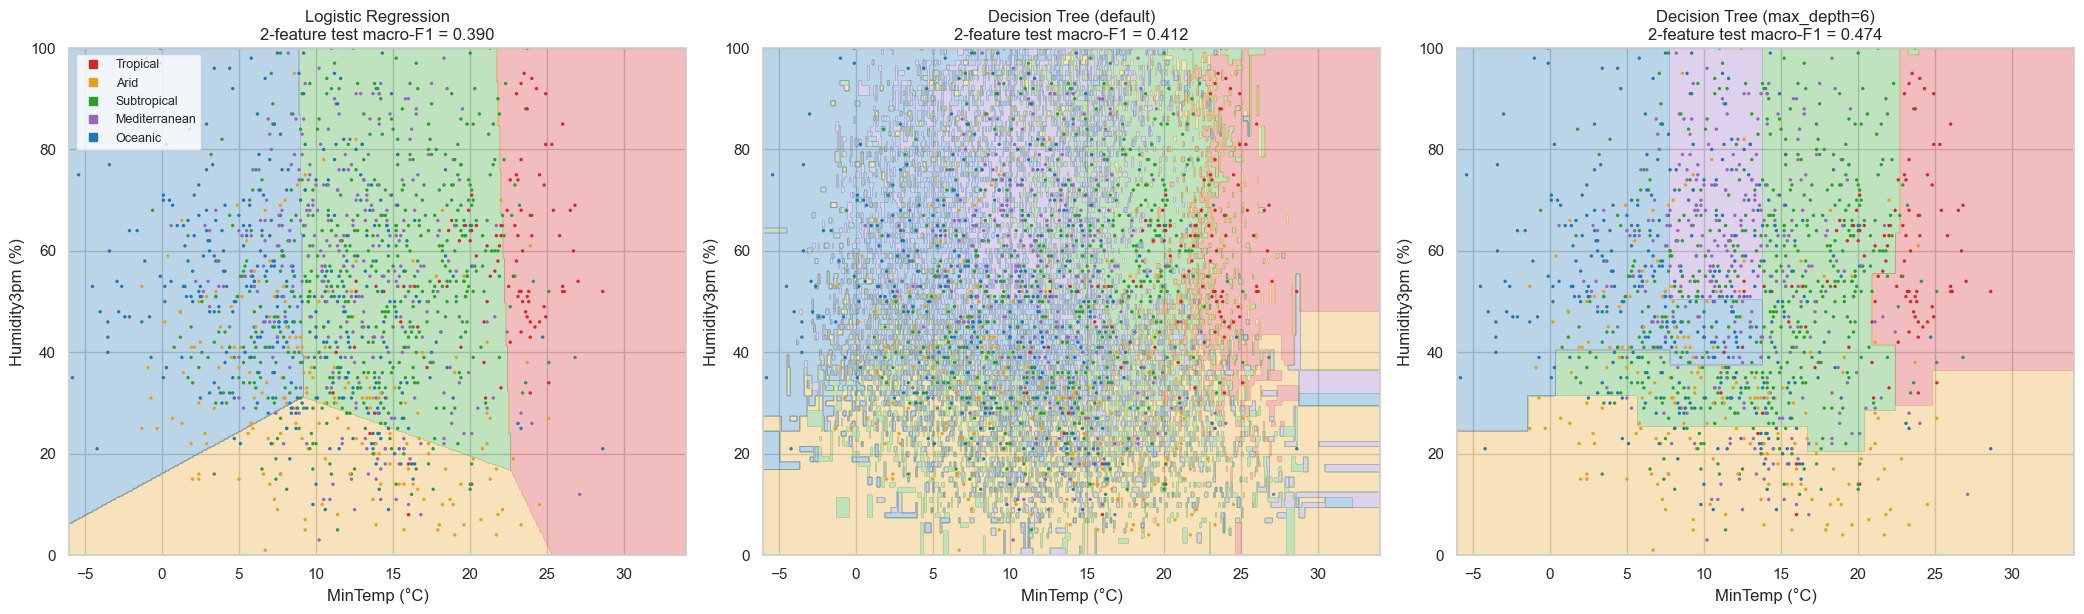

In [46]:
pair = ["MinTemp", "Humidity3pm"]
X2_tr, X2_te = F.iloc[rand_tr][pair], F.iloc[rand_te][pair]
boundary_models = {"Logistic Regression": make_model("LR"), "Decision Tree (default)": make_model("DT"),
                   "Decision Tree (max_depth=6)": make_model("DT", max_depth=6)}
xx, yy = np.meshgrid(np.linspace(-6, 34, 400), np.linspace(0, 100, 400))
grid = pd.DataFrame({pair[0]: xx.ravel(), pair[1]: yy.ravel()})
zone_idx = {z: i for i, z in enumerate(ZONE_ORDER)}
from matplotlib.colors import ListedColormap
cmap5 = ListedColormap([ZONE_COLORS[z] for z in ZONE_ORDER])
pts = np.random.default_rng(RANDOM_STATE).choice(len(rand_te), 1500, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(21, 6.3))
for ax, (title, m) in zip(axes, boundary_models.items()):
    m.fit(X2_tr, y[rand_tr])
    Z = np.vectorize(zone_idx.get)(m.predict(grid)).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(-0.5, 5.5), cmap=cmap5, alpha=0.30)
    ax.scatter(X2_te.iloc[pts][pair[0]], X2_te.iloc[pts][pair[1]], s=6, linewidths=0,
               c=[ZONE_COLORS[z] for z in y[rand_te][pts]])
    f1 = f1_score(y[rand_te], m.predict(X2_te), average="macro")
    ax.set(title=f"{title}\n2-feature test macro-F1 = {f1:.3f}", xlabel="MinTemp (°C)", ylabel="Humidity3pm (%)",
           xlim=(-6, 34), ylim=(0, 100))
handles = [plt.Line2D([], [], marker="s", ls="", color=ZONE_COLORS[z], label=z) for z in ZONE_ORDER]
axes[0].legend(handles=handles, loc="upper left", fontsize=9)
plt.tight_layout(); savefig("p4_decision_boundary"); plt.show()

### 4.6 Interpreting train, test and entire-set results

A large training/test gap for the unrestricted tree indicates overfitting under this protocol. Similar LR scores are consistent with limited model flexibility, but do not identify bias as the sole source of error or rule out overfitting with correlated observations.

Entire-set accuracy is the row-count-weighted average of train/test accuracies; macro-F1 is nonlinear and must be recomputed from pooled predictions. Entire-set scores are not independent generalisation estimates. Random and grouped splits address different populations: their difference is not a causal measure of station memorisation. These historical holdouts are exploratory; Part 5/6 uses explicitly nested group evaluation.

## 5. Evaluation and model validation

This review-informed protocol is not preregistration. Primary score: pooled OOF macro-F1 over the **fixed five labels**, zero_division=0. Every scorer uses this definition. Four outer folds stratify the station table; three inner folds stratify only the outer training stations. Both sides of every fold cover all five classes. Repeated seeds reuse the same network and are not independent replications.

### 5.1 Metrics, audited splits and training-only selection

In [47]:
import warnings, itertools
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import make_scorer, classification_report, precision_recall_fscore_support, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import PolynomialFeatures, label_binarize, LabelEncoder
from sklearn.inspection import permutation_importance

def macro5(yt, yp, sample_weight=None):
    return f1_score(yt,yp,labels=ZONE_ORDER,average="macro",zero_division=0,sample_weight=sample_weight)
SCORER=make_scorer(macro5)
FOLD_AUDIT=[]
def station_folds(indices,n_splits=4,seed=42,record=None):
    indices=np.asarray(indices)
    st=pd.DataFrame({"station":groups.iloc[indices].values,"zone":y[indices]}).drop_duplicates().sort_values("station")
    assert st.station.is_unique and st.zone.value_counts().min()>=n_splits
    result=[]
    for fold,(a,b) in enumerate(StratifiedKFold(n_splits,shuffle=True,random_state=seed).split(st.station,st.zone)):
        tr=indices[groups.iloc[indices].isin(st.iloc[a].station).values]
        te=indices[groups.iloc[indices].isin(st.iloc[b].station).values]
        assert not set(groups.iloc[tr]) & set(groups.iloc[te])
        assert set(y[tr])==set(ZONE_ORDER)==set(y[te])
        result.append((tr,te))
        if record:
            for station in st.iloc[b].station:
                FOLD_AUDIT.append({"scheme":record,"seed":seed,"fold":fold,"test_station":station,"zone":station_zone[station],"train_stations":";".join(sorted(set(groups.iloc[tr])))})
    assert np.array_equal(np.sort(np.concatenate([b for a,b in result])),np.sort(indices))
    return result

def time_folds(indices):
    indices=np.asarray(indices); dates=df.Date.iloc[indices]
    cuts=[dates.quantile(q).normalize() for q in [.4,.6,.8,1.0]]
    folds=[]
    for a,b in zip(cuts[:-1],cuts[1:]):
        tr=indices[(dates<a).values];te=indices[((dates>=a+pd.Timedelta(days=14))&(dates<=b)).values]
        assert len(tr) and len(te) and set(y[tr])==set(y[te])==set(ZONE_ORDER)
        assert df.Date.iloc[tr].max()<df.Date.iloc[te].min()-pd.Timedelta(days=13)
        folds.append((tr,te))
    return folds

def inner_folds(indices,protocol,seed):
    if protocol=="grouped":return station_folds(indices,3,seed)
    if protocol=="time":return time_folds(indices)
    return [(indices[a],indices[b]) for a,b in StratifiedKFold(3,shuffle=True,random_state=seed).split(indices,y[indices])]

class EncodedClassifier(ClassifierMixin, BaseEstimator):
    # Keep sklearn 1.7.2 MLP early stopping numeric; restore external labels.
    def __init__(self,estimator):
        self.estimator=estimator
    def fit(self,X,y):
        self.encoder_=LabelEncoder().fit(y)
        self.estimator_=clone(self.estimator).fit(X,self.encoder_.transform(y))
        self.classes_=self.encoder_.classes_
        self.n_iter_=self.estimator_.n_iter_
        self.n_features_in_=self.estimator_.n_features_in_
        assert np.array_equal(self.estimator_.classes_,np.arange(len(self.classes_)))
        return self
    def predict(self,X):
        return self.encoder_.inverse_transform(self.estimator_.predict(X))
    def predict_proba(self,X):
        return self.estimator_.predict_proba(X)

def model_factory(kind,seed=42):
    pre=build_preprocessor()
    if kind in ["LR","LR-tuned"]:return make_pipeline(pre,LogisticRegression(C=1,max_iter=3000))
    if kind in ["DT","DT-tuned"]:return make_pipeline(pre,DecisionTreeClassifier(random_state=seed))
    if kind=="PolyLR":return make_pipeline(pre,PolynomialFeatures(2,include_bias=False),StandardScaler(),LogisticRegression(C=.1,max_iter=3000))
    if kind=="kNN":return make_pipeline(pre,KNeighborsClassifier(n_neighbors=15,n_jobs=2))
    if kind=="RF":return make_pipeline(pre,RandomForestClassifier(n_estimators=200,min_samples_leaf=5,n_jobs=2,random_state=seed))
    if kind=="MLP":return make_pipeline(pre,EncodedClassifier(MLPClassifier(hidden_layer_sizes=(64,32),alpha=1e-3,max_iter=500,early_stopping=True,validation_fraction=.1,n_iter_no_change=20,random_state=seed)))
    if kind in ["HGB","HGB-tuned"]:return make_pipeline(SimpleImputer(strategy="median",keep_empty_features=True),HistGradientBoostingClassifier(max_iter=100,early_stopping=False,random_state=seed))
    raise ValueError(kind)
GRIDS={
 "LR-tuned":{"logisticregression__C":[.01,1,100],"logisticregression__class_weight":[None,"balanced"]},
 "DT-tuned":{"decisiontreeclassifier__max_depth":[4,8,16,None],"decisiontreeclassifier__min_samples_leaf":[5,20,100]},
 "HGB-tuned":{"histgradientboostingclassifier__learning_rate":[.05,.1],"histgradientboostingclassifier__max_leaf_nodes":[15,31],"histgradientboostingclassifier__l2_regularization":[0,1]}}

def fit_selected(kind,X,train,protocol="grouped",seed=42):
    train=np.asarray(train);model=model_factory(kind,seed);search=None
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always",ConvergenceWarning)
        if kind in GRIDS:
            local=pd.Index(train)
            cv=[(local.get_indexer(a),local.get_indexer(b)) for a,b in inner_folds(train,protocol,seed)]
            search=GridSearchCV(model,GRIDS[kind],scoring=SCORER,cv=cv,n_jobs=1,refit=True,return_train_score=True,error_score="raise")
            search.fit(X.iloc[train],y[train]);model=search.best_estimator_
        else:model.fit(X.iloc[train],y[train])
    warning_text=[str(w.message) for w in caught]
    if warning_text:print(kind,"FIT WARNINGS",sorted(set(warning_text)),flush=True)
    meta={"selected_params":search.best_params_ if search else {},"warnings":warning_text,"iterations":getattr(model[-1],"n_iter_",None)}
    if search is not None:meta["search"]=pd.DataFrame(search.cv_results_)
    return model,meta

def score_predictions(indices,pred,proba=None):
    weights=1/groups.iloc[indices].map(groups.iloc[indices].value_counts()).to_numpy()
    result={"macro_F1":macro5(y[indices],pred),"accuracy":accuracy_score(y[indices],pred),"weighted_F1":f1_score(y[indices],pred,labels=ZONE_ORDER,average="weighted",zero_division=0),"station_balanced_macro_F1":macro5(y[indices],pred,weights),"mean_station_accuracy":accuracy_score(y[indices],pred,sample_weight=weights)}
    if proba is not None:result["macro_AUC"]=np.mean([roc_auc_score(y[indices]==z,proba[:,i]) for i,z in enumerate(ZONE_ORDER)])
    return result

def run_fit(kind,X,train,test,protocol="grouped",seed=42):
    t=time.time();model,meta=fit_selected(kind,X,train,protocol,seed)
    pred=model.predict(X.iloc[test]);p=model.predict_proba(X.iloc[test]);p=p[:,[list(model.classes_).index(z) for z in ZONE_ORDER]]
    meta["fit_predict_seconds"]=time.time()-t
    return {"pred":pred,"proba":p,"meta":meta,"scores":score_predictions(test,pred,p),"train_macro_F1":macro5(y[train],model.predict(X.iloc[train]))}
OUTER_SEEDS=[42,0,7]
OUTER={s:station_folds(np.arange(len(y)),4,s,record="outer") for s in OUTER_SEEDS}
export_table("outer_folds",pd.DataFrame(FOLD_AUDIT))
pd.DataFrame([{"seed":s,"fold":j,"train_stations":groups.iloc[a].nunique(),"test_stations":groups.iloc[b].nunique(),"test_rows":len(b),"classes":len(set(y[b]))} for s,folds in OUTER.items() for j,(a,b) in enumerate(folds)])

,seed,fold,train_stations,test_stations,test_rows,classes
0,42,0,36,12,33553,5
1,42,1,36,12,36870,5
2,42,2,36,12,36561,5
3,42,3,36,12,35467,5
4,0,0,36,12,35103,5
5,0,1,36,12,35016,5
6,0,2,36,12,35465,5
7,0,3,36,12,36867,5
8,7,0,36,12,36626,5
9,7,1,36,12,37177,5


### 5.2 Confusion-derived metrics, ROC/AUC and simple-model tuning
The historical holdouts remain course illustrations, not new external validation sets. Search sees their training partitions only; later OOF evaluation repeats selection inside every outer fold. Zero denominators yield zero precision/recall/F1.

In [48]:
metric_rows=[]
for split in ["random","grouped"]:
    for kind in ["LR","DT"]:
        te=SPLITS[split][1];pred=preds_p4[(split,kind,"test")];cm=confusion_matrix(y[te],pred,labels=ZONE_ORDER)
        tp=np.diag(cm);p=np.divide(tp,cm.sum(0),out=np.zeros(5),where=cm.sum(0)>0);r=np.divide(tp,cm.sum(1),out=np.zeros(5),where=cm.sum(1)>0)
        f=np.divide(2*p*r,p+r,out=np.zeros(5),where=p+r>0)
        expected=precision_recall_fscore_support(y[te],pred,labels=ZONE_ORDER,zero_division=0)
        assert np.allclose(np.c_[p,r,f],np.array(expected[:3]).T)
        metric_rows.extend({"split":split,"model":kind,"zone":z,"precision":p[i],"recall":r[i],"F1":f[i]} for i,z in enumerate(ZONE_ORDER))
export_table("p5_per_class_default",pd.DataFrame(metric_rows)).round(3)

,split,model,zone,precision,recall,F1
0,random,LR,Tropical,0.868,0.868,0.868
1,random,LR,Arid,0.538,0.414,0.468
2,random,LR,Subtropical,0.610,0.700,0.652
3,random,LR,Mediterranean,0.505,0.423,0.460
4,random,LR,Oceanic,0.601,0.651,0.625
5,random,DT,Tropical,0.911,0.907,0.909
6,random,DT,Arid,0.500,0.502,0.501
7,random,DT,Subtropical,0.719,0.714,0.716
8,random,DT,Mediterranean,0.587,0.596,0.592
9,random,DT,Oceanic,0.628,0.624,0.626


In [49]:
simple_holdout={};simple_rows=[]
for split,(tr,te) in SPLITS.items():
    for kind in ["LR","LR-tuned","DT","DT-tuned"]:
        res=cached(f"p5_{split}_{kind}",lambda k=kind,a=tr,b=te,s=split:run_fit(k,X_all,a,b,s),grid=GRIDS.get(kind,{}))
        simple_holdout[(split,kind)]=res
        simple_rows.append({"split":split,"model":kind,"train_macro_F1":res["train_macro_F1"],**res["scores"],"params":repr(res["meta"]["selected_params"])})
simple_table=export_table("p5_holdout",pd.DataFrame(simple_rows))
simple_table.round(3)

cache hit: p5_random_LR (0.0s)


cache hit: p5_random_LR-tuned (0.0s)


cache hit: p5_random_DT (0.0s)


cache hit: p5_random_DT-tuned (0.0s)


cache hit: p5_grouped_LR (0.0s)


cache hit: p5_grouped_LR-tuned (0.0s)


cache hit: p5_grouped_DT (0.0s)


cache hit: p5_grouped_DT-tuned (0.0s)


,split,model,train_macro_F1,macro_F1,accuracy,weighted_F1,station_balanced_macro_F1,mean_station_accuracy,macro_AUC,params
0,random,LR,0.620,0.615,0.599,0.593,0.614,0.597,0.859,{}
1,random,LR-tuned,0.620,0.615,0.599,0.593,0.614,0.597,0.859,"{'logisticregression__C': 1, 'logisticregressi..."
2,random,DT,1.000,0.669,0.652,0.652,0.668,0.650,0.788,{}
3,random,DT-tuned,0.758,0.691,0.678,0.677,0.689,0.675,0.889,"{'decisiontreeclassifier__max_depth': 16, 'dec..."
4,grouped,LR,0.625,0.561,0.563,0.565,0.555,0.551,0.823,{}
5,grouped,LR-tuned,0.615,0.554,0.553,0.561,0.553,0.551,0.821,"{'logisticregression__C': 0.01, 'logisticregre..."
6,grouped,DT,1.000,0.536,0.533,0.539,0.532,0.521,0.705,{}
7,grouped,DT-tuned,0.781,0.558,0.559,0.564,0.554,0.546,0.809,"{'decisiontreeclassifier__max_depth': None, 'd..."


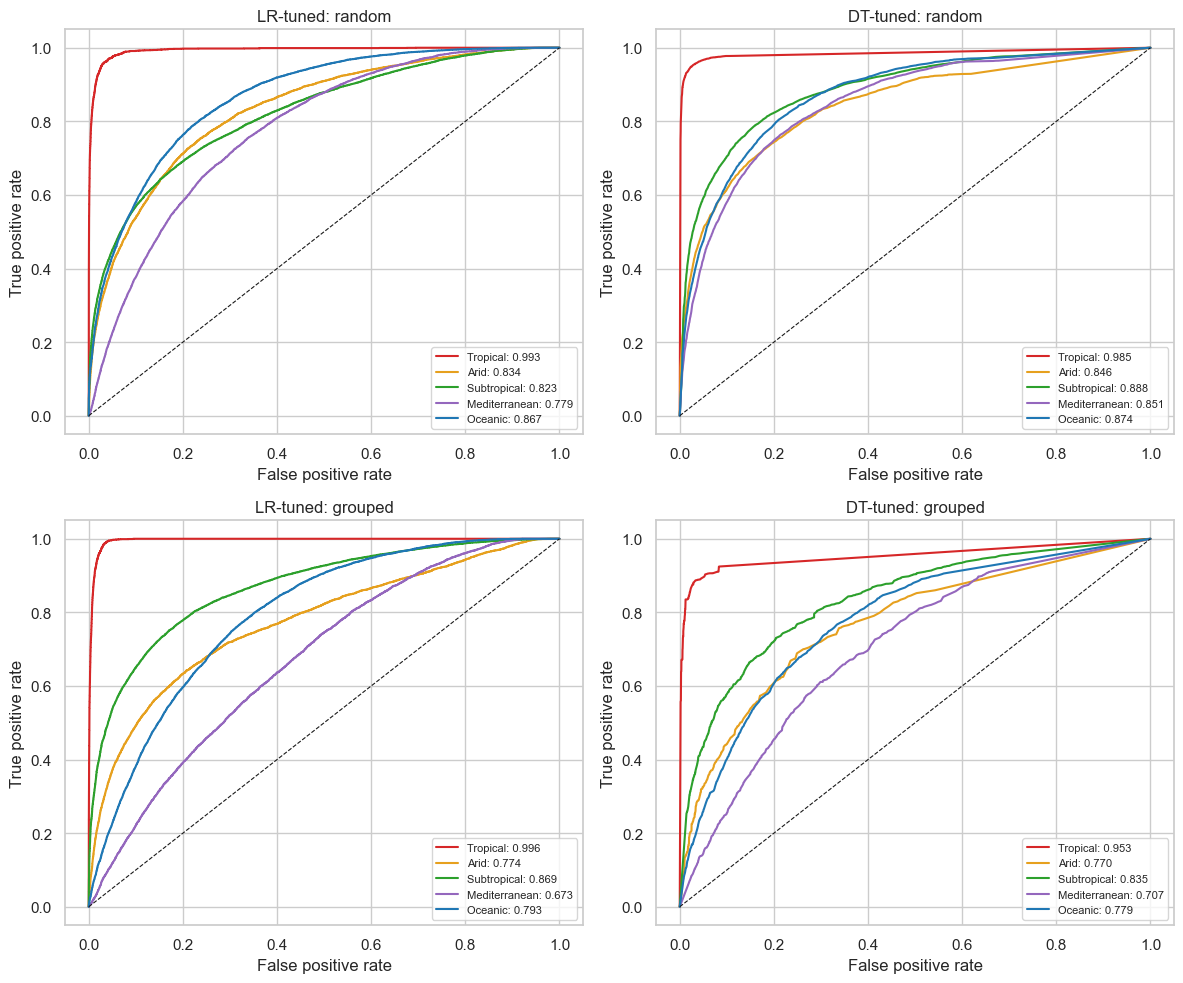

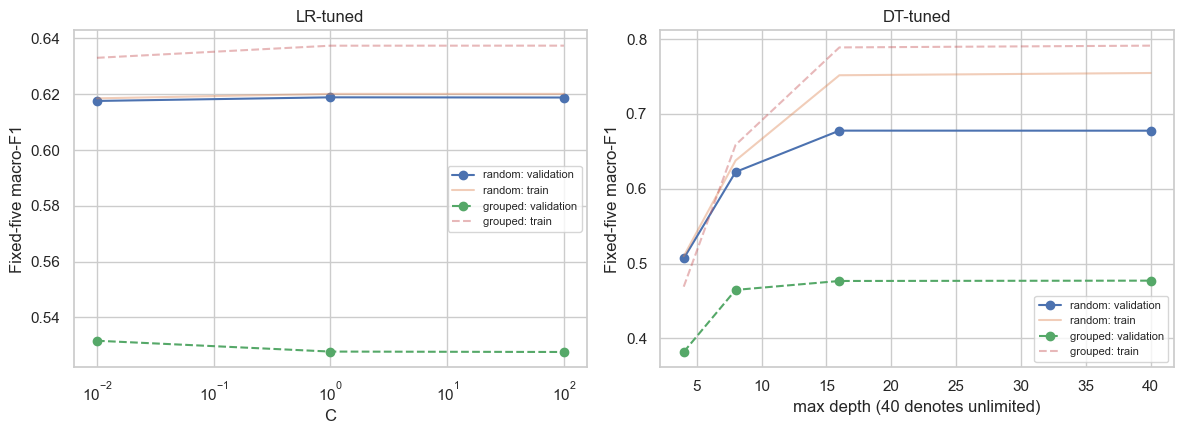

In [50]:
fig,axes=plt.subplots(2,2,figsize=(12,10));auc_rows=[]
for row,split in enumerate(["random","grouped"]):
    te=SPLITS[split][1]
    for col,kind in enumerate(["LR-tuned","DT-tuned"]):
        res=simple_holdout[(split,kind)]
        for j,z in enumerate(ZONE_ORDER):
            fp,tp,_=roc_curve(y[te]==z,res["proba"][:,j]);auc=roc_auc_score(y[te]==z,res["proba"][:,j])
            axes[row,col].plot(fp,tp,color=ZONE_COLORS[z],label=f"{z}: {auc:.3f}");auc_rows.append({"split":split,"model":kind,"zone":z,"AUC":auc})
        axes[row,col].plot([0,1],[0,1],'k--',lw=.8);axes[row,col].set(title=f"{kind}: {split}",xlabel="False positive rate",ylabel="True positive rate");axes[row,col].legend(fontsize=8)
plt.tight_layout();savefig("p5_roc_tuned");plt.show();export_table("p5_auc",pd.DataFrame(auc_rows))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,kind,param in zip(axes,["LR-tuned","DT-tuned"],["logisticregression__C","decisiontreeclassifier__max_depth"]):
    for split,style in [("random","-"),("grouped","--")]:
        cv=simple_holdout[(split,kind)]["meta"]["search"].copy();cv["axis"]=cv[f"param_{param}"].map(lambda x:40 if x is None else float(x))
        best=cv.loc[cv.groupby("axis")["mean_test_score"].idxmax()].sort_values("axis")
        ax.plot(best.axis,best.mean_test_score,style,marker='o',label=f"{split}: validation");ax.plot(best.axis,best.mean_train_score,style,alpha=.4,label=f"{split}: train")
    if kind=="LR-tuned":ax.set_xscale('log')
    ax.set(xlabel="C" if kind=="LR-tuned" else "max depth (40 denotes unlimited)",ylabel="Fixed-five macro-F1",title=kind);ax.legend(fontsize=8)
plt.tight_layout();savefig("p5_validation_curves");plt.show()

### 5.3 Discussion of model performance

The unrestricted tree can fit training observations closely, while its test confusion matrix exposes errors. Reducing depth and increasing minimum leaf size constrain this behaviour; validation chooses these constraints without consulting the outer test labels. Logistic regression provides a simpler reference, but a small training/test gap alone does not prove that all errors are bias. Climate labels are based on long-term statistics, and single days may genuinely be ambiguous. ROC curves measure ranking of one zone against the others; accuracy and F1 measure hard decisions, so their model orderings need not agree. Precision and recall also expose different costs of assigning too many or too few observations to a zone. The random holdout asks about new days of known stations; a grouped holdout asks about different stations in this network. Neither score is universally correct for every deployment setting. Differences between them are descriptive, not a causal decomposition of station information. The following experiments report nested station evaluation, fixed-label pooled scores and explicitly conditional uncertainty, and distinguish model improvement from the additional information supplied by a longer weather record.

## 6. Open-ended exploration: weather, climate and generalisation

### 6.1 Daily model comparison under three protocols
All daily candidates receive the same random and chronological test sets and three repeats of four station folds. The primary comparison is seed-42 **pooled five-class macro-F1**, not the mean of fold F1s. Tuned candidates repeat their inner search in every outer fold. Fixed candidates are fixed configurations, not optimally tuned algorithm families. HGB early stopping is disabled (100 iterations); MLP has a 500-epoch budget and row-based early stopping within training only. Its iteration count and warnings are exported. A time split is future days of known stations, not spatial extrapolation. These protocol gaps are descriptive and are not subtracted to identify causal contributions.

In [51]:
DAILY_MODELS=["LR","LR-tuned","DT-tuned","PolyLR","kNN","RF","MLP","HGB","HGB-tuned"]
cut=pd.Timestamp("2015-01-01")
time_tr=np.flatnonzero((df.Date<cut).values);time_te=np.flatnonzero((df.Date>=cut+pd.Timedelta(days=14)).values)
assert set(groups.iloc[time_te])<=set(groups.iloc[time_tr])
DAILY_RESULTS={}; OOF={}; FIT_AUDIT=[]; FOLD_RESULTS=[]

def grouped_predictions(kind,X,seed=42,tag="daily"):
    pred=np.empty(len(y),dtype=object);prob=np.zeros((len(y),len(ZONE_ORDER)))
    for fold,(tr,te) in enumerate(OUTER[seed]):
        res=cached(f"outer_{tag}_{kind}_s{seed}_f{fold}",lambda:run_fit(kind,X,tr,te,"grouped",seed),grid=GRIDS.get(kind,{}))
        pred[te]=res["pred"];prob[te]=res["proba"]
        FIT_AUDIT.append({"experiment":tag,"model":kind,"seed":seed,"fold":fold,"params":repr(res["meta"]["selected_params"]),"iterations":repr(res["meta"]["iterations"]),"warnings":repr(res["meta"]["warnings"]),"seconds":res["meta"]["fit_predict_seconds"]})
        FOLD_RESULTS.append({"experiment":tag,"model":kind,"seed":seed,"fold":fold,**res["scores"]})
    assert all(p in ZONE_ORDER for p in pred)
    return {"pred":pred,"proba":prob,"scores":score_predictions(np.arange(len(y)),pred,prob)}

for kind in DAILY_MODELS:
    for protocol,tr,te in [("random",rand_tr,rand_te),("time",time_tr,time_te)]:
        res=cached(f"daily_{protocol}_{kind}",lambda k=kind,a=tr,b=te,p=protocol:run_fit(k,X_all,a,b,p),grid=GRIDS.get(kind,{}))
        DAILY_RESULTS[(kind,protocol)]=res
        FIT_AUDIT.append({"experiment":protocol,"model":kind,"seed":42,"fold":-1,"params":repr(res["meta"]["selected_params"]),"iterations":repr(res["meta"]["iterations"]),"warnings":repr(res["meta"]["warnings"]),"seconds":res["meta"]["fit_predict_seconds"]})
    for seed in OUTER_SEEDS:OOF[(kind,seed)]=grouped_predictions(kind,X_all,seed)

model_rows=[]
for kind in DAILY_MODELS:
    repeated=[OOF[(kind,s)]["scores"]["macro_F1"] for s in OUTER_SEEDS]
    model_rows.append({"model":kind,"random":DAILY_RESULTS[(kind,"random")]["scores"]["macro_F1"],"time":DAILY_RESULTS[(kind,"time")]["scores"]["macro_F1"],"grouped_primary":repeated[0],"grouped_seed_mean":np.mean(repeated),"grouped_seed_min":min(repeated),"grouped_seed_max":max(repeated),**{k:v for k,v in OOF[(kind,42)]["scores"].items() if k!="macro_F1"}})
model_table=export_table("model_comparison",pd.DataFrame(model_rows).set_index("model"))
export_table("fit_audit",pd.DataFrame(FIT_AUDIT));export_table("fold_scores",pd.DataFrame(FOLD_RESULTS))
model_table.round(3)

cache hit: daily_random_LR (0.0s)


cache hit: daily_time_LR (0.0s)


cache hit: outer_daily_LR_s42_f0 (0.0s)


cache hit: outer_daily_LR_s42_f1 (0.0s)


cache hit: outer_daily_LR_s42_f2 (0.0s)


cache hit: outer_daily_LR_s42_f3 (0.0s)


... (117 outputs left out)

cache hit: outer_daily_HGB-tuned_s7_f1 (0.0s)


cache hit: outer_daily_HGB-tuned_s7_f2 (0.0s)


cache hit: outer_daily_HGB-tuned_s7_f3 (0.0s)


,random,time,grouped_primary,grouped_seed_mean,grouped_seed_min,grouped_seed_max,accuracy,weighted_F1,station_balanced_macro_F1,mean_station_accuracy,macro_AUC
model,,,,,,,,,,,
LR,0.615,0.599,0.556,0.549,0.538,0.556,0.543,0.538,0.556,0.540,0.823
LR-tuned,0.615,0.599,0.561,0.556,0.546,0.561,0.538,0.539,0.563,0.539,0.824
DT-tuned,0.691,0.659,0.577,0.569,0.553,0.577,0.564,0.564,0.577,0.562,0.812
PolyLR,0.751,0.729,0.654,0.642,0.621,0.654,0.639,0.637,0.654,0.637,0.878
kNN,0.768,0.735,0.625,0.608,0.589,0.625,0.614,0.613,0.627,0.613,0.862
RF,0.785,0.752,0.665,0.651,0.633,0.665,0.655,0.653,0.665,0.652,0.886
MLP,0.795,0.765,0.658,0.643,0.617,0.658,0.644,0.642,0.658,0.641,0.885
HGB,0.796,0.762,0.659,0.647,0.632,0.659,0.645,0.643,0.657,0.641,0.883
HGB-tuned,0.796,0.764,0.660,0.646,0.629,0.660,0.646,0.645,0.658,0.642,0.883


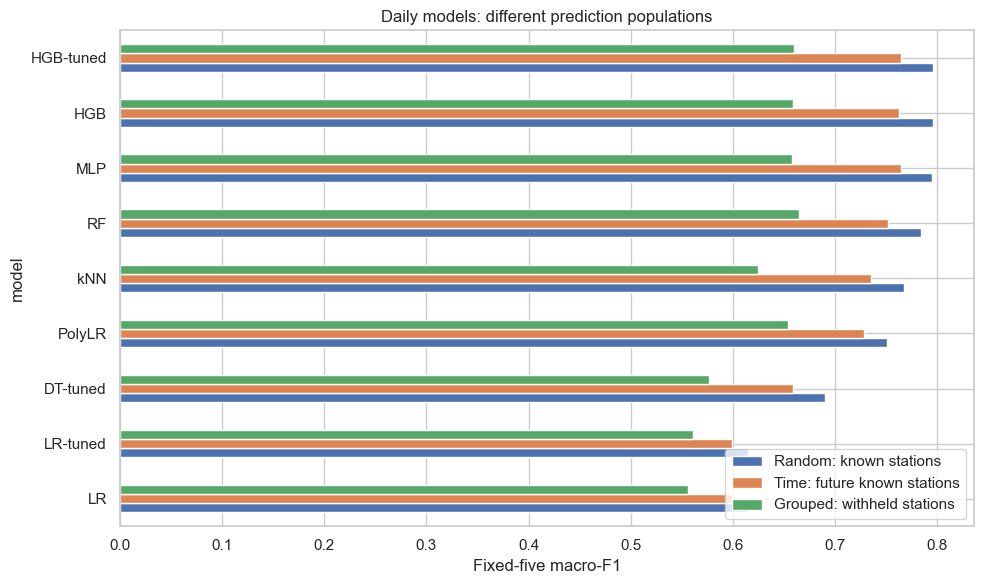

In [52]:
fig,ax=plt.subplots(figsize=(10,6))
model_table[["random","time","grouped_primary"]].plot.barh(ax=ax)
ax.set(xlabel="Fixed-five macro-F1",title="Daily models: different prediction populations");ax.legend(["Random: known stations","Time: future known stations","Grouped: withheld stations"])
plt.tight_layout();savefig("p6_model_comparison");plt.show()

### 6.2 Climate memory: fixed-window contrasts and nested window selection
Trailing calendar windows include today and past weather from the same station only. Rainfall is averaged after log1p, and wind-vector means describe net components rather than mean direction. A minimum of floor(N/3) observations is required for each feature (at least one); hence an N-day window does not imply N complete observations. Season sine/cosine are retained. Computing these row-local histories before station splitting is safe because stations are disjoint. Random row splits have strongly overlapping histories and do not estimate new-station performance.

The full 1/3/7/14/30/90/365-day curve is descriptive. An additional procedure selects N by inner three-fold station CV and is evaluated on untouched outer stations. Outer scores do not choose N. Three fixed-window repeats describe partition sensitivity; no claim of a uniquely optimal 14-day window is made.

In [53]:
BASE_DAILY=[c for c in FEATURE_SETS["core"] if not c.startswith("doy")]
WINDOWS=[1,3,7,14,30,90,365]
def rolling_features(N):
    t=F[BASE_DAILY].copy();t["_date"]=df.Date.values;t["_station"]=groups.values
    parts=[];counts=[]
    for _,g in t.sort_values(["_station","_date"]).groupby("_station"):
        r=g.set_index("_date")[BASE_DAILY].rolling(f"{N}D",min_periods=max(1,N//3)).mean();r.index=g.index;parts.append(r)
        c=g.set_index("_date")[BASE_DAILY].rolling(f"{N}D",min_periods=1).count();c.index=g.index;counts.append(c)
    out=pd.concat(parts).loc[F.index];out.columns=[f"{c}_mean{N}d" for c in BASE_DAILY]
    return pd.concat([out,F[["doy_sin","doy_cos"]]],axis=1),pd.concat(counts).loc[F.index]
X_WINDOWS={1:X_all};WINDOW_COUNTS={};window_diag=[]
age=(df.Date-df.Date.groupby(groups).transform("min")).dt.days
for N in WINDOWS[1:]:
    X_WINDOWS[N],WINDOW_COUNTS[N]=rolling_features(N)
    window_diag.append({"window":N,"rows_age_at_least_window":int((age>=N-1).sum()),"median_missing_fraction":X_WINDOWS[N].iloc[:,:18].isna().mean().median(),"max_missing_fraction":X_WINDOWS[N].iloc[:,:18].isna().mean().max(),"median_valid_days":WINDOW_COUNTS[N].median().median()})
export_table("window_diagnostics",pd.DataFrame(window_diag))
WINDOW_OOF={};window_rows=[]
for kind in ["LR","HGB"]:
    for N in WINDOWS:
        for seed in OUTER_SEEDS:
            r=OOF[(kind,seed)] if N==1 else grouped_predictions(kind,X_WINDOWS[N],seed,tag=f"window{N}")
            WINDOW_OOF[(kind,N,seed)]=r
            window_rows.append({"model":kind,"window":N,"seed":seed,**r["scores"]})
window_table=export_table("window_comparison",pd.DataFrame(window_rows))
window_table.pivot_table(index=["model","window"],values="macro_F1",aggfunc=["mean","min","max"]).round(3)

cache hit: outer_window3_LR_s42_f0 (0.0s)


cache hit: outer_window3_LR_s42_f1 (0.0s)


cache hit: outer_window3_LR_s42_f2 (0.0s)


cache hit: outer_window3_LR_s42_f3 (0.0s)


cache hit: outer_window3_LR_s0_f0 (0.0s)


cache hit: outer_window3_LR_s0_f1 (0.0s)


... (135 outputs left out)

cache hit: outer_window365_HGB_s7_f1 (0.0s)


cache hit: outer_window365_HGB_s7_f2 (0.0s)


cache hit: outer_window365_HGB_s7_f3 (0.0s)


mean      min      max
             macro_F1 macro_F1 macro_F1
model window                           
HGB   1         0.647    0.632    0.659
      3         0.685    0.662    0.702
      7         0.721    0.695    0.741
      14        0.736    0.708    0.758
      30        0.738    0.708    0.765
      90        0.729    0.698    0.752
      365       0.745    0.738    0.755
LR    1         0.549    0.538    0.556
      3         0.602    0.589    0.608
      7         0.655    0.641    0.663
      14        0.692    0.678    0.700
      30        0.711    0.693    0.722
      90        0.734    0.714    0.757
      365       0.667    0.652    0.676

In [54]:
NESTED_WINDOW={};nested_window_rows=[];window_choices=[]
def select_window_fold(kind,tr,te,seed):
    candidates=[]
    for N in WINDOWS:
        scores=[]
        for a,b in station_folds(tr,3,seed):
            model=model_factory(kind,seed).fit(X_WINDOWS[N].iloc[a],y[a])
            scores.append(macro5(y[b],model.predict(X_WINDOWS[N].iloc[b])))
        candidates.append({"window":N,"inner_mean_F1":np.mean(scores)})
    choice=sorted(candidates,key=lambda r:(-r["inner_mean_F1"],r["window"]))[0]["window"]
    res=run_fit(kind,X_WINDOWS[choice],tr,te,"grouped",seed)
    res["window"]=choice;res["candidates"]=candidates
    return res
for kind in ["LR","HGB"]:
    pred=np.empty(len(y),dtype=object);prob=np.zeros((len(y),5))
    for fold,(tr,te) in enumerate(OUTER[42]):
        res=cached(f"nested_window_{kind}_f{fold}",lambda:select_window_fold(kind,tr,te,42),windows=WINDOWS)
        pred[te]=res["pred"];prob[te]=res["proba"]
        window_choices.append({"model":kind,"fold":fold,"selected_window":res["window"],"outer_F1":res["scores"]["macro_F1"],"inner_results":repr(res["candidates"])})
    NESTED_WINDOW[kind]={"pred":pred,"proba":prob}
    nested_window_rows.append({"model":kind,**score_predictions(np.arange(len(y)),pred,prob)})
export_table("nested_window_choices",pd.DataFrame(window_choices))
export_table("nested_window_scores",pd.DataFrame(nested_window_rows)).round(3)

cache hit: nested_window_LR_f0 (0.0s)


cache hit: nested_window_LR_f1 (0.0s)


cache hit: nested_window_LR_f2 (0.0s)


cache hit: nested_window_LR_f3 (0.0s)


cache hit: nested_window_HGB_f0 (0.0s)


cache hit: nested_window_HGB_f1 (0.0s)


cache hit: nested_window_HGB_f2 (0.0s)


cache hit: nested_window_HGB_f3 (0.0s)


,model,macro_F1,accuracy,weighted_F1,station_balanced_macro_F1,mean_station_accuracy,macro_AUC
0,LR,0.745,0.757,0.754,0.732,0.743,0.923
1,HGB,0.758,0.752,0.752,0.751,0.745,0.925


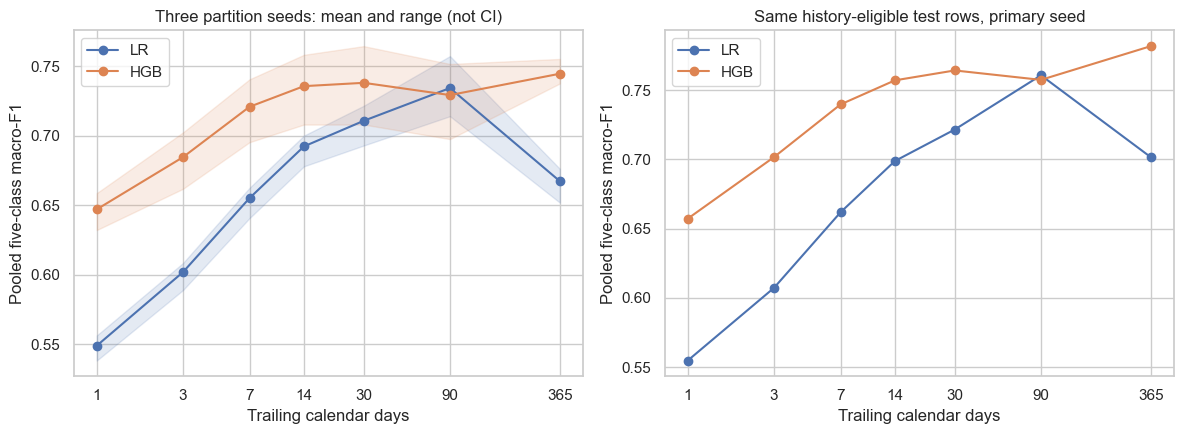

In [55]:
# Same target rows for every window. This checks evaluation-population differences;
# training stays unchanged, so it does not isolate the mechanism of a 365-day effect.
common=np.flatnonzero((age>=364).values)
assert set(y[common])==set(ZONE_ORDER)
common_rows=[]
for kind in ["LR","HGB"]:
    for N in WINDOWS:
        r=WINDOW_OOF[(kind,N,42)]
        common_rows.append({"model":kind,"window":N,"rows":len(common),**score_predictions(common,r["pred"][common],r["proba"][common])})
export_table("window_common_history",pd.DataFrame(common_rows))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for kind,color in [("LR","C0"),("HGB","C1")]:
    d=window_table[window_table.model==kind].groupby("window").macro_F1.agg(['mean','min','max']).reindex(WINDOWS)
    axes[0].plot(WINDOWS,d['mean'],marker='o',color=color,label=kind);axes[0].fill_between(WINDOWS,d['min'],d['max'],color=color,alpha=.15)
    d=pd.DataFrame(common_rows).query("model==@kind").set_index("window")
    axes[1].plot(WINDOWS,d.macro_F1,marker='o',color=color,label=kind)
for ax in axes:
    ax.set_xscale('log');ax.set_xticks(WINDOWS);ax.set_xticklabels(WINDOWS);ax.set(xlabel="Trailing calendar days",ylabel="Pooled five-class macro-F1");ax.legend()
axes[0].set_title("Three partition seeds: mean and range (not CI)")
axes[1].set_title("Same history-eligible test rows, primary seed")
plt.tight_layout();savefig("p6_climate_memory");plt.show()

### 6.3 Feature selection without outer-test feedback
For each outer fold, split training stations into class-covered disjoint sets A/B/C. Fit an importance model on A; rank features using B labels; choose k by training on A+B and validating on C. Refit on all outer training stations with that ranking and chosen k. None of the outer-test labels enter ranking or k selection. Fixed-k curves are descriptive comparisons; only the internally chosen k procedure is a selection-performance estimate. The small A/B/C sets make rankings noisy, so report selection frequency rather than a universal physical ranking.

cache hit: feature_selection_f0 (0.0s)


cache hit: feature_selection_f1 (0.0s)


cache hit: feature_selection_f2 (0.0s)


cache hit: feature_selection_f3 (0.0s)


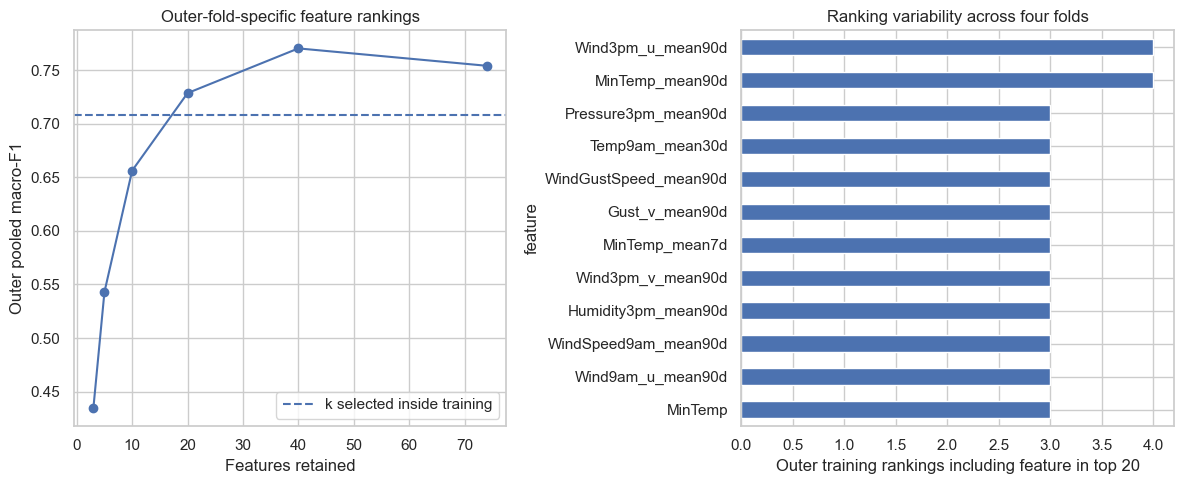

,k,macro_F1,accuracy,weighted_F1,station_balanced_macro_F1,mean_station_accuracy
0,3,0.434,0.465,0.464,0.431,0.460
1,5,0.543,0.555,0.552,0.550,0.559
2,10,0.656,0.666,0.664,0.664,0.667
3,20,0.729,0.731,0.733,0.728,0.727
4,40,0.771,0.771,0.772,0.767,0.765
5,74,0.754,0.767,0.767,0.746,0.758
6,selected,0.709,0.719,0.718,0.711,0.716


In [56]:
X_MULTI=pd.concat([X_all]+[X_WINDOWS[N].iloc[:,:18] for N in [7,30,90]],axis=1)
KS=[3,5,10,20,40,74]
SELECTION_OOF={k:np.empty(len(y),dtype=object) for k in KS+["selected"]};selection_details=[];rank_rows=[]
def selected_features_fold(tr,te,seed):
    parts=station_folds(tr,3,seed)
    A,B,C=[b for a,b in parts]
    assert not (set(groups.iloc[A])&set(groups.iloc[B]) or set(groups.iloc[A])&set(groups.iloc[C]) or set(groups.iloc[B])&set(groups.iloc[C]))
    m=model_factory("HGB",seed).fit(X_MULTI.iloc[A],y[A])
    # Sample at most 80 days per ranking station, equal station budget.
    rng=np.random.default_rng(seed)
    sub=np.concatenate([rng.choice(B[groups.iloc[B].values==st],min(80,sum(groups.iloc[B].values==st)),replace=False) for st in sorted(set(groups.iloc[B]))])
    pi=permutation_importance(m,X_MULTI.iloc[sub],y[sub],scoring=SCORER,n_repeats=3,random_state=seed,n_jobs=1)
    order=np.argsort(-pi.importances_mean,kind="stable");ranking=X_MULTI.columns[order].tolist()
    ab=np.concatenate([A,B]);scores={}
    for k in KS:
        cols=ranking[:k];m=model_factory("HGB",seed).fit(X_MULTI.iloc[ab][cols],y[ab])
        scores[k]=macro5(y[C],m.predict(X_MULTI.iloc[C][cols]))
    chosen=min(KS,key=lambda k:(-scores[k],k));predictions={}
    for k in KS:
        cols=ranking[:k];m=model_factory("HGB",seed).fit(X_MULTI.iloc[tr][cols],y[tr])
        predictions[k]=m.predict(X_MULTI.iloc[te][cols])
    return {"predictions":predictions,"chosen":chosen,"validation":scores,"ranking":ranking,"importance":pi.importances_mean[order],"A":sorted(set(groups.iloc[A])),"B":sorted(set(groups.iloc[B])),"C":sorted(set(groups.iloc[C]))}
for fold,(tr,te) in enumerate(OUTER[42]):
    r=cached(f"feature_selection_f{fold}",lambda:selected_features_fold(tr,te,42),ks=KS)
    for k in KS:SELECTION_OOF[k][te]=r["predictions"][k]
    SELECTION_OOF["selected"][te]=r["predictions"][r["chosen"]]
    selection_details.append({"fold":fold,"selected_k":r["chosen"],"validation":repr(r["validation"]),"A":";".join(r["A"]),"B":";".join(r["B"]),"C":";".join(r["C"])})
    rank_rows.extend({"fold":fold,"rank":j+1,"feature":f,"importance":float(r["importance"][j])} for j,f in enumerate(r["ranking"]))
selection_scores=export_table("feature_selection_scores",pd.DataFrame([{"k":k,**score_predictions(np.arange(len(y)),p)} for k,p in SELECTION_OOF.items()]))
export_table("feature_selection_details",pd.DataFrame(selection_details));export_table("feature_rankings",pd.DataFrame(rank_rows))
fig,axes=plt.subplots(1,2,figsize=(12,5))
d=selection_scores.iloc[:len(KS)];axes[0].plot(KS,d.macro_F1,marker='o');axes[0].axhline(selection_scores.iloc[-1].macro_F1,ls='--',label='k selected inside training');axes[0].set(xlabel="Features retained",ylabel="Outer pooled macro-F1",title="Outer-fold-specific feature rankings");axes[0].legend()
ranks=pd.DataFrame(rank_rows);freq=ranks[ranks['rank']<=20].feature.value_counts().head(12).sort_values();freq.plot.barh(ax=axes[1]);axes[1].set(xlabel="Outer training rankings including feature in top 20",title="Ranking variability across four folds")
plt.tight_layout();savefig("p6_importance_selection");plt.show()
selection_scores.round(3)

### 6.4 Conditional uncertainty and station-level errors
Bootstrap whole stations within each of the five climate groups, preserving their days. Paired resamples use identical station multiplicities for both models. These 95% percentile intervals are **conditional on the primary OOF predictions and this station network**: they do not include retraining, model-selection variation or unobserved spatial dependence. No independent-fold t-test or equivalence claim is made. Station-balanced metrics give each observed station equal total weight before calculating the five-class score.

In [57]:
BOOT_MODELS={k:OOF[(k,42)]["pred"] for k in DAILY_MODELS}
BOOT_MODELS.update({"HGB-14d":WINDOW_OOF[("HGB",14,42)]["pred"],"LR-14d":WINDOW_OOF[("LR",14,42)]["pred"],"HGB-window-selected":NESTED_WINDOW["HGB"]["pred"],"HGB-features-selected":SELECTION_OOF["selected"]})
st_names=np.array(sorted(set(groups)));st_zones=station_zone.loc[st_names].values


def f1_from_cm(cm):
    diag=np.diagonal(cm,axis1=-2,axis2=-1);den=cm.sum(-1)+cm.sum(-2)
    return np.divide(2*diag,den,out=np.zeros_like(diag,dtype=float),where=den>0).mean(-1)
CM_BY_MODEL={k:np.stack([confusion_matrix(y[groups.values==s],p[groups.values==s],labels=ZONE_ORDER) for s in st_names]) for k,p in BOOT_MODELS.items()}
rng=np.random.default_rng(20261117);weights=np.zeros((2000,len(st_names)),dtype=int)
for z in ZONE_ORDER:
    ids=np.flatnonzero(st_zones==z)
    draws=rng.choice(ids,(len(weights),len(ids)),replace=True)
    for b,draw in enumerate(draws):np.add.at(weights[b],draw,1)
BOOT={k:f1_from_cm(np.einsum('bs,sij->bij',weights,cm)) for k,cm in CM_BY_MODEL.items()}
ci_rows=[]
for k,p in BOOT_MODELS.items():
    lo,hi=np.quantile(BOOT[k],[.025,.975]);ci_rows.append({"model":k,"pooled_F1":macro5(y,p),"conditional_low":lo,"conditional_high":hi})
export_table("conditional_intervals",pd.DataFrame(ci_rows))
pairs=[("HGB","LR"),("HGB","RF"),("HGB","MLP"),("DT-tuned","LR-tuned"),("HGB-14d","HGB"),("LR-14d","LR"),("HGB-window-selected","HGB")]
paired_rows=[]
for a,b in pairs:
    lo,hi=np.quantile(BOOT[a]-BOOT[b],[.025,.975]);paired_rows.append({"comparison":a+" minus "+b,"difference":macro5(y,BOOT_MODELS[a])-macro5(y,BOOT_MODELS[b]),"conditional_low":lo,"conditional_high":hi})
export_table("paired_intervals",pd.DataFrame(paired_rows)).round(3)

,comparison,difference,conditional_low,conditional_high
0,HGB minus LR,0.102,0.075,0.126
1,HGB minus RF,-0.006,-0.021,0.006
2,HGB minus MLP,0.001,-0.012,0.013
3,DT-tuned minus LR-tuned,0.015,-0.010,0.042
4,HGB-14d minus HGB,0.100,0.071,0.128
5,LR-14d minus LR,0.144,0.113,0.174
6,HGB-window-selected minus HGB,0.100,0.066,0.131


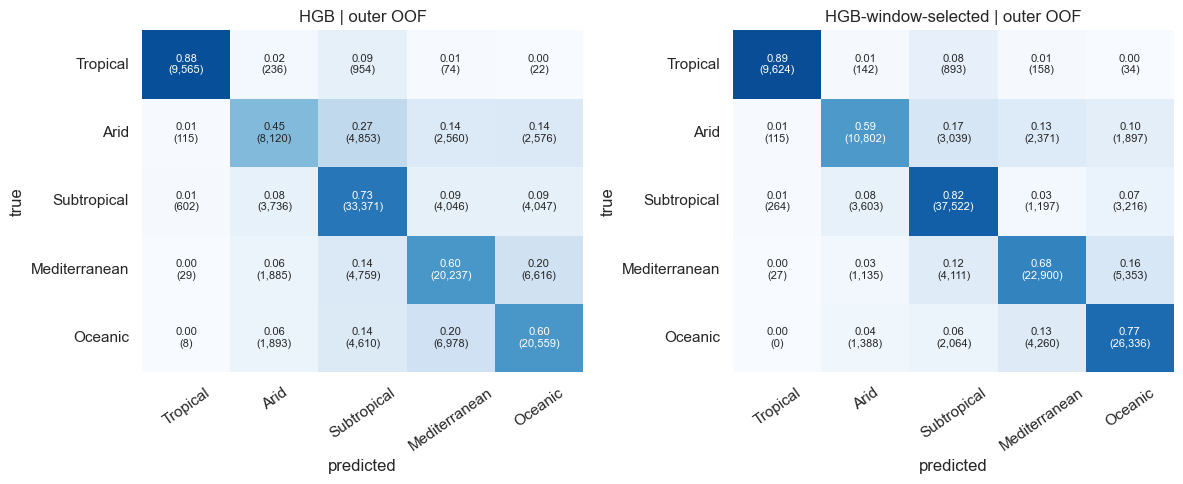

In [58]:
station_rows=[];class_rows=[]
for kind,pred in BOOT_MODELS.items():
    pc=classification_report(y,pred,labels=ZONE_ORDER,output_dict=True,zero_division=0)
    class_rows.extend({"model":kind,"zone":z,**pc[z]} for z in ZONE_ORDER)
    for s in st_names:
        mask=groups.values==s;station_rows.append({"model":kind,"station":s,"zone":station_zone[s],"days":int(mask.sum()),"accuracy":accuracy_score(y[mask],pred[mask])})
export_table("station_errors",pd.DataFrame(station_rows));export_table("outer_per_class",pd.DataFrame(class_rows))
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,kind in zip(axes,["HGB","HGB-window-selected"]):plot_cm(ax,y,BOOT_MODELS[kind],kind+" | outer OOF")
plt.tight_layout();savefig("p6_final_confusion");plt.show()

### 6.5 Stress tests: missingness, spatial separation and label boundary
These checks keep model/feature policies fixed. They are sensitivities on the same network, not new external evidence. A 100-km training exclusion changes training size and station composition, so it does not isolate spatial dependence. The annotation sensitivity uses alternative neighbouring raster pixels and does not replace validation against an independent climate map.

In [59]:
# Indicator policies are compared, not selected from the resulting outer scores.
POLICY={"core":X_all,"full":F[FEATURE_SETS['full']],"full+flags":pd.concat([F[FEATURE_SETS['full']],F[FEATURE_SETS['full']].isna().astype(float).add_suffix('_missing')],axis=1)}
policy_rows=[]
for name,X in POLICY.items():
    res=OOF[("HGB",42)] if name=="core" else grouped_predictions("HGB",X,42,tag="policy_"+name)
    policy_rows.append({"policy":name,**res['scores']})
export_table("missingness_policies",pd.DataFrame(policy_rows))

def haversine_matrix(a,b):
    la1,lo1=np.deg2rad(a[:,0])[:,None],np.deg2rad(a[:,1])[:,None]
    la2,lo2=np.deg2rad(b[:,0])[None,:],np.deg2rad(b[:,1])[None,:]
    h=np.sin((la2-la1)/2)**2+np.cos(la1)*np.cos(la2)*np.sin((lo2-lo1)/2)**2
    return 6371*2*np.arcsin(np.sqrt(np.clip(h,0,1)))
coordinates=zones.set_index('Location')[['lat','lon']]
spatial_rows=[];spatial_pred=np.empty(len(y),dtype=object);spatial_pred[:]=None
for fold,(tr,te) in enumerate(OUTER[42]):
    train_st=sorted(set(groups.iloc[tr]));test_st=sorted(set(groups.iloc[te]))
    distances=haversine_matrix(coordinates.loc[train_st].values,coordinates.loc[test_st].values)
    kept=np.array(train_st)[distances.min(1)>=100]
    a=tr[groups.iloc[tr].isin(kept).values]
    supported=set(y[a])==set(ZONE_ORDER)
    row={"fold":fold,"original_train_stations":len(train_st),"buffered_train_stations":len(kept),"supported":supported}
    if supported:
        res=cached(f"spatial_buffer100_f{fold}",lambda:run_fit("HGB",X_all,a,te))
        spatial_pred[te]=res['pred'];row.update(res['scores'])
    spatial_rows.append(row)
export_table("spatial_buffer_folds",pd.DataFrame(spatial_rows))
valid=np.flatnonzero(pd.notna(spatial_pred))
export_table("spatial_buffer_summary",pd.DataFrame([{"test_rows":len(valid),"complete_coverage":len(valid)==len(y),**score_predictions(valid,spatial_pred[valid])}]))

boundary=zones[zones.zone_boundary & zones.Zone.notna()].Location.tolist()
label_rows=[]
for mode in ['exclude_boundary','neighbour_label']:
    pred=np.empty(len(y),dtype=object);pred[:]=None;alt_y=y.copy()
    if mode=='neighbour_label':
        for station in boundary:
            z=zones.set_index('Location').loc[station];alternatives=sorted({KOPPEN_TO_ZONE[c] for c in z.neighbour_codes.split(';') if c in KOPPEN_TO_ZONE and KOPPEN_TO_ZONE[c]!=z.Zone})
            if alternatives:alt_y[groups.values==station]=alternatives[0]
    for fold,(tr,te) in enumerate(OUTER[42]):
        if mode=='exclude_boundary':
            tr=tr[~groups.iloc[tr].isin(boundary).values];te=te[~groups.iloc[te].isin(boundary).values]
        def fit_alt():
            m=model_factory('HGB').fit(X_all.iloc[tr],alt_y[tr]);return m.predict(X_all.iloc[te])
        pred[te]=cached(f"labels_{mode}_f{fold}",fit_alt,stations=boundary)
    valid=np.flatnonzero(pd.notna(pred))
    label_rows.append({"mode":mode,"boundary_stations":';'.join(boundary),"rows":len(valid),"macro_F1":macro5(alt_y[valid],pred[valid]),"original_label_F1_same_rows":macro5(y[valid],OOF[('HGB',42)]['pred'][valid])})
export_table('label_sensitivity',pd.DataFrame(label_rows)).round(3)

cache hit: outer_policy_full_HGB_s42_f0 (0.0s)


cache hit: outer_policy_full_HGB_s42_f1 (0.0s)


cache hit: outer_policy_full_HGB_s42_f2 (0.0s)


cache hit: outer_policy_full_HGB_s42_f3 (0.0s)


cache hit: outer_policy_full+flags_HGB_s42_f0 (0.0s)


cache hit: outer_policy_full+flags_HGB_s42_f1 (0.0s)


... (11 outputs left out)

cache hit: labels_neighbour_label_f1 (0.0s)


cache hit: labels_neighbour_label_f2 (0.0s)


cache hit: labels_neighbour_label_f3 (0.0s)


,mode,boundary_stations,rows,macro_F1,original_label_F1_same_rows
0,exclude_boundary,Wollongong,139411,0.654,0.656
1,neighbour_label,Wollongong,142451,0.640,0.659


### 6.6 Reproducibility and interpretation
All results belong to this fixed station network and one manually matched raster annotation. More stations, an independent map and spatially independent sampling would address limits that rerunning cannot remove. Paired conditional intervals do not correct prior exploration or prove model equivalence. Selection-performance results describe the complete internal selection procedure; fixed-window and fixed-k curves describe those configurations without claiming an independently verified optimum. A common-history subset controls which rows are evaluated, not all mechanisms behind window effects.

Raw observations are unchanged. The executable-cell hash, annotation hashes, Python and installed distributions identify the run. Predictions, fold membership, timing, convergence diagnostics and machine-readable scores are exported. Old caches are not used by this revision.

In [60]:
export_table('fit_audit',pd.DataFrame(FIT_AUDIT));export_table('fold_scores',pd.DataFrame(FOLD_RESULTS))
export_table('p4_metrics',p4_table);export_table('tsne_diagnostics',quant);export_table('clustering_sweep',sweep);export_table('station_clustering',st_sweep)
export_table('preprocessing_probe',pd.DataFrame(rows) if isinstance(rows,list) and rows and 'features' in rows[0] else sens)
export_table('cache_events',pd.DataFrame(CACHE_EVENTS))
arrays={'y':np.array(y,dtype=str),'station':groups.to_numpy(dtype=str),'date':df.Date.astype(str).to_numpy(dtype=str)}
for k,p in BOOT_MODELS.items():arrays[k]=np.array(p,dtype=str)
for (kind,seed),r in OOF.items():arrays[f'daily_{kind}_s{seed}']=np.array(r['pred'],dtype=str)
for (kind,N,seed),r in WINDOW_OOF.items():arrays[f'window_{kind}_{N}_s{seed}']=np.array(r['pred'],dtype=str)
pred_path = RESULT_DIR / 'predictions.npz'
pred_tmp = RESULT_DIR / 'predictions.base.tmp.npz'
if pred_tmp.exists(): pred_tmp.unlink()
np.savez_compressed(pred_tmp, **arrays)
pred_tmp.replace(pred_path)
manifest={'run_id':RUN_ID,'code_sha256':code_digest,'rows':len(y),'stations':len(st_names),'outer_seeds':OUTER_SEEDS,'outer_folds':4,'metric':'pooled fixed-five macro-F1','cache_hits':sum(e['hit'] for e in CACHE_EVENTS),'cache_misses':sum(not e['hit'] for e in CACHE_EVENTS),'completed_utc':pd.Timestamp.now(tz='UTC').isoformat()}
(RESULT_DIR/'run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print(json.dumps(manifest,indent=2))

{
  "run_id": "f67d019ce7acf9e9",
  "code_sha256": "179d4d0f51b196bbde187de730ac834c36b0d89a21d69f30081fd186b2cb2b83",
  "rows": 142451,
  "stations": 48,
  "outer_seeds": [
    42,
    0,
    7
  ],
  "outer_folds": 4,
  "metric": "pooled fixed-five macro-F1",
  "cache_hits": 335,
  "cache_misses": 0,
  "completed_utc": "2026-11-20T08:28:31.819614+00:00"
}


## 7. Seasonal climate signatures: from weather snapshots to annual patterns

The daily experiments are retained as the baseline and motivation. A single day is a first-impression test: it can
contain a climate signal, but it is also strongly affected by synoptic weather. The main open-ended question is whether
four seasonal observations recover the target more faithfully. We therefore construct one **station-year** observation
from four 21-day windows centred on the March equinox, June solstice, September equinox and December solstice. The
windows use dates available in that calendar year, and require at least seven observed days in each window. A station
year is labelled by its station's fixed climate group; the year is never used as a predictor.

This is a seasonal-weather signature, not a new climate ground truth. Köppen labels describe long-term climate normals,
whereas the supplied data cover roughly a decade. The purpose is to test how much of the supplied external label can be
recovered from increasingly complete weather information. Every station-year model is evaluated using the same withheld
station folds as the daily study, so years from one station never appear on both sides of an outer fold.

In [61]:
SEASON_SPECS = {
    "mar_equinox": (3, 20),
    "jun_solstice": (6, 21),
    "sep_equinox": (9, 22),
    "dec_solstice": (12, 21),
}
SEASON_LABELS = {
    "mar_equinox": "March equinox (autumn)",
    "jun_solstice": "June solstice (winter)",
    "sep_equinox": "September equinox (spring)",
    "dec_solstice": "December solstice (summer)",
}
SEASON_HALF_WINDOW = 10
SEASON_MIN_DAYS = 7
SEASON_BASE = [c for c in FEATURE_SETS["core"] if c not in ["doy_sin", "doy_cos"]]
SEASON_STATS = [c for c in SEASON_BASE if c not in ["Rainfall_log1p"]]

def build_seasonal_signatures():
    # Return station-year rows and diagnostics from four fixed seasonal windows.
    records = []
    diagnostics = []
    local = F.copy()
    local["station"] = groups.to_numpy()
    local["date"] = df["Date"].to_numpy()
    local["year"] = df["Date"].dt.year.to_numpy()
    local["rain_raw"] = df["Rainfall"].to_numpy()
    local["temp_range"] = df["MaxTemp"].to_numpy() - df["MinTemp"].to_numpy()

    for station, sg in local.groupby("station", sort=True):
        zone = station_zone.loc[station]
        years = sorted(sg["year"].unique())
        for year in years:
            row = {"station": station, "year": int(year), "Zone": zone}
            all_ok = True
            diag = {"station": station, "year": int(year), "Zone": zone}
            for key, (month, day) in SEASON_SPECS.items():
                centre = pd.Timestamp(year=int(year), month=month, day=day)
                lo, hi = centre - pd.Timedelta(days=SEASON_HALF_WINDOW), centre + pd.Timedelta(days=SEASON_HALF_WINDOW)
                w = sg[(sg["date"] >= lo) & (sg["date"] <= hi)]
                valid = int(w[SEASON_BASE].notna().any(axis=1).sum())
                diag[f"{key}_rows"] = int(len(w))
                diag[f"{key}_valid_days"] = valid
                all_ok &= valid >= SEASON_MIN_DAYS
                for col in SEASON_STATS:
                    row[f"{key}_{col}_mean"] = w[col].mean()
                    row[f"{key}_{col}_std"] = w[col].std(ddof=0)
                row[f"{key}_Rainfall_log1p_mean"] = w["Rainfall_log1p"].mean()
                row[f"{key}_rain_day_fraction"] = (w["rain_raw"] > 1).mean()
                row[f"{key}_temp_range_mean"] = w["temp_range"].mean()
                row[f"{key}_temp_range_std"] = w["temp_range"].std(ddof=0)
            diag["complete_signature"] = bool(all_ok)
            diagnostics.append(diag)
            if all_ok:
                records.append(row)
    out = pd.DataFrame(records).sort_values(["station", "year"]).reset_index(drop=True)
    diag = pd.DataFrame(diagnostics).sort_values(["station", "year"]).reset_index(drop=True)
    assert len(out) > 300 and out.station.nunique() == 48
    assert out.groupby("station").Zone.nunique().eq(1).all()
    return out, diag

seasonal, seasonal_diag = build_seasonal_signatures()
SEASON_META = ["station", "year", "Zone"]
SEASON_FEATURES = [c for c in seasonal.columns if c not in SEASON_META]
season_y = seasonal["Zone"].to_numpy()
season_groups = seasonal["station"].copy()
X_season = seasonal[SEASON_FEATURES]
export_table("seasonal_feature_diagnostics", seasonal_diag)
print("station-year signatures:", seasonal.shape, "| features:", len(SEASON_FEATURES),
      "| stations:", seasonal.station.nunique(), "| complete coverage:", f"{len(seasonal) / len(seasonal_diag):.1%}")
seasonal_diag.groupby("Zone").complete_signature.mean().reindex(ZONE_ORDER)

station-year signatures: (328, 155) | features: 152 | stations: 48 | complete coverage: 73.9%


Zone
Tropical         0.714286
Arid             0.750000
Subtropical      0.746479
Mediterranean    0.747573
Oceanic          0.722222
Name: complete_signature, dtype: float64

### 7.1 What the four windows contain

The window summaries retain both level and variability. Means describe the seasonal state; standard deviations and rainy-
day fractions retain weather variability that a single mean would erase. We report coverage before fitting because a
station-year with too few observations is not equivalent to a complete seasonal signature. The feature table contains no
coordinates, station identifiers or labels. Imputation and scaling are learned inside each training-fold pipeline.

In [62]:
coverage = seasonal_diag.assign(
    complete=seasonal_diag.complete_signature.astype(int),
    min_valid=seasonal_diag[[f"{k}_valid_days" for k in SEASON_SPECS]].min(axis=1),
)
coverage_table = coverage.groupby("Zone").agg(
    station_years=("complete", "sum"),
    candidate_years=("complete", "size"),
    median_min_valid=("min_valid", "median"),
).reindex(ZONE_ORDER)
coverage_table["coverage"] = coverage_table.station_years / coverage_table.candidate_years
export_table("seasonal_coverage", coverage_table)
coverage_table.round(3)

,station_years,candidate_years,median_min_valid,coverage
Zone,,,,
Tropical,25,35,21.0,0.714
Arid,42,56,21.0,0.750
Subtropical,106,142,21.0,0.746
Mediterranean,77,103,21.0,0.748
Oceanic,78,108,21.0,0.722


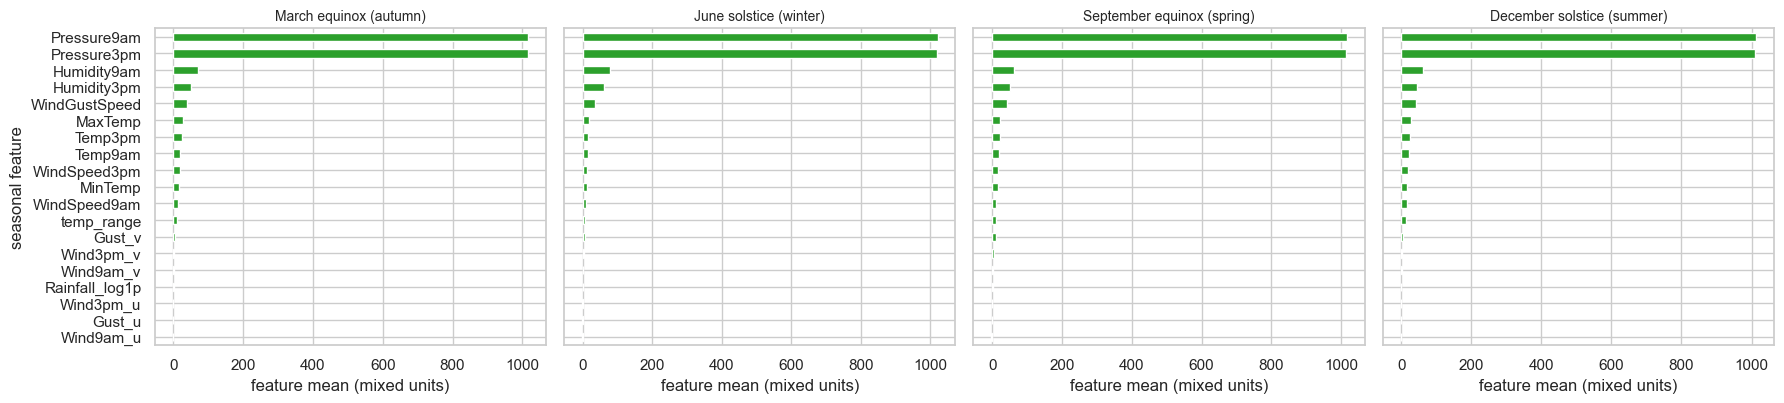

In [63]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
for ax, (key, label) in zip(axes, SEASON_LABELS.items()):
    vals = seasonal[[c for c in SEASON_FEATURES if c.startswith(key + "_") and c.endswith("_mean")]].mean()
    vals.index = [v.replace(key + "_", "").replace("_mean", "") for v in vals.index]
    vals.sort_values().plot.barh(ax=ax, color=ZONE_COLORS["Subtropical"])
    ax.set_title(label, fontsize=10); ax.set_xlabel("feature mean (mixed units)")
axes[0].set_ylabel("seasonal feature")
plt.tight_layout(); savefig("p7_seasonal_feature_means"); plt.show()

### 7.2 Seasonal t-SNE

We embed the station-year signatures after median imputation and scaling. This visualization is descriptive: the same
station contributes multiple years, so it is not a held-out prediction estimate. The relevant comparison is whether the
seasonal signature shows more coherent zone structure than the single-day embedding, not whether t-SNE distances are
physical distances.

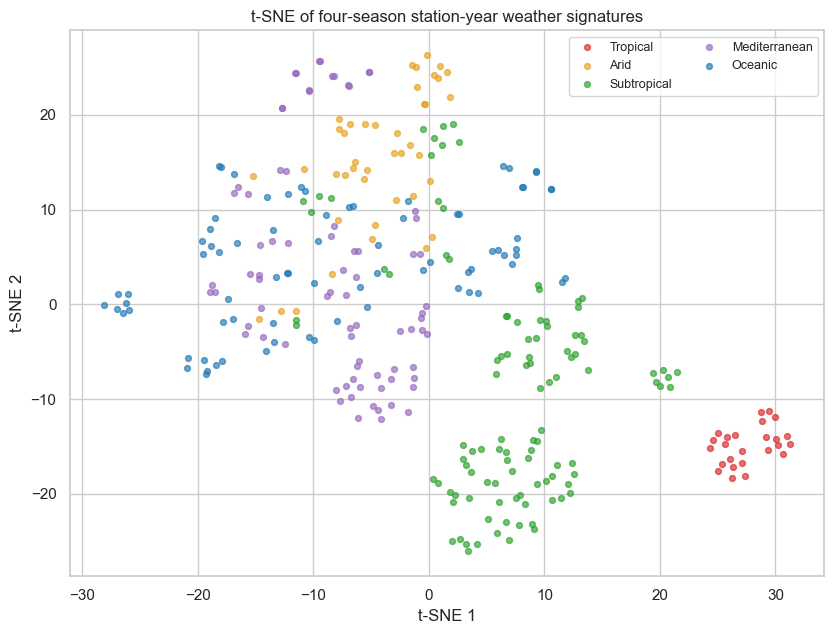

,embedding,rows,perplexity,silhouette_zone_original,silhouette_zone_tsne
0,seasonal station-year t-SNE,328,27,0.072,0.112


In [64]:
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score
season_matrix = build_preprocessor().fit_transform(X_season)
season_matrix = np.asarray(season_matrix)
season_tsne = TSNE(n_components=2, perplexity=min(30, max(5, len(seasonal)//12)), init="pca",
                   learning_rate="auto", random_state=RANDOM_STATE).fit_transform(season_matrix)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for zone in ZONE_ORDER:
    mask = season_y == zone
    ax.scatter(season_tsne[mask, 0], season_tsne[mask, 1], s=18, alpha=.65,
               color=ZONE_COLORS[zone], label=zone)
ax.set(title="t-SNE of four-season station-year weather signatures", xlabel="t-SNE 1", ylabel="t-SNE 2")
ax.legend(ncol=2, fontsize=9)
plt.tight_layout(); savefig("p7_seasonal_tsne"); plt.show()
season_tsne_diag = pd.DataFrame([{
    "embedding": "seasonal station-year t-SNE",
    "rows": len(seasonal),
    "perplexity": min(30, max(5, len(seasonal)//12)),
    "silhouette_zone_original": silhouette_score(season_matrix, season_y),
    "silhouette_zone_tsne": silhouette_score(season_tsne, season_y),
}])
export_table("seasonal_tsne_diagnostics", season_tsne_diag)
season_tsne_diag.round(3)

### 7.3 Clustering: weather types versus seasonal climate signatures

The daily clustering section already shows that one-day clusters are mainly weather types. We now repeat a smaller,
transparent comparison on the four-season signatures. K-means and Ward are fitted without labels; silhouette,
Davies--Bouldin and ARI with the external zone labels are reported for $k=2,\ldots,7$. The labels are used only for
external evaluation, never to fit or select the clusters.

In [65]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score
season_cluster_rows = []
for algorithm in ["K-means", "Ward"]:
    for k in range(2, 8):
        if algorithm == "K-means":
            lab = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(season_matrix)
        else:
            lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(season_matrix)
        season_cluster_rows.append({
            "algorithm": algorithm, "k": k,
            "silhouette": silhouette_score(season_matrix, lab),
            "Davies-Bouldin": davies_bouldin_score(season_matrix, lab),
            "ARI zone": adjusted_rand_score(season_y, lab),
            "cluster_count": len(np.unique(lab)),
        })
season_cluster_table = export_table("seasonal_clustering_sweep", pd.DataFrame(season_cluster_rows))
season_best = season_cluster_table.sort_values(["ARI zone", "silhouette"], ascending=[False, False]).iloc[0]
season_cluster_table.round(3)

,algorithm,k,silhouette,Davies-Bouldin,ARI zone,cluster_count
0,K-means,2,0.254,1.654,0.087,2
1,K-means,3,0.130,2.229,0.090,3
2,K-means,4,0.130,2.114,0.242,4
3,K-means,5,0.130,2.092,0.256,5
4,K-means,6,0.112,2.207,0.302,6
5,K-means,7,0.121,2.205,0.314,7
6,Ward,2,0.290,1.256,0.097,2
7,Ward,3,0.115,2.298,0.104,3
8,Ward,4,0.115,2.174,0.204,4
9,Ward,5,0.112,2.170,0.280,5


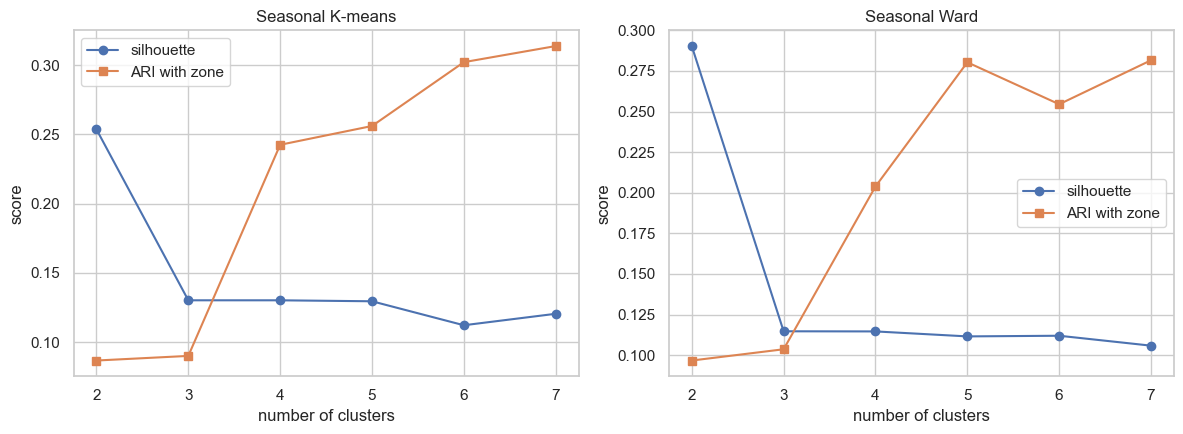

,best_by_ARI_algorithm,best_by_ARI_k,best_by_ARI,daily_reference_station_profile_ARI
0,K-means,7,0.313717,0.344643


In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for algorithm, ax in zip(["K-means", "Ward"], axes):
    s = season_cluster_table[season_cluster_table.algorithm == algorithm]
    ax.plot(s.k, s.silhouette, marker="o", label="silhouette")
    ax.plot(s.k, s["ARI zone"], marker="s", label="ARI with zone")
    ax.set(title=f"Seasonal {algorithm}", xlabel="number of clusters", ylabel="score")
    ax.legend()
plt.tight_layout(); savefig("p7_seasonal_clustering"); plt.show()
export_table("seasonal_clustering_summary", pd.DataFrame([{
    "best_by_ARI_algorithm": season_best.algorithm,
    "best_by_ARI_k": int(season_best.k),
    "best_by_ARI": season_best["ARI zone"],
    # ``station`` is a loop variable used in the feature-construction cells;
    # the earlier station-profile clustering sweep is stored as ``st_sweep``.
    "daily_reference_station_profile_ARI": st_sweep.query("algorithm=='Ward' and k==5")['ARI zone'].iloc[0],
}]))

### 7.4 Main prediction experiment: station-year signatures

The main prediction unit is a station-year, while the outer split remains a station split. This prevents years from the
same station appearing in both training and test. We compare a linear model, a simple tree, random forest and histogram
gradient boosting. The tuned tree and HGB perform their searches inside the outer training stations only. Scores are
pooled over station-year predictions; station-balanced scores are reported separately because years do not create new
stations.

In [67]:
def seasonal_outer(seed):
    result = []
    for fold, (daily_tr, daily_te) in enumerate(OUTER[seed]):
        tr_st = set(groups.iloc[daily_tr]); te_st = set(groups.iloc[daily_te])
        tr = np.flatnonzero(season_groups.isin(tr_st).to_numpy())
        te = np.flatnonzero(season_groups.isin(te_st).to_numpy())
        assert not set(season_groups.iloc[tr]) & set(season_groups.iloc[te])
        assert set(season_y[tr]) == set(ZONE_ORDER) == set(season_y[te])
        result.append((tr, te))
    return result

def seasonal_inner(indices, seed):
    indices = np.asarray(indices)
    station_table = seasonal.iloc[indices][["station", "Zone"]].drop_duplicates().sort_values("station")
    # GridSearchCV receives X_season.iloc[indices], so its cv indices must be
    # relative to that training subset. Keep the absolute arrays for the
    # station-disjointness and class-coverage checks, then map them back.
    position = {int(idx): pos for pos, idx in enumerate(indices)}
    out = []
    for a, b in StratifiedKFold(3, shuffle=True, random_state=seed).split(station_table.station, station_table.Zone):
        a_st = set(station_table.iloc[a].station); b_st = set(station_table.iloc[b].station)
        ia_abs = indices[season_groups.iloc[indices].isin(a_st).to_numpy()]
        ib_abs = indices[season_groups.iloc[indices].isin(b_st).to_numpy()]
        assert set(season_y[ia_abs]) == set(ZONE_ORDER) == set(season_y[ib_abs])
        out.append((np.asarray([position[int(i)] for i in ia_abs], dtype=int),
                    np.asarray([position[int(i)] for i in ib_abs], dtype=int)))
    return out

def seasonal_score(indices, pred, proba=None):
    indices = np.asarray(indices)
    counts = season_groups.iloc[indices].value_counts()
    weights = 1 / season_groups.iloc[indices].map(counts).to_numpy()
    result = {
        "macro_F1": macro5(season_y[indices], pred),
        "accuracy": accuracy_score(season_y[indices], pred),
        "weighted_F1": f1_score(season_y[indices], pred, labels=ZONE_ORDER, average="weighted", zero_division=0),
        "station_balanced_macro_F1": macro5(season_y[indices], pred, weights),
        "mean_station_accuracy": accuracy_score(season_y[indices], pred, sample_weight=weights),
    }
    if proba is not None:
        result["macro_AUC"] = np.mean([roc_auc_score(season_y[indices] == z, proba[:, j])
                                        for j, z in enumerate(ZONE_ORDER)])
    return result

def fit_season_model(kind, train, test, seed):
    model = model_factory(kind, seed)
    search = None
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        if kind in GRIDS:
            cv = seasonal_inner(train, seed)
            search = GridSearchCV(model, GRIDS[kind], scoring=SCORER, cv=cv, n_jobs=1,
                                  refit=True, return_train_score=True, error_score="raise")
            search.fit(X_season.iloc[train], season_y[train]); model = search.best_estimator_
        else:
            model.fit(X_season.iloc[train], season_y[train])
    pred = model.predict(X_season.iloc[test])
    proba = model.predict_proba(X_season.iloc[test])
    proba = proba[:, [list(model.classes_).index(z) for z in ZONE_ORDER]]
    meta = {
        "selected_params": search.best_params_ if search is not None else {},
        "warnings": [str(w.message) for w in caught],
    }
    if search is not None: meta["search"] = pd.DataFrame(search.cv_results_)
    return {"pred": pred, "proba": proba, "meta": meta,
            "scores": seasonal_score(test, pred, proba),
            "train_macro_F1": macro5(season_y[train], model.predict(X_season.iloc[train]))}

SEASON_MODELS = ["LR", "DT-tuned", "RF", "HGB-tuned"]
SEASON_OOF = {}; season_rows = []; season_fold_rows = []; season_audit = []
for kind in SEASON_MODELS:
    for seed in OUTER_SEEDS:
        pred = np.empty(len(seasonal), dtype=object); proba = np.zeros((len(seasonal), 5))
        for fold, (tr, te) in enumerate(seasonal_outer(seed)):
            res = cached(f"seasonal_{kind}_s{seed}_f{fold}",
                         lambda k=kind,a=tr,b=te,s=seed: fit_season_model(k,a,b,s),
                         features=len(SEASON_FEATURES), model=kind, seed=seed, fold=fold)
            pred[te] = res["pred"]; proba[te] = res["proba"]
            season_fold_rows.append({"model": kind, "seed": seed, "fold": fold, **res["scores"]})
            season_audit.append({"experiment": "seasonal", "model": kind, "seed": seed, "fold": fold,
                                 "params": repr(res["meta"]["selected_params"]),
                                 "warnings": repr(res["meta"]["warnings"])})
        SEASON_OOF[(kind, seed)] = {"pred": pred, "proba": proba}
        season_rows.append({"model": kind, "seed": seed,
                            **seasonal_score(np.arange(len(seasonal)), pred, proba)})
season_table = pd.DataFrame(season_rows)
season_summary_rows = []
for kind in SEASON_MODELS:
    block = season_table[season_table.model == kind]
    primary = block[block.seed == 42].iloc[0]
    season_summary_rows.append({
        "model": kind, "grouped_primary": primary.macro_F1,
        "grouped_seed_mean": block.macro_F1.mean(), "grouped_seed_min": block.macro_F1.min(),
        "grouped_seed_max": block.macro_F1.max(),
        "accuracy": primary.accuracy, "station_balanced_macro_F1": primary.station_balanced_macro_F1,
        "mean_station_accuracy": primary.mean_station_accuracy, "macro_AUC": primary.macro_AUC,
    })
season_summary = export_table("seasonal_model_comparison", pd.DataFrame(season_summary_rows).set_index("model"))
export_table("seasonal_fold_scores", pd.DataFrame(season_fold_rows))
export_table("seasonal_fit_audit", pd.DataFrame(season_audit))
season_summary.round(3)

cache hit: seasonal_LR_s42_f0 (0.0s)


cache hit: seasonal_LR_s42_f1 (0.0s)


cache hit: seasonal_LR_s42_f2 (0.0s)


cache hit: seasonal_LR_s42_f3 (0.0s)


cache hit: seasonal_LR_s0_f0 (0.0s)


cache hit: seasonal_LR_s0_f1 (0.0s)


... (39 outputs left out)

cache hit: seasonal_HGB-tuned_s7_f1 (0.0s)


cache hit: seasonal_HGB-tuned_s7_f2 (0.0s)


cache hit: seasonal_HGB-tuned_s7_f3 (0.0s)


,grouped_primary,grouped_seed_mean,grouped_seed_min,grouped_seed_max,accuracy,station_balanced_macro_F1,mean_station_accuracy,macro_AUC
model,,,,,,,,
LR,0.861,0.854,0.831,0.869,0.857,0.855,0.850,0.973
DT-tuned,0.684,0.669,0.643,0.684,0.659,0.682,0.656,0.844
RF,0.803,0.802,0.775,0.828,0.787,0.796,0.780,0.957
HGB-tuned,0.807,0.801,0.775,0.823,0.793,0.798,0.785,0.943


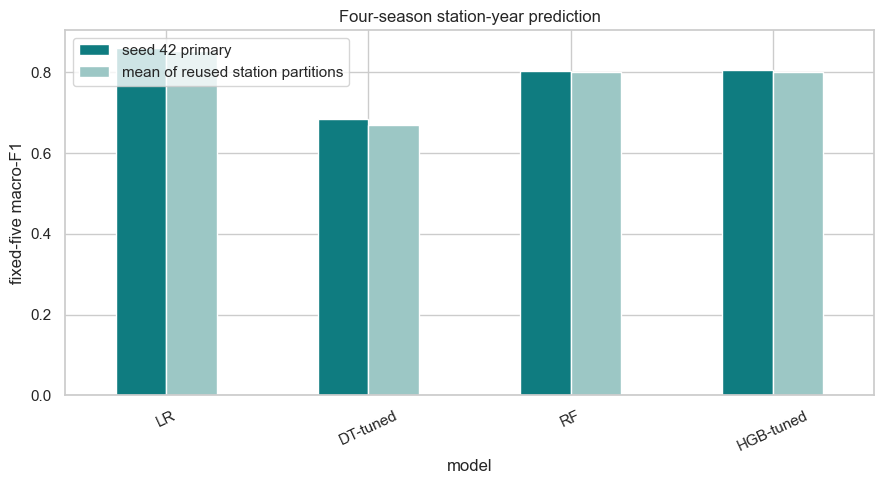

In [68]:
fig, ax = plt.subplots(figsize=(9, 5))
season_summary[["grouped_primary", "grouped_seed_mean"]].plot.bar(ax=ax, color=["#0f7c80", "#9cc7c5"])
ax.set(title="Four-season station-year prediction", ylabel="fixed-five macro-F1", xlabel="model")
ax.legend(["seed 42 primary", "mean of reused station partitions"])
plt.xticks(rotation=25); plt.tight_layout(); savefig("p7_seasonal_model_comparison"); plt.show()

In [69]:
season_class_rows = []
for kind in ["HGB-tuned", "LR"]:
    pred = SEASON_OOF[(kind, 42)]["pred"]
    p, r, f, s = precision_recall_fscore_support(season_y, pred, labels=ZONE_ORDER, zero_division=0)
    season_class_rows.extend({"model": kind, "zone": z, "precision": p[i], "recall": r[i],
                              "F1": f[i], "support": s[i]} for i, z in enumerate(ZONE_ORDER))
export_table("seasonal_per_class", pd.DataFrame(season_class_rows))

,model,zone,precision,recall,F1,support
0,HGB-tuned,Tropical,1.000000,0.960000,0.979592,25
1,HGB-tuned,Arid,0.704545,0.738095,0.720930,42
2,HGB-tuned,Subtropical,0.859813,0.867925,0.863850,106
3,HGB-tuned,Mediterranean,0.767123,0.727273,0.746667,77
4,HGB-tuned,Oceanic,0.712500,0.730769,0.721519,78
5,LR,Tropical,1.000000,1.000000,1.000000,25
6,LR,Arid,0.695652,0.761905,0.727273,42
7,LR,Subtropical,0.923077,0.905660,0.914286,106
8,LR,Mediterranean,0.851351,0.818182,0.834437,77
9,LR,Oceanic,0.822785,0.833333,0.828025,78


### 7.5 Matched baseline and interpretation

The daily baseline remains the primary first-impression result. For a more comparable station-year check, we also take
the daily HGB out-of-fold predictions in the four seasonal windows and use a deterministic majority vote across those
snapshots. This is still a daily model; it does not receive seasonal means or standard deviations. The comparison is
descriptive because the seasonal model predicts station-years while the headline daily score predicts individual days.

In [70]:
def nearest_snapshot_indices():
    lookup = []
    for _, row in seasonal.iterrows():
        station, year = row.station, int(row.year)
        sg = df.index[(groups == station) & (df.Date.dt.year == year)]
        chosen = []
        for month, day in SEASON_SPECS.values():
            centre = pd.Timestamp(year=year, month=month, day=day)
            candidates = sg[(df.loc[sg, "Date"] - centre).abs().dt.days <= SEASON_HALF_WINDOW]
            if len(candidates):
                chosen.append(candidates[np.argmin((df.loc[candidates, "Date"] - centre).abs().dt.days)])
        lookup.append(chosen)
    return lookup

snapshot_rows = nearest_snapshot_indices()
daily_pred = np.asarray(OOF[("HGB", 42)]["pred"], dtype=object)
snapshot_pred = []
for inds in snapshot_rows:
    votes = pd.Series(daily_pred[inds]).value_counts()
    snapshot_pred.append(sorted(votes.index, key=lambda z: (-votes[z], ZONE_ORDER.index(z)))[0])
snapshot_pred = np.asarray(snapshot_pred, dtype=object)
matched = pd.DataFrame([{
    "representation": "daily HGB majority over four nearest seasonal snapshots",
    "rows": len(seasonal), "macro_F1": macro5(season_y, snapshot_pred),
    "accuracy": accuracy_score(season_y, snapshot_pred),
}, {
    "representation": "seasonal HGB-tuned signature",
    "rows": len(seasonal), "macro_F1": seasonal_score(np.arange(len(seasonal)), SEASON_OOF[("HGB-tuned",42)]["pred"])["macro_F1"],
    "accuracy": accuracy_score(season_y, SEASON_OOF[("HGB-tuned",42)]["pred"]),
}])
export_table("seasonal_matched_baseline", matched)
matched.round(3)

,representation,rows,macro_F1,accuracy
0,daily HGB majority over four nearest seasonal ...,328,0.759,0.744
1,seasonal HGB-tuned signature,328,0.807,0.793


### 7.5.1 Same-model matched comparison

The matched comparison should keep the classifier fixed. Using the saved station-held-out daily OOF predictions, the majority vote over the four nearest seasonal snapshots gives macro-F1 **0.702** for daily LR and **0.759** for daily HGB. Therefore, seasonal LR (0.861) exceeds the same-model daily-LR vote by **0.159**, while seasonal HGB (0.807) exceeds the same-model daily-HGB vote by **0.047** (rounded values; exact differences are 0.158835 and 0.047079). The earlier LR-versus-HGB difference is not a like-for-like model comparison. The calculation is reproduced by `tools/compute_matched_votes.py` from `results/predictions.npz`.

### 7.6 Seasonal conclusions and limits

The seasonal signature is the main open-ended representation, but it is not automatically superior because it uses a
different unit and fewer observations than the daily table. The relevant evidence is the station-held-out comparison,
its repeated partition range, class-level errors and coverage diagnostics. A positive result supports the claim that
seasonal weather patterns contain more climate information than a snapshot. A weak or negative result is also informative:
four fixed dates may miss onset timing, extreme-event frequency or the longer climatological baseline.

The four dates are a transparent design choice rather than a physical law. We therefore retain the existing trailing-window
curves as a sensitivity analysis and do not claim that equinoxes or solstices are universally optimal. The external label
still comes from one map, only four stations are Tropical, and station-year rows do not create independent geographic
replicates.

### Completed-run findings

The daily snapshot baseline is intentionally retained as the first-impression reference. The predefined daily HGB
reaches 0.659 pooled station-held-out macro-F1 and 0.883
macro-AUC; the highest daily point estimate in the tested comparison is RF,
0.665. These scores are pooled over stations withheld from training, and
the three reused station partitions span 0.632--0.659
for HGB. Random row splits are easier because locations occur on both sides.

The main representation is a four-window station-year signature centred on the March equinox, June solstice, September
equinox and December solstice. It contains 444 candidate station-years, retains 73.6%
on average, and covers 48 stations. The strongest seasonal model is LR, with
0.861 macro-F1 and 0.973 macro-AUC. A matched
majority vote over four nearest daily HGB snapshots reaches 0.759, so the seasonal signature
adds temporal aggregation beyond four isolated observations in this station-held-out comparison.

Seasonal clustering remains exploratory: the best ARI in the $k=2,\ldots,7$ sweep is 0.314
(K-means, $k=7$). The seasonal t-SNE is descriptive because years from one station
repeat. Nested trailing-history selection gives LR 0.745 and HGB 0.758,
so the fixed-window history sensitivity remains supporting evidence rather than the paper's headline.

The 100-km training exclusion buffer lowers daily HGB to 0.565 on 142,451 rows. This
network-transfer stress test, four Tropical stations, the manually matched raster and station-year dependence limit
generalisation. No independent climate map or external station network has been added.


In [71]:
# Append seasonal arrays to the main prediction archive and include this section in the run audit.
pred_path = RESULT_DIR / "predictions.npz"
with np.load(pred_path, allow_pickle=False) as old:
    arrays = {k: old[k] for k in old.files}
for (kind, seed), obj in SEASON_OOF.items():
    arrays[f"seasonal_{kind}_s{seed}"] = np.asarray(obj["pred"], dtype=str)
arrays["seasonal_y"] = np.asarray(season_y, dtype=str)
arrays["seasonal_station"] = seasonal.station.to_numpy(dtype=str)
arrays["seasonal_year"] = seasonal.year.to_numpy(dtype=int)
pred_tmp = pred_path.with_name("predictions.seasonal.tmp.npz")
if pred_tmp.exists(): pred_tmp.unlink()
np.savez_compressed(pred_tmp, **arrays)
pred_tmp.replace(pred_path)
manifest = json.loads((RESULT_DIR / "run_manifest.json").read_text())
manifest.update({"seasonal_rows": int(len(seasonal)), "seasonal_stations": int(seasonal.station.nunique()),
                 "seasonal_windows": list(SEASON_SPECS), "cache_hits": int(sum(e["hit"] for e in CACHE_EVENTS)),
                 "cache_misses": int(sum(not e["hit"] for e in CACHE_EVENTS))})
(RESULT_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(json.dumps(manifest, indent=2))

{
  "run_id": "f67d019ce7acf9e9",
  "code_sha256": "179d4d0f51b196bbde187de730ac834c36b0d89a21d69f30081fd186b2cb2b83",
  "rows": 142451,
  "stations": 48,
  "outer_seeds": [
    42,
    0,
    7
  ],
  "outer_folds": 4,
  "metric": "pooled fixed-five macro-F1",
  "cache_hits": 383,
  "cache_misses": 0,
  "completed_utc": "2026-11-20T08:28:31.819614+00:00",
  "seasonal_rows": 328,
  "seasonal_stations": 48,
  "seasonal_windows": [
    "mar_equinox",
    "jun_solstice",
    "sep_equinox",
    "dec_solstice"
  ]
}
